# Predicting the Type of Employment from India's Periodic Labour Force Survey (PLFS)
## Part 1: Exploratory Data Analysis

**Project task:** Perform Exploratory Data Analysis (EDA) on India's Periodic Labour Force Survey (PLFS) unit-level microdata to predict the type of employment of working individuals (aged 15+).

**Data source:** Unit-level data of the Periodic Labour Force Survey (PLFS), July 2020 – June 2021 (Quarters Q5–Q8, Schedule 10.4), National Statistics Office (NSO), MoSPI, Government of India.

**Structure of the EDA:**
1. **Setup, Data Objects & Loading (Steps 1–4):** Household & Person data objects, schema verification, and cardinality.
2. **Data Quality & Relational Integrity (Steps 5–8):** Structural missingness (skip patterns), composite key integrity, relational joining, and data type validation.
3. **Target Definition & Modelling Population (Steps 9–13):** Current Weekly Status (CWS) mapping, earnings validation, population funnel, survey weights, and leakage control.
4. **Feature Engineering & DMS672 Attribute Taxonomy (Steps 14A–14B):** Translating survey codes, deriving ratio/ordinal variables, and classifying attributes into **Nominal, Symmetric Binary, Asymmetric Binary, Ordinal, Interval, and Ratio** scales.
5. **Basic Statistical Descriptions (Steps 15–16):** Central tendency (Mean, Trimmed Mean, Median, Mode), Dispersion (Range, IQR, Variance, SD), Shape (Skewness, Kurtosis, Modality), and **Distributive vs. Algebraic vs. Holistic** measures.
6. **Graphic Displays of Statistical Descriptions (Steps 17–21):** Bivariate stacked bars, **4-Step Boxplot Analysis** vs. **Violin Plots** , **Quantile Plots**, **Normal Q-Q Plots**, and **Two-Sample Q-Q Plots**.
7. **Multivariate Visualization & Feature Association (Steps 22A–22B):** Cramér's V, $\eta^2$, Spearman rank correlation heatmap, **Pair Plot (Scatterplot Matrix)**, and **Multi-Encoded Bubble Scatter Plot**.
8. **Measuring Data Similarity & Dissimilarity (Step 23):** Data Matrix vs. Dissimilarity Matrix, **Minkowski Distances ($L_1$ Manhattan, $L_2$ Euclidean, $L_\infty$ Chebyshev)**, **Jaccard Coefficient** for asymmetric binary attributes, **Normalized Rank Encoding** for ordinal attributes, **Gower's Mixed-Attribute Dissimilarity**, and **Cosine Similarity**.

### Step 1: Import libraries and set plotting style
Load the Python libraries used throughout the notebook and fix one colour for each employment type so every chart reads the same way: blue (`#2a78d6`) for **Self-employed**, orange (`#eb6834`) for **Regular salaried**, and green (`#1baf7a`) for **Casual labour**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, HTML

pd.set_option("display.max_columns", 80, "display.width", 220, "display.max_colwidth", 90)
pd.set_option("display.float_format", "{:,.2f}".format)

CLASSES = ["Self-employed", "Regular salaried", "Casual labour"] # the three target classes
CLS_COL = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a"]))  # fixed colour per class
INK, MUTED = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.edgecolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.labelcolor": INK, "legend.frameon": False
})

# Set DATA_DIR to the folder containing hhrv.csv, hhv1.csv, perrv.csv, perv1.csv
DATA_DIR = "."
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


### Step 2: Load the four PLFS data files (Data Objects & Dimensions)
In DMS672, a dataset consists of **data objects** (rows/records) described by **attributes** (columns/variables). Read `hhrv`, `hhv1`, `perrv`, and `perv1` as text (`category`) so Nominal/Identification codes with leading zeros (e.g. state `'09'`) are preserved without invalid numeric truncation. Compare the loaded $(n \times p)$ data matrix dimensions against the official NSO data catalogue.

In [2]:
FILES = {"hhrv": "hhrv.csv", "hhv1": "hhv1.csv", "perrv": "perrv.csv", "perv1": "perv1.csv"}
OFFICIAL = {"hhrv": (129887, 32), "hhv1": (100344, 37), "perrv": (510580, 104), "perv1": (413405, 159)}
LEVEL = {
    "hhrv": "Household - revisit (visits 2-4)",
    "hhv1": "Household - first visit",
    "perrv": "Person - revisit (visits 2-4)",
    "perv1": "Person - first visit"
}

raw = {k: pd.read_csv(f"{DATA_DIR}/{f}", dtype="category", low_memory=False) for k, f in FILES.items()}

summary = pd.DataFrame([{
    "Data file": k,
    "Data Object (Level)": LEVEL[k],
    "Objects n (loaded)": raw[k].shape[0],
    "Attributes p (loaded)": raw[k].shape[1],
    "Objects n (catalogue)": OFFICIAL[k][0],
    "Attributes p (catalogue)": OFFICIAL[k][1],
    "Matches catalogue": raw[k].shape == OFFICIAL[k]
} for k in FILES])

display(summary.style.format({"Objects n (loaded)": "{:,}", "Objects n (catalogue)": "{:,}"}).hide(axis="index"))
print(
    "Total person records:", f"{raw['perv1'].shape[0] + raw['perrv'].shape[0]:,}",
    "| Total household records:", f"{raw['hhv1'].shape[0] + raw['hhrv'].shape[0]:,}"
)

Data file,Data Object (Level),Objects n (loaded),Attributes p (loaded),Objects n (catalogue),Attributes p (catalogue),Matches catalogue
hhrv,Household - revisit (visits 2-4),"129,887",32,"129,887",32,True
hhv1,Household - first visit,"100,344",37,"100,344",37,True
perrv,Person - revisit (visits 2-4),"510,580",104,"510,580",104,True
perv1,Person - first visit,"413,405",159,"413,405",159,True


Total person records: 923,985 | Total household records: 230,231


### Step 3: Data dictionary: variables and labels of every file
Print the variable list and human-readable label of each file. The revisit person file (`perrv`, $p=104$) has fewer attributes than the first-visit person file (`perv1`, $p=159$) because it omits the Usual Status block (`b5*`), Migration block (`b7*`), and detailed Vocational Training block (`b4pt1*`). Any feature used across both files must come from their shared blocks: **Demographics (`b4*`)** and **Current Weekly Activity (`b6*`)**.

In [3]:
STRIP = re.compile(r"_(perv1|perrv|pervv|hhv1|hhrv)$")

LABEL = {
    # identification / sampling
    "FI": "File Identification", "B1q2": "Schedule", "qtr": "Quarter", "visit": "Visit", "b1q3": "Sector",
    "state": "State/UT Code", "distcode": "District Code", "dist_code": "District Code", "nss_region": "NSS-Region",
    "b1q5": "Stratum", "b1q6": "Sub-Stratum", "b1q11": "Sub-Sample", "b1q12": "FOD Sub-Region", "b1q1": "FSU",
    "b1q13": "Sample Sg/Sb No.", "b1q14": "Second Stage Stratum No.", "b1q15": "Sample Household Number",
    "NSS": "NS count for sector x stratum x substratum x sub-sample",
    "NSC": "NS count for sector x stratum x substratum",
    "mult": "Sub-sample wise Multiplier",
    "no_qtr": "Occurrence of FSUs in State x Sector x Stratum x Sub-Stratum in 4 Quarters",
    # household block
    "b1q9": "Month of survey", "b1q16": "Survey administration code (Block 1, item 16)",
    "b1q17": "Response code (informant)", "b1q18": "Survey status code (Block 1, item 18)",
    "b1q19": "Reason code if survey status = 2", "b2q2i": "Date of survey (ddmmyyyy)",
    "b2q4": "Time taken to canvass the schedule (minutes)", "b3q1": "Household Size",
    "b3q2": "Household Type", "b3q3": "Religion of the Household", "b3q4": "Social Group of the Household",
    "b3q5": "Household usual monthly consumer expenditure (Rs.)",
    "b3q5pt1": "Household usual monthly consumer expenditure - component 1 (Rs.)",
    "b3q5pt2": "Household usual monthly consumer expenditure - component 2 (Rs.)",
    "b3q5pt3": "Household usual monthly consumer expenditure - component 3 (Rs.)",
    "b3q5pt4": "Household usual monthly consumer expenditure - component 4 (Rs.)",
    "b3q5pt5": "Household usual monthly consumer expenditure - component 5 (Rs.)",
    "b3q5pt6": "Household usual monthly consumer expenditure - total (Rs.)",
    # person demographics
    "b4q1": "Person Serial No.", "b4q4": "Relationship To Head", "b4q5": "Sex", "b4q6": "Age",
    "b4q7": "Marital Status", "b4q8": "General Education Level", "b4q9": "Technical Education Level",
    "b4q10": "No. of years in Formal Education",
    "b4q11": "Status of Current Attendance in Educational Institution",
    "b4q12": "Whether received any Vocational/Technical Training",
    "b4pt1q3": "Whether Training completed during last 365 Days", "b4pt1q4": "Field Of Training",
    "b4pt1q5": "Duration Of Training", "b4pt1q6": "Type Of Training", "b4pt1q7": "Source Of Funding The Training",
    # usual status (first visit only)
    "b5pt1q3": "Usual Principal Activity Status Code", "b5pt1q5": "Usual Principal Activity Industry Code (NIC)",
    "b5pt1q6": "Usual Principal Activity Occupation Code (NCO)",
    "b5pt1q7": "Whether Engaged In Any Work In Subsidiary Capacity",
    "b5pt1q8": "(Principal) Location Of Workplace Code", "b5pt1q9": "(Principal) Enterprise Type Code",
    "b5pt1q10": "(Principal) No. Of Workers In The Enterprise", "b5pt1q11": "(Principal) Type Of Job Contract",
    "b5pt1q12": "(Principal) Eligible Of Paid Leave", "b5pt1q13": "(Principal) Social Security Benefits",
    "b5pt1q14": "(Principal) Usage of product of the economic activity",
    "b5pt2q3": "Subsidiary Activity Status Code", "b5pt2q5": "Subsidiary Activity Industry Code (NIC)",
    "b5pt2q6": "Subsidiary Activity Occupation Code (NCO)", "b5pt2q7": "(Subsidiary) Location Of Workplace Code",
    "b5pt2q8": "(Subsidiary) Enterprise Type Code", "b5pt2q9": "(Subsidiary) No. Of Workers In The Enterprise",
    "b5pt2q10": "(Subsidiary) Type Of Job Contract", "b5pt2q11": "(Subsidiary) Eligible Of Paid Leave",
    "b5pt2q12": "(Subsidiary) Social Security Benefits",
    "b5pt2q13": "(Subsidiary) Usage of product of the economic activity",
    "b5pt3q5": "Ever Worked Prior to last 365 days",
    "b5pt3q6": "Duration of engagement in usual Principal Activity Status",
    "b5pt3q7": "Duration of engagement in Subsidiary Activity Status",
    "b5pt3q8": "Efforts undertaken to search work", "b5pt3q9": "Duration of spell of Unemployment",
    "b5pt3q10": "Whether Ever Worked", "b5pt3q11": "Reason for not working in last 365 days",
    "b5pt3q12": "Main reason for being in Principal activity status (91 to 97)",
    # current weekly status block
    "b6q5": "Current Weekly Status (CWS)", "b6q6": "Industry Code (CWS)", "b6q7": "Occupation Code (CWS)",
    "b6q9": "Earnings For Regular Salaried/Wage Activity", "b6q10": "Earnings From Self-Employment Activity",
    # migration
    "b7pt1_q3": "Whether Present place of enumeration differs from last usual place of residence",
    "b7pt1_q4": "Whether moved to Present place of enumeration after March 2020",
    "b7pt1_q5": "Whether Present place of enumeration was usual place of residence in Past",
    "b7pt1_q6": "Location of last usual place of residence",
    "b7pt1_q8": "State code of last usual place of residence",
    "b7pt1_q9": "Reason for leaving the last usual place of residence",
    "b7pt1_q10": "Intention to move out from present place of residence",
    "b7pt1_q11": "Usual Principal Activity Status of last usual place of residence",
    "b7pt1_q12": "Industry Division (NIC 2 digit)", "b7pt1_q13": "Occupation Group (NCO-2004 3 digit)",
    "b7pt2_q5": "Highest level of Education",
    "b7pt2_q6": "Whether Present place of residence differs from Usual place of residence",
    "b7pt2_q7": "Whether Present place of residence was usual place of residence in Past",
    "b7pt2_q8": "Location of last usual place of residence",
    "b7pt2_q10": "State code of last usual place of residence",
    "b7pt2_q11": "Reason for leaving the last usual place of residence",
    "b7pt2_q12": "Returned or intention to return to last usual place of residence",
    "b7pt2_q13": "Usual Principal Activity Status of last usual place of residence",
    "b7pt2_q14": "Industry Division (NIC 2 digit)", "b7pt2_q15": "Occupation Group (NCO-2004 3 digit)"
}

ORD = {1: "1st", 2: "2nd", 3: "3rd"}

def label_of(col):
    base = STRIP.sub("", col)
    m = re.match(r"b6q(\d+)(_act2)?_3pt(\d)", base)
    if m:
        q, act2, k = m.group(1), bool(m.group(2)), int(m.group(3))
        day = 8 - k
        dtxt = ORD.get(day, f"{day}th") + " day of reference week"
        act = "activity 2" if act2 else "activity 1"
        txt = {
            "4": f"Status Code for {act}", "5": f"Industry Code (NIC) for {act}",
            "6": f"Hours actually worked for {act}", "9": f"Wage earning for {act}",
            "7": "Total hours actually worked", "8": "Hours available for additional work"
        }[q]
        return f"{txt} - {dtxt}"
    if base == "b4q1_pervv":
        base = "b4q1"
    return LABEL.get(base, LABEL.get(base.split("_")[0], base))

dictionary = {}
for k in ["hhrv", "hhv1", "perrv", "perv1"]:
    d_dict = pd.DataFrame({"Variable": raw[k].columns, "Label": [label_of(c) for c in raw[k].columns]})
    d_dict.insert(0, "#", range(1, len(d_dict) + 1))
    dictionary[k] = d_dict
    print(f"\nData file: {k} | Objects: {raw[k].shape[0]:,} | Attributes: {raw[k].shape[1]}")
    display(d_dict.head(15).style.hide(axis="index")) # Show first 15 rows per file (change to d_dict to print all)


Data file: hhrv | Objects: 129,887 | Attributes: 32


#,Variable,Label
1,FI_hhrv,File Identification
2,B1q2_hhrv,Schedule
3,qtr_hhrv,Quarter
4,visit_hhrv,Visit
5,b1q3_hhrv,Sector
6,state_hhrv,State/UT Code
7,distcode_hhrv,District Code
8,nss_region_hhrv,NSS-Region
9,b1q5_hhrv,Stratum
10,b1q6_hhrv,Sub-Stratum



Data file: hhv1 | Objects: 100,344 | Attributes: 37


#,Variable,Label
1,FI_hhv1,File Identification
2,B1q2_hhv1,Schedule
3,qtr_hhv1,Quarter
4,visit_hhv1,Visit
5,b1q3_hhv1,Sector
6,state_hhv1,State/UT Code
7,distcode_hhv1,District Code
8,nss_region_hhv1,NSS-Region
9,b1q5_hhv1,Stratum
10,b1q6_hhv1,Sub-Stratum



Data file: perrv | Objects: 510,580 | Attributes: 104


#,Variable,Label
1,FI_perrv,File Identification
2,B1q2_perrv,Schedule
3,qtr_perrv,Quarter
4,visit_perrv,Visit
5,b1q3_perrv,Sector
6,state_perrv,State/UT Code
7,dist_code_perrv,District Code
8,nss_region_perrv,NSS-Region
9,b1q5_perrv,Stratum
10,b1q6_perrv,Sub-Stratum



Data file: perv1 | Objects: 413,405 | Attributes: 159


#,Variable,Label
1,FI_perv1,File Identification
2,B1q2_perv1,Schedule
3,qtr_perv1,Quarter
4,visit_perv1,Visit
5,b1q3_perv1,Sector
6,state_perv1,State/UT Code
7,distcode_perv1,District Code
8,nss_region_perv1,NSS-Region
9,b1q5_perv1,Stratum
10,b1q6_perv1,Sub-Stratum


### Step 4: Structure of the files: first rows and key columns
Inspect the first 4 records of each file and the cardinality (number of distinct values) of the key identification columns. Notice that `hhrv` and `perrv` have only `1` distinct sector code (`2` = Urban) because only urban households are revisited in visits V2–V4.

In [4]:
for k in ["hhv1", "hhrv", "perv1", "perrv"]:
    print(f"--- {k}: first 4 records, first 12 columns ---")
    display(raw[k].iloc[:4, :12])

key_cols = {
    "FSU (village/block)": "b1q1", "Sample household no.": "b1q15",
    "Quarter": "qtr", "Visit": "visit", "Sector": "b1q3", "State": "state"
}
rows = []
for k, sfx in [("hhv1", "hhv1"), ("hhrv", "hhrv"), ("perv1", "perv1"), ("perrv", "perrv")]:
    r = {"File": k}
    for name, base in key_cols.items():
        r[name] = raw[k][f"{base}_{sfx}"].nunique()
    rows.append(r)

print("Number of distinct codes in the key columns:")
display(pd.DataFrame(rows).set_index("File"))

--- hhv1: first 4 records, first 12 columns ---


,FI_hhv1,B1q2_hhv1,qtr_hhv1,visit_hhv1,b1q3_hhv1,state_hhv1,distcode_hhv1,nss_region_hhv1,b1q5_hhv1,b1q6_hhv1,b1q11_hhv1,b1q12_hhv1
0,FVH4,104,Q5,V1,1,14,05,141,01,08,2,MAN
1,FVH4,104,Q5,V1,1,14,05,141,01,08,2,MAN
2,FVH4,104,Q5,V1,1,14,05,141,01,08,2,MAN
3,FVH4,104,Q5,V1,1,14,05,141,01,08,2,MAN


--- hhrv: first 4 records, first 12 columns ---


,FI_hhrv,B1q2_hhrv,qtr_hhrv,visit_hhrv,b1q3_hhrv,state_hhrv,distcode_hhrv,nss_region_hhrv,b1q5_hhrv,b1q6_hhrv,b1q11_hhrv,b1q12_hhrv
0,RVH4,104,Q5,V2,2,33,32,334,04,03,2,3310
1,RVH4,104,Q5,V2,2,33,32,334,04,03,2,3310
2,RVH4,104,Q5,V2,2,33,32,334,04,03,2,3310
3,RVH4,104,Q5,V2,2,33,32,334,04,03,2,3310


--- perv1: first 4 records, first 12 columns ---


,FI_perv1,B1q2_perv1,qtr_perv1,visit_perv1,b1q3_perv1,state_perv1,distcode_perv1,nss_region_perv1,b1q5_perv1,b1q6_perv1,b1q11_perv1,b1q12_perv1
0,FVP4,104,Q5,V1,1,14,05,141,01,08,2,MAN
1,FVP4,104,Q5,V1,1,14,05,141,01,08,2,MAN
2,FVP4,104,Q5,V1,1,14,05,141,01,08,2,MAN
3,FVP4,104,Q5,V1,1,14,05,141,01,08,2,MAN


--- perrv: first 4 records, first 12 columns ---


,FI_perrv,B1q2_perrv,qtr_perrv,visit_perrv,b1q3_perrv,state_perrv,dist_code_perrv,nss_region_perrv,b1q5_perrv,b1q6_perrv,b1q11_perrv,b1q12_perrv
0,RVP4,104,Q5,V2,2,33,32,334,04,03,2,3310
1,RVP4,104,Q5,V2,2,33,32,334,04,03,2,3310
2,RVP4,104,Q5,V2,2,33,32,334,04,03,2,3310
3,RVP4,104,Q5,V2,2,33,32,334,04,03,2,3310


Number of distinct codes in the key columns:


,FSU (village/block),Sample household no.,Quarter,Visit,Sector,State
File,,,,,,
hhv1,12562,8,4,1,2,36
hhrv,5640,8,4,3,1,35
perv1,12562,8,4,1,2,36
perrv,5640,8,4,3,1,35


### Step 5: Missing values in the raw files
Measure how much of each raw file is empty. In complex survey microdata, most blanks represent **structural skip patterns** (e.g., Activity 2 on each day is blank for 99.6% of persons because very few people hold two jobs on the same day; the migration block is asked only to migrants) rather than random data collection errors. Only 2,587 records in `perv1` (0.63%) lack a Current Weekly Status (`b6q5`).

,Columns with any missing,Columns > 50% missing,Columns 100% missing,Overall % cells missing
hhrv,3,1,1,3.13
hhv1,3,1,0,2.45
perrv,29,24,0,19.87
perv1,91,72,0,40.89


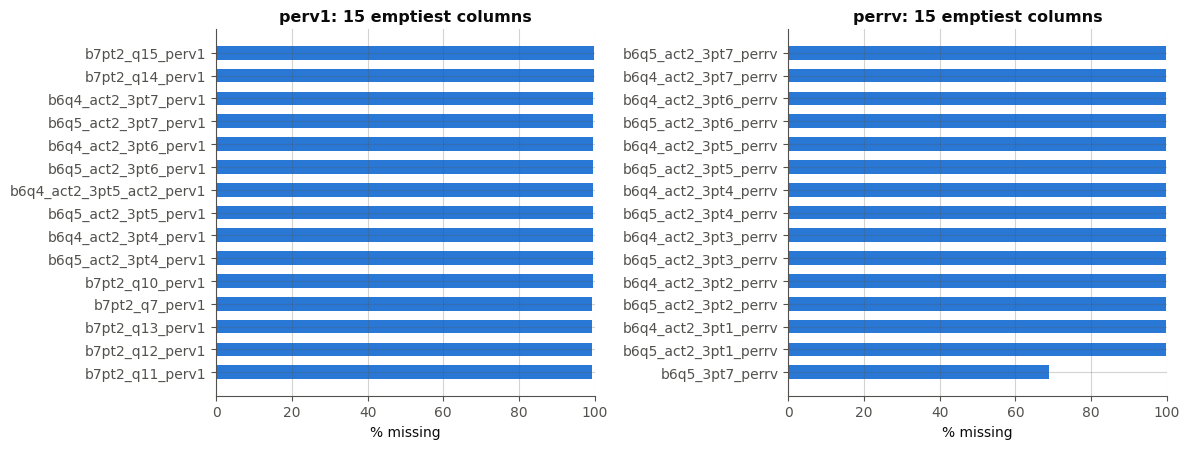

perv1: 2,587 person records have no Current Weekly Status (0.63% of the file)
perrv: 0 person records have no Current Weekly Status (0.00% of the file)
hhrv variable with 100% missing: ['b1q19_hhrv']


In [5]:
miss = {k: raw[k].isna().mean().mul(100).sort_values(ascending=False) for k in raw}
tbl = pd.DataFrame({
    k: {
        "Columns with any missing": int((v > 0).sum()),
        "Columns > 50% missing": int((v > 50).sum()),
        "Columns 100% missing": int((v == 100).sum()),
        "Overall % cells missing": raw[k].isna().to_numpy().mean() * 100
    } for k, v in miss.items()
}).T
display(tbl.astype({"Columns with any missing": int, "Columns > 50% missing": int, "Columns 100% missing": int}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, k in zip(axes, ["perv1", "perrv"]):
    top = miss[k].head(15)[::-1]
    ax.barh(top.index, top.values, color="#2a78d6", height=0.6)
    ax.set_title(f"{k}: 15 emptiest columns")
    ax.set_xlabel("% missing")
    ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

for k, sfx in [("perv1", "perv1"), ("perrv", "perrv")]:
    n = raw[k][f"b6q5_{sfx}"].isna().sum()
    print(f"{k}: {n:,} person records have no Current Weekly Status ({n / len(raw[k]) * 100:.2f}% of the file)")
print("hhrv variable with 100% missing:", [c for c in raw["hhrv"].columns if raw["hhrv"][c].isna().all()])

### Step 6: Duplicates and key integrity
Check for fully duplicated rows and verify that the composite primary key (`FSU + sub-sample + second-stage stratum + household number + quarter + visit [+ person serial no.]`) uniquely identifies every household and person object.

In [6]:
hk1 = ["b1q1_hhv1", "b1q13_hhv1", "b1q14_hhv1", "b1q15_hhv1", "qtr_hhv1"]
hkr = ["b1q1_hhrv", "b1q13_hhrv", "b1q14_hhrv", "b1q15_hhrv", "qtr_hhrv", "visit_hhrv"]
pk1 = ["b1q1_perv1", "b1q13_perv1", "b1q14_perv1", "b1q15_perv1", "qtr_perv1", "b4q1_perv1"]
pkr = ["b1q1_perrv", "b1q13_perrv", "b1q14_perrv", "b1q15_perrv", "qtr_perrv", "visit_perrv", "b4q1_pervv"]

checks = []
for k, key in [("hhv1", hk1), ("hhrv", hkr), ("perv1", pk1), ("perrv", pkr)]:
    checks.append({
        "File": k,
        "Fully duplicated rows": int(raw[k].duplicated().sum()),
        "Duplicate ID keys": int(raw[k].duplicated(subset=key).sum()),
        "ID key used": " + ".join(c.rsplit("_", 1)[0] for c in key)
    })
display(pd.DataFrame(checks).set_index("File"))

,Fully duplicated rows,Duplicate ID keys,ID key used
File,,,
hhv1,0,0,b1q1 + b1q13 + b1q14 + b1q15 + qtr
hhrv,0,0,b1q1 + b1q13 + b1q14 + b1q15 + qtr + visit
perv1,0,0,b1q1 + b1q13 + b1q14 + b1q15 + qtr + b4q1
perrv,0,0,b1q1 + b1q13 + b1q14 + b1q15 + qtr + visit + b4q1


### Step 7: Combine the two person files and attach household information
Harmonise column names between `perv1` and `perrv`, concatenate the person tables ($N = 923,985$), and perform a `many_to_one` relational left-join to attach household attributes (`hh_size`, `hh_type`, `religion`, `social_group`, `hh_exp`). Verify the panel overlap across visits (`hh_id`).

In [7]:
PMAP = {
    "fsu": ("b1q1_perv1", "b1q1_perrv"), "sg": ("b1q13_perv1", "b1q13_perrv"),
    "stage2": ("b1q14_perv1", "b1q14_perrv"), "hh_no": ("b1q15_perv1", "b1q15_perrv"),
    "qtr": ("qtr_perv1", "qtr_perrv"), "visit": ("visit_perv1", "visit_perrv"),
    "sector": ("b1q3_perv1", "b1q3_perrv"), "state": ("state_perv1", "state_perrv"),
    "stratum": ("b1q5_perv1", "b1q5_perrv"), "person_no": ("b4q1_perv1", "b4q1_pervv"),
    "relation": ("b4q4_perv1", "b4q4_perrv"), "sex": ("b4q5_perv1", "b4q5_perrv"),
    "age": ("b4q6_perv1", "b4q6_perrv"), "marital": ("b4q7_perv1", "b4q7"),
    "gen_edu": ("b4q8_perv1", "b4q8_perrv"), "tech_edu": ("b4q9_perv1", "b4q9_perrv"),
    "edu_years": ("b4q10_perv1", "b4q10_perrv"), "attend": ("b4q11_perv1", "b4q11_perrv"),
    "voc_training": ("b4q12_perv1", None),
    "cws": ("b6q5_perv1", "b6q5_perrv"), "ind_nic": ("b6q6_perv1", "b6q6_perrv"),
    "occ_nco": ("b6q7_perv1", "b6q7_perrv"), "earn_sal": ("b6q9_perv1", "b6q9_perrv"),
    "earn_self": ("b6q10_perv1", "b6q10_perrv"), "mult": ("mult_perv1", "mult_perrv"),
    "nss": ("NSS_perv1", "NSS_perrv"), "nsc": ("NSC_perv1", "NSC_perrv")
}

def find(df_in, prefix):
    c = [x for x in df_in.columns if x.startswith(prefix + "_") or x == prefix]
    assert len(c) == 1, (prefix, c)
    return c[0]

for d_day in range(1, 8):
    PMAP[f"hrs_d{d_day}"] = (find(raw["perv1"], f"b6q7_3pt{d_day}"), find(raw["perrv"], f"b6q7_3pt{d_day}"))
    PMAP[f"extra_d{d_day}"] = (find(raw["perv1"], f"b6q8_3pt{d_day}"), find(raw["perrv"], f"b6q8_3pt{d_day}"))
PMAP["dist"] = ("distcode_perv1", "dist_code_perrv")

def harmonise(df_in, i, source):
    out = pd.DataFrame({k: (df_in[v[i]].astype(object) if v[i] else np.nan) for k, v in PMAP.items()})
    out["source"] = source
    return out

persons = pd.concat([harmonise(raw["perv1"], 0, "First visit"), harmonise(raw["perrv"], 1, "Revisit")], ignore_index=True)

HMAP = {
    "fsu": ("b1q1_hhv1", "b1q1_hhrv"), "sg": ("b1q13_hhv1", "b1q13_hhrv"),
    "stage2": ("b1q14_hhv1", "b1q14_hhrv"), "hh_no": ("b1q15_hhv1", "b1q15_hhrv"),
    "qtr": ("qtr_hhv1", "qtr_hhrv"), "visit": ("visit_hhv1", "visit_hhrv"),
    "hh_size": ("b3q1_hhv1", "b3q1_hhrv"), "hh_type": ("b3q2_hhv1", "b3q2_hhrv"),
    "religion": ("b3q3_hhv1", "b3q3_hhrv"), "social_group": ("b3q4_hhv1", "b3q4_hhrv"),
    "hh_exp": ("b3q5pt6_hhv1", "b3q5_hhrv")
}

hh = pd.concat([
    pd.DataFrame({k: raw["hhv1"][v[0]].astype(object) for k, v in HMAP.items()}),
    pd.DataFrame({k: raw["hhrv"][v[1]].astype(object) for k, v in HMAP.items()})
], ignore_index=True)

KEY = ["fsu", "sg", "stage2", "hh_no", "qtr", "visit"]
before = len(persons)
df = persons.merge(hh, on=KEY, how="left", validate="many_to_one", indicator=True)
print("Persons before join:", f"{before:,}", "| after join:", f"{len(df):,}")
print("Join result:", df["_merge"].value_counts().to_dict())
df = df.drop(columns="_merge")

df["hh_id"] = df["fsu"].astype(str) + "-" + df["sg"].astype(str) + "-" + df["stage2"].astype(str) + "-" + df["hh_no"].astype(str)
v1_ids = set(df.loc[df.source == "First visit", "hh_id"])
rv_ids = set(df.loc[df.source == "Revisit", "hh_id"])
print(f"\nDistinct households: first visit {len(v1_ids):,} | revisit {len(rv_ids):,} | present in both {len(v1_ids & rv_ids):,}")
print(f"Person rows per household id (mean): {len(df) / df.hh_id.nunique():.2f}")
print("Persons by visit:", df["visit"].value_counts().sort_index().to_dict())
del persons, hh
gc.collect()

Persons before join: 923,985 | after join: 923,985
Join result: {'both': 923985, 'left_only': 0, 'right_only': 0}

Distinct households: first visit 100,344 | revisit 46,745 | present in both 43,270
Person rows per household id (mean): 8.90
Persons by visit: {'V1': 413405, 'V2': 172509, 'V3': 169699, 'V4': 168372}


48

### Step 8: Fix data types and check code validity
Convert quantitative attributes (`age`, `edu_years`, `hh_size`, `hh_exp`, `earn_sal`, `earn_self`, daily hours, sampling multipliers) from text to numeric types, while keeping Nominal/Ordinal codes as strings so invalid arithmetic is prevented. Verify domain bounds across all attributes.

In [8]:
NUM = (
    ["age", "edu_years", "earn_sal", "earn_self", "mult", "nss", "nsc", "hh_size", "hh_exp"]
    + [f"hrs_d{d}" for d in range(1, 8)]
    + [f"extra_d{d}" for d in range(1, 8)]
)
for c in NUM:
    df[c] = pd.to_numeric(df[c], errors="coerce")

rng = df[["age", "edu_years", "hh_size", "hh_exp", "earn_sal", "earn_self", "hrs_d1", "extra_d1"]].agg(
    ["count", "min", "median", "mean", "max"]
).T
rng["missing"] = df[rng.index].isna().sum()
display(rng)

valid = pd.DataFrame({
    "Sector codes found": [sorted(df.sector.dropna().unique())],
    "Sex codes found": [sorted(df.sex.dropna().unique())],
    "Marital codes found": [sorted(df.marital.dropna().unique())],
    "Social group codes": [sorted(df.social_group.dropna().unique())],
    "Religion codes": [sorted(df.religion.dropna().unique())]
}).T.rename(columns={0: "Values"})
display(valid)
print("Persons aged 0-14:", f"{(df.age < 15).sum():,}", "| aged 15+:", f"{(df.age >= 15).sum():,}", "| age > 100:", int((df.age > 100).sum()))

,count,min,median,mean,max,missing
age,"923,979.00",0.00,30.00,31.78,110.00,6
edu_years,"923,985.00",0.00,8.00,7.54,29.00,0
hh_size,"923,985.00",1.00,5.00,4.84,24.00,0
hh_exp,"923,985.00",456.00,"10,238.00","12,448.49","5,013,869.00",0
earn_sal,"923,985.00",0.00,0.00,"2,532.38","2,000,000.00",0
earn_self,"923,985.00","-200,000.00",0.00,"1,632.23","850,000.00",0
hrs_d1,"923,985.00",0.00,0.00,2.33,20.00,0
extra_d1,"923,985.00",0.00,0.00,0.01,11.00,0


,Values
Sector codes found,"[1, 2]"
Sex codes found,"[1, 2, 3]"
Marital codes found,"[1, 2, 3, 4]"
Social group codes,"[1, 2, 3, 9]"
Religion codes,"[1, 2, 3, 4, 5, 6, 7, 9]"


Persons aged 0-14: 201,388 | aged 15+: 722,591 | age > 100: 56


### Step 9: Define the target: Current Weekly Status codes and employment type
Map the Current Weekly Status (`cws`, variable `b6q5`) into the three target employment classes (**Self-employed**, **Regular salaried**, **Casual labour**), plus non-employed categories (*Unemployed*, *Not in labour force*) for population overview.

code,meaning,group,persons,% of persons
91,Attended educational institution,Not in labour force,"239,450",25.91
92,Domestic duties only,Not in labour force,"169,960",18.39
31,Regular salaried / wage employee,Regular salaried,"111,479",12.07
11,Own-account worker,Self-employed,"106,265",11.50
99,Child below 5 years,Not in labour force,"57,110",6.18
51,Casual wage labour - other types of work,Casual labour,"43,600",4.72
94,Rentier / pensioner / remittance recipient,Not in labour force,"42,386",4.59
93,Domestic duties and free collection of goods,Not in labour force,"37,077",4.01
81,Unemployed - sought work,Unemployed,"32,278",3.49
21,Helper in household enterprise (unpaid family worker),Self-employed,"29,100",3.15


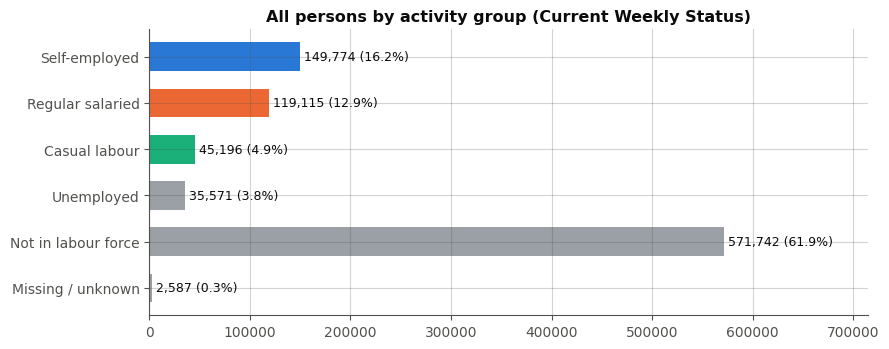

In [9]:
STATUS_MAP = {
    "11": ("Own-account worker", "Self-employed"),
    "12": ("Employer", "Self-employed"),
    "21": ("Helper in household enterprise (unpaid family worker)", "Self-employed"),
    "61": ("Self-employed work, temporarily absent (code 61)", "Self-employed"),
    "62": ("Self-employed work, temporarily absent (code 62)", "Self-employed"),
    "31": ("Regular salaried / wage employee", "Regular salaried"),
    "71": ("Regular salaried, temporarily absent (code 71)", "Regular salaried"),
    "72": ("Regular salaried, temporarily absent (code 72)", "Regular salaried"),
    "41": ("Casual wage labour - public works (code 41)", "Casual labour"),
    "42": ("Casual wage labour - public works (code 42)", "Casual labour"),
    "51": ("Casual wage labour - other types of work", "Casual labour"),
    "81": ("Unemployed - sought work", "Unemployed"),
    "82": ("Unemployed - did not seek but available", "Unemployed"),
    "91": ("Attended educational institution", "Not in labour force"),
    "92": ("Domestic duties only", "Not in labour force"),
    "93": ("Domestic duties and free collection of goods", "Not in labour force"),
    "94": ("Rentier / pensioner / remittance recipient", "Not in labour force"),
    "95": ("Not able to work due to disability", "Not in labour force"),
    "97": ("Other (including begging)", "Not in labour force"),
    "98": ("Other not working (code 98)", "Not in labour force"),
    "99": ("Child below 5 years", "Not in labour force")
}

df["cws_group"] = df["cws"].map(lambda c: STATUS_MAP.get(c, (None, "Missing / unknown"))[1])
t = df["cws"].value_counts(dropna=False).rename_axis("code").reset_index(name="persons")
t["code"] = t["code"].fillna("(blank)")
t["meaning"] = t["code"].map(lambda c: STATUS_MAP.get(c, ("(no status recorded)", ""))[0])
t["group"] = t["code"].map(lambda c: STATUS_MAP.get(c, ("", "Missing / unknown"))[1])
t["% of persons"] = t["persons"] / t["persons"].sum() * 100
display(t[["code", "meaning", "group", "persons", "% of persons"]].style.format({"persons": "{:,}", "% of persons": "{:.2f}"}).hide(axis="index"))

g = df["cws_group"].value_counts().reindex(CLASSES + ["Unemployed", "Not in labour force", "Missing / unknown"])
fig, ax = plt.subplots(figsize=(9, 3.6))
cols = [CLS_COL.get(i, "#9aa0a6") for i in g.index]
ax.barh(g.index[::-1], g.values[::-1], color=cols[::-1], height=0.62)
for y_pos, v in enumerate(g.values[::-1]):
    ax.text(v, y_pos, f" {v:,} ({v / g.sum() * 100:.1f}%)", va="center", fontsize=9, color=INK)
ax.set_title("All persons by activity group (Current Weekly Status)")
ax.set_xlim(0, g.max() * 1.25)
plt.tight_layout()
plt.show()

### Step 10: Check that the status-code grouping is correct (earnings test)
Verify that temporarily absent workers (codes `61, 62, 71, 72`) belong to their assigned classes using the earnings columns: `61` and `62` report self-employment earnings (`earn_self > 0`) and 0% salary, whereas `71` and `72` report regular salary (`earn_sal > 0`) and 0% self-employment earnings.

In [10]:
emp_codes = [c for c, (_, grp) in STATUS_MAP.items() if grp in CLASSES]
e = df[df.cws.isin(emp_codes)].copy()
chk = (
    e.assign(
        has_salary=e.earn_sal > 0,
        has_selfearn=e.earn_self > 0,
        hours_week=e[[f"hrs_d{d}" for d in range(1, 8)]].sum(axis=1)
    )
    .groupby("cws")
    .agg(
        persons=("cws", "size"),
        share_with_salary=("has_salary", "mean"),
        share_with_self_employment_earnings=("has_selfearn", "mean"),
        mean_hours_week=("hours_week", "mean")
    )
)
chk["assigned_group"] = chk.index.map(lambda c: STATUS_MAP[c][1])
chk[["share_with_salary", "share_with_self_employment_earnings"]] *= 100
display(
    chk.rename(columns={
        "share_with_salary": "% with salary",
        "share_with_self_employment_earnings": "% with self-emp. earnings"
    })[["assigned_group", "persons", "% with salary", "% with self-emp. earnings", "mean_hours_week"]]
)
del e

,assigned_group,persons,% with salary,% with self-emp. earnings,mean_hours_week
cws,,,,,
11,Self-employed,106265,0.00,99.24,48.97
12,Self-employed,7526,0.00,99.20,51.88
21,Self-employed,29100,0.00,0.00,40.23
31,Regular salaried,111479,99.49,0.00,51.01
41,Casual labour,917,0.00,0.00,42.43
42,Casual labour,679,0.00,0.00,37.77
51,Casual labour,43600,0.00,0.00,43.44
61,Self-employed,245,0.00,71.43,6.86
62,Self-employed,6638,0.00,64.21,8.27


### Step 11: Build the modelling population: employed persons aged 15 and above
Filter the 923,985 total person records to employed individuals aged 15 and above ($n = 313,759$).

In [11]:
f0 = len(df)
f1 = df.cws.notna().sum()
emp_mask = df.cws_group.isin(CLASSES)
f2 = emp_mask.sum()
age_mask = df.age >= 15
f3 = (emp_mask & age_mask).sum()

funnel = pd.DataFrame({
    "Step": [
        "All person records (first visit + revisit)",
        "...with a recorded Current Weekly Status",
        "...who are employed (self-employed, regular salaried, casual)",
        "...and aged 15 or above (modelling population)"
    ],
    "Records": [f0, f1, f2, f3]
})
funnel["% of all records"] = funnel.Records / f0 * 100
funnel["Removed at this step"] = (-funnel.Records.diff()).fillna(0).astype(int)
display(funnel.style.format({"Records": "{:,}", "Removed at this step": "{:,}", "% of all records": "{:.1f}"}).hide(axis="index"))

data = df[emp_mask & age_mask].copy()
data["target"] = pd.Categorical(data["cws_group"], categories=CLASSES)
print("\nEmployed persons under 15 removed:", f"{(emp_mask & ~age_mask).sum():,}")
print("Modelling table:", data.shape, "| by source:", data.source.value_counts().to_dict())
del df
gc.collect()

Step,Records,% of all records,Removed at this step
All person records (first visit + revisit),"923,985",100.0,0
...with a recorded Current Weekly Status,"921,398",99.7,"2,587"
"...who are employed (self-employed, regular salaried, casual)","314,085",34.0,"607,313"
...and aged 15 or above (modelling population),"313,759",34.0,326



Employed persons under 15 removed: 326
Modelling table: (313759, 51) | by source: {'Revisit': 164877, 'First visit': 148882}


40

### Step 12: Target distribution and class balance
Compare unweighted sample shares and survey-weighted population shares ($\text{weight} = \text{MULT}/100$ if $\text{NSS}=\text{NSC}$ else $\text{MULT}/200$), and inspect class mix across first-visit vs. urban-only revisit files.

,Persons,Share % (sample),Share % (weighted)
target,,,
Self-employed,"149,584",47.7,48.4
Regular salaried,"119,019",37.9,34.4
Casual labour,"45,156",14.4,17.3


Imbalance ratio (largest / smallest class): 3.31


,Self-employed,Regular salaried,Casual labour
First visit,54.10,27.50,18.40
Revisit,41.80,47.30,10.80


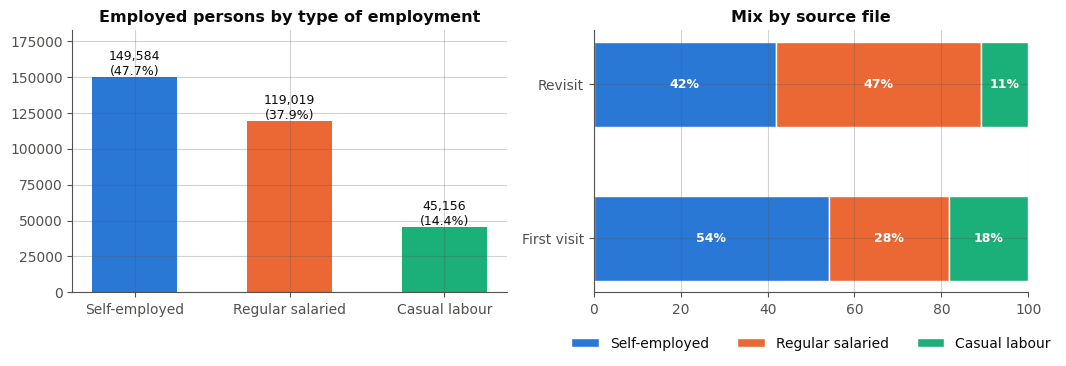

In [12]:
data["weight"] = np.where(data.nss == data.nsc, data.mult / 100, data.mult / 200)
cnt = data["target"].value_counts().reindex(CLASSES)
wt = data.groupby("target", observed=True)["weight"].sum().reindex(CLASSES)

dist = pd.DataFrame({
    "Persons": cnt,
    "Share % (sample)": cnt / cnt.sum() * 100,
    "Share % (weighted)": wt / wt.sum() * 100
})
display(dist.style.format({"Persons": "{:,}", "Share % (sample)": "{:.1f}", "Share % (weighted)": "{:.1f}"}))
print("Imbalance ratio (largest / smallest class):", round(cnt.max() / cnt.min(), 2))

src = pd.crosstab(data.source, data.target, normalize="index")[CLASSES] * 100
display(src.round(1).rename_axis(None).rename_axis(None, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(CLASSES, cnt.values, color=[CLS_COL[c] for c in CLASSES], width=0.55)
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f"{v:,}\n({v / cnt.sum() * 100:.1f}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, cnt.max() * 1.22)
axes[0].set_title("Employed persons by type of employment")

left = np.zeros(2)
for c in CLASSES:
    v = src[c].values
    axes[1].barh(src.index, v, left=left, color=CLS_COL[c], label=c, height=0.55, edgecolor="white")
    for y_pos, (l, w) in enumerate(zip(left, v)):
        axes[1].text(l + w / 2, y_pos, f"{w:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += v
axes[1].set_title("Mix by source file")
axes[1].set_xlim(0, 100)
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

### Step 13: Decide which columns may be used as features (leakage control)
Document which variable groups are legitimate predictors and which must be excluded due to target leakage (`earn_sal`, `earn_self`, daily status codes, usual status, and `hh_type`) or structural sparsity (`b7*`, `b4pt1*`, `attend`).

In [13]:
plan = pd.DataFrame([
    ["Identifiers / design", "fsu, sg, stage2, hh_no, person_no, qtr, visit, stratum, mult, nss, nsc", "Not features",
     "Identify the record or sample design; no behavioural meaning. hh_id is used to keep households together in splitting."],
    ["Target source", "cws (Current Weekly Status)", "Target",
     "Grouped into Self-employed / Regular salaried / Casual labour."],
    ["Earnings", "earn_sal, earn_self (b6q9, b6q10)", "EXCLUDED - leakage",
     "Salary exists only for regular salaried, self-employment earnings only for self-employed (Step 10)."],
    ["Daily status and wages", "b6q4_, b6q9_ day blocks, b6q5_ day industry", "EXCLUDED - leakage",
     "Daily activity status codes are the same codes as the target, recorded day by day."],
    ["Usual-activity block", "b5pt1q3...b5pt3q12", "EXCLUDED - leakage / first-visit only",
     "Usual principal status duplicates the target and is absent in revisit records."],
    ["Household type", "hh_type (b3q2)", "EXCLUDED - leakage risk",
     "Defined from the household's main income source, which includes this person's own work; kept for exploration only."],
    ["Demographics", "age, sex, marital, relation, gen_edu, tech_edu, edu_years, voc_training", "FEATURE",
     "Known characteristics of the person."],
    ["Household context", "hh_size, religion, social_group, hh_exp -> expenditure per person", "FEATURE",
     "Household background."],
    ["Geography", "sector, state", "FEATURE",
     "Rural/urban and state labour markets differ."],
    ["Work context", "industry (NIC), occupation (NCO), hours worked in the week", "FEATURE",
     "Describe the job; they do not reveal the contract type directly."],
    ["Migration block, training details", "b7*, b4pt1*", "Not used",
     "Mostly empty (>75% missing) and first-visit only."],
    ["Attendance status", "attend (b4q11)", "Not used",
     "Asked only up to about age 29; missing for most workers by design."]
], columns=["Group", "Variables", "Decision", "Reason"])

display(plan.style.hide(axis="index").set_properties(subset=["Reason", "Variables"], **{"white-space": "normal"}))

Group,Variables,Decision,Reason
Identifiers / design,"fsu, sg, stage2, hh_no, person_no, qtr, visit, stratum, mult, nss, nsc",Not features,Identify the record or sample design; no behavioural meaning. hh_id is used to keep households together in splitting.
Target source,cws (Current Weekly Status),Target,Grouped into Self-employed / Regular salaried / Casual labour.
Earnings,"earn_sal, earn_self (b6q9, b6q10)",EXCLUDED - leakage,"Salary exists only for regular salaried, self-employment earnings only for self-employed (Step 10)."
Daily status and wages,"b6q4_, b6q9_ day blocks, b6q5_ day industry",EXCLUDED - leakage,"Daily activity status codes are the same codes as the target, recorded day by day."
Usual-activity block,b5pt1q3...b5pt3q12,EXCLUDED - leakage / first-visit only,Usual principal status duplicates the target and is absent in revisit records.
Household type,hh_type (b3q2),EXCLUDED - leakage risk,"Defined from the household's main income source, which includes this person's own work; kept for exploration only."
Demographics,"age, sex, marital, relation, gen_edu, tech_edu, edu_years, voc_training",FEATURE,Known characteristics of the person.
Household context,"hh_size, religion, social_group, hh_exp -> expenditure per person",FEATURE,Household background.
Geography,"sector, state",FEATURE,Rural/urban and state labour markets differ.
Work context,"industry (NIC), occupation (NCO), hours worked in the week",FEATURE,Describe the job; they do not reveal the contract type directly.


### Step 14A: Feature engineering: readable categories and derived variables
Translate survey codes into interpretable labels, aggregate 2-digit NIC industry codes into 10 broad sectors and 1-digit NCO occupation codes into 9 occupational groups, and derive `weekly_hours`, `days_worked`, `extra_hours_avail`, `exp_per_person`, and `log_exp_pp`.

In [14]:
STATE = {
    "01": "Jammu & Kashmir", "02": "Himachal Pradesh", "03": "Punjab", "04": "Chandigarh", "05": "Uttarakhand",
    "06": "Haryana", "07": "Delhi", "08": "Rajasthan", "09": "Uttar Pradesh", "10": "Bihar", "11": "Sikkim",
    "12": "Arunachal Pradesh", "13": "Nagaland", "14": "Manipur", "15": "Mizoram", "16": "Tripura",
    "17": "Meghalaya", "18": "Assam", "19": "West Bengal", "20": "Jharkhand", "21": "Odisha",
    "22": "Chhattisgarh", "23": "Madhya Pradesh", "24": "Gujarat", "25": "Daman & Diu", "26": "D&N Haveli",
    "27": "Maharashtra", "28": "Andhra Pradesh", "29": "Karnataka", "30": "Goa", "31": "Lakshadweep",
    "32": "Kerala", "33": "Tamil Nadu", "34": "Puducherry", "35": "A&N Islands", "36": "Telangana", "37": "Ladakh"
}

EDU = {
    "01": "Not literate", "02": "Below primary", "03": "Below primary", "04": "Below primary", "05": "Below primary",
    "06": "Primary", "07": "Middle", "08": "Secondary", "10": "Higher secondary",
    "11": "Diploma/certificate", "12": "Graduate", "13": "Postgraduate+"
}
EDU_ORDER = [
    "Not literate", "Below primary", "Primary", "Middle", "Secondary",
    "Higher secondary", "Diploma/certificate", "Graduate", "Postgraduate+"
]
MARITAL = {"1": "Never married", "2": "Married", "3": "Widowed", "4": "Divorced/separated"}
RELATION = {
    "1": "Head", "2": "Spouse", "3": "Married child", "4": "Child-in-law", "5": "Unmarried child",
    "6": "Grandchild", "7": "Parent/in-law", "8": "Other relative", "9": "Non-relative"
}
RELIGION = {"1": "Hindu", "2": "Muslim", "3": "Christian", "4": "Sikh", "5": "Other", "6": "Other", "7": "Other", "9": "Other"}
SOCIAL = {"1": "ST", "2": "SC", "3": "OBC", "9": "General/Other"}

def industry_group(nic):
    if pd.isna(nic):
        return np.nan
    n = int(nic)
    if n <= 3: return "Agriculture & allied"
    if n <= 9 or 35 <= n <= 39: return "Mining & utilities"
    if n <= 33: return "Manufacturing"
    if n <= 43: return "Construction"
    if n <= 47: return "Trade"
    if n <= 53: return "Transport & storage"
    if n <= 56: return "Accommodation & food"
    if n <= 82: return "Business, IT & finance services"
    if n <= 88: return "Public admin, education, health"
    return "Other services"

OCC = {
    "0": "Armed forces", "1": "Managers & officials", "2": "Professionals", "3": "Technicians & associates",
    "4": "Clerks", "5": "Service & sales workers", "6": "Skilled agri & fishery", "7": "Craft & trades",
    "8": "Plant & machine operators", "9": "Elementary occupations"
}

d = data
d["sector_l"] = d.sector.map({"1": "Rural", "2": "Urban"})
d["sex_l"] = d.sex.map({"1": "Male", "2": "Female", "3": "Transgender"})
d["state_l"] = d.state.map(STATE)
d["edu_grp"] = pd.Categorical(d.gen_edu.map(EDU), categories=EDU_ORDER, ordered=True)
d["marital_l"] = d.marital.map(MARITAL)
d["relation_l"] = d.relation.map(RELATION)
d["religion_l"] = d.religion.map(RELIGION)
d["social_l"] = d.social_group.map(SOCIAL)
d["technical_edu"] = np.where(d.tech_edu.eq("01"), "No technical education", "Has technical education")
d["voc_l"] = d.voc_training.map(lambda v: "Not asked (revisit)" if pd.isna(v) else ("No" if v == "6" else "Yes"))
d["age_grp"] = pd.cut(d.age, [14, 24, 34, 44, 59, 120], labels=["15-24", "25-34", "35-44", "45-59", "60+"])
d["industry_grp"] = d.ind_nic.map(industry_group)
d["occupation_grp"] = d.occ_nco.str[0].map(OCC)
d["weekly_hours"] = d[[f"hrs_d{i}" for i in range(1, 8)]].sum(axis=1)
d["days_worked"] = (d[[f"hrs_d{i}" for i in range(1, 8)]] > 0).sum(axis=1)
d["extra_hours_avail"] = d[[f"extra_d{i}" for i in range(1, 8)]].sum(axis=1)
d["exp_per_person"] = d.hh_exp / d.hh_size
d["log_exp_pp"] = np.log1p(d["exp_per_person"])

# Also compute normalized ordinal rank for edu_grp: z_if = (r_if - 1) / (M_f - 1)
EDU_RANK_MAP = {lvl: idx / (len(EDU_ORDER) - 1) for idx, lvl in enumerate(EDU_ORDER)}
d["edu_rank_norm"] = d["edu_grp"].astype(str).map(EDU_RANK_MAP)

new_cols = [
    "sector_l", "sex_l", "state_l", "edu_grp", "edu_rank_norm", "marital_l", "relation_l",
    "religion_l", "social_l", "technical_edu", "voc_l", "age_grp", "industry_grp",
    "occupation_grp", "weekly_hours", "days_worked", "extra_hours_avail", "exp_per_person", "log_exp_pp"
]
print("Derived columns:", len(new_cols))
display(d[["target"] + new_cols[:12]].head(6))
print("\nUnmapped/missing codes in candidate features ->", {
    c: int(d[c].isna().sum()) for c in [
        "sector_l", "sex_l", "state_l", "edu_grp", "marital_l",
        "religion_l", "social_l", "industry_grp", "occupation_grp"
    ]
})

Derived columns: 19


,target,sector_l,sex_l,state_l,edu_grp,edu_rank_norm,marital_l,relation_l,religion_l,social_l,technical_edu,voc_l,age_grp
0,Self-employed,Rural,Male,Manipur,Middle,0.38,Married,Head,Hindu,General/Other,No technical education,No,45-59
2,Regular salaried,Rural,Female,Manipur,Higher secondary,0.62,Never married,Unmarried child,Hindu,General/Other,No technical education,No,25-34
3,Self-employed,Rural,Female,Manipur,Graduate,0.88,Never married,Unmarried child,Hindu,General/Other,No technical education,No,15-24
5,Regular salaried,Rural,Male,Manipur,Middle,0.38,Married,Head,Hindu,OBC,No technical education,No,35-44
6,Self-employed,Rural,Female,Manipur,Not literate,0.00,Married,Spouse,Hindu,OBC,No technical education,No,35-44
9,Self-employed,Rural,Male,Manipur,Not literate,0.00,Married,Head,Other,OBC,No technical education,Not asked (revisit),60+



Unmapped/missing codes in candidate features -> {'sector_l': 0, 'sex_l': 0, 'state_l': 0, 'edu_grp': 96, 'marital_l': 26, 'religion_l': 0, 'social_l': 0, 'industry_grp': 0, 'occupation_grp': 951}


### Step 14B: Formal Attribute Taxonomy
Classify every variable in our modelling table into the formal **Attribute Types**:
* **Nominal:** Unordered categorical states (`state_l`, `marital_l`, `relation_l`, `religion_l`, `social_l`, `industry_grp`, `occupation_grp`, `sex_l`). Arithmetic is invalid; only Mode, frequency, contingency tables, and One-Hot / Simple Matching apply.
* **Symmetric Binary:** Two equally weighted states (`sector_l`: Rural vs. Urban).
* **Asymmetric Binary:** Two states where `1` is a rare, significant positive match (`technical_edu`: *Has technical education* = 6.4% vs. *No technical education* = 93.6%). Requires Jaccard similarity/dissimilarity so `0–0` negative matches do not inflate similarity.
* **Ordinal:** Ordered categories (`edu_grp` across 9 schooling levels; `age_grp` across 5 brackets). Preserves rank order via **Normalized Rank Encoding** $z_{if} = \frac{r_{if}-1}{M_f-1} \in [0, 1]$; Median and Mode are valid.
* **Interval-scaled:** Survey quarter/date (`qtr`, `b2q2i`)—equal unit differences without a true zero point.
* **Ratio-scaled:** All 7 numeric features (`age`, `edu_years`, `hh_size`, `exp_per_person`, `weekly_hours`, `days_worked`, `extra_hours_avail`) have a true absolute zero point, permitting Mean, Median, Mode, Variance, Skewness, Kurtosis, and Standardization.

In [15]:
taxonomy_rows = [
    ["target", "b6q5 (CWS)", "Nominal", "3 target classes", "Self-employed, Regular salaried, Casual labour", "Mode, class frequencies, contingency tables"],
    ["sector_l", "b1q3", "Binary", "Symmetric Binary", "Rural (28.6%), Urban (71.4%)", "0/1 indicator; Simple Matching distance"],
    ["technical_edu", "b4q9", "Binary", "Asymmetric Binary", "Has tech edu (1: 6.4%) vs No tech edu (0: 93.6%)", "1 = rare positive match; Jaccard coefficient"],
    ["voc_l", "b4q12", "Nominal (Asym. Binary in V1)", "3 states", "Yes (10.9%), No (32.7%), Not asked/revisit (56.4%)", "One-Hot Encoding; Gower delta=0 when Not asked"],
    ["sex_l", "b4q5", "Nominal", "3 states", "Male (76.2%), Female (23.8%), Transgender (0.02%)", "One-Hot Encoding; Mode"],
    ["state_l", "state", "Nominal", "36 states/UTs", "Codes '01'..'37' mapped to state names", "One-Hot Encoding; arithmetic on raw codes invalid"],
    ["marital_l", "b4q7", "Nominal", "4 states", "Never married, Married, Widowed, Divorced/sep.", "One-Hot Encoding; Mode"],
    ["relation_l", "b4q4", "Nominal", "9 states", "Head, Spouse, Unmarried child, Married child, etc.", "One-Hot Encoding; Mode"],
    ["religion_l", "b3q3", "Nominal", "5 grouped states", "Hindu, Muslim, Christian, Sikh, Other", "One-Hot Encoding; Mode"],
    ["social_l", "b3q4", "Nominal", "4 states", "ST, SC, OBC, General/Other", "One-Hot Encoding; Mode"],
    ["industry_grp", "b6q6 (NIC)", "Nominal", "10 broad groups", "Agriculture, Trade, Manufacturing, Construction, etc.", "One-Hot Encoding; Mode, Cramér's V"],
    ["occupation_grp", "b6q7 (NCO)", "Nominal", "9 broad groups", "Skilled agri, Elementary, Service/sales, Craft, etc.", "One-Hot Encoding; Mode, Cramér's V"],
    ["edu_grp", "b4q8", "Ordinal", "9 ordered levels", "Not literate (1) < Below primary (2) < ... < Postgrad+ (9)", "Normalized Rank Encoding z=(r-1)/(9-1) in [0,1]; Median"],
    ["age_grp", "b4q6 binned", "Ordinal", "5 ordered brackets", "15-24 < 25-34 < 35-44 < 45-59 < 60+", "Rank Encoding; Median, Quantiles"],
    ["qtr / b2q2i", "Block 1/2", "Interval", "Calendar quarter/date", "Q5 (Jul-Sep 2020) to Q8 (Apr-Jun 2021)", "No true zero; interval differences valid"],
    ["age", "b4q6", "Numeric (Ratio)", "Discrete Ratio", "15 to 97 years (true zero = birth)", "Mean, Median, SD, Skew, Kurtosis, Standardization"],
    ["edu_years", "b4q10", "Numeric (Ratio)", "Discrete Ratio", "0 to 29 years (true zero = no formal schooling)", "Mean, Median, SD, Skew, Kurtosis, Standardization"],
    ["hh_size", "b3q1", "Numeric (Ratio)", "Discrete Ratio", "1 to 24 persons", "Mean, Median, IQR, Standardization"],
    ["exp_per_person", "b3q5 / b3q1", "Numeric (Ratio)", "Continuous Ratio", "Rs. 100 to Rs. 1,671,290 / month (true zero = Rs. 0)", "Log-transform + Winsorizing + Standardization; Median"],
    ["weekly_hours", "Sum(b6q7_d1..7)", "Numeric (Ratio)", "Continuous Ratio", "0 to 140 hours/week (true zero = 0 hours)", "Mean, Median, IQR, Standardization"],
    ["days_worked", "Count(hrs_d > 0)", "Numeric (Ratio)", "Discrete Ratio", "0 to 7 days/week", "Mean, Median, IQR, Standardization"],
    ["extra_hours_avail", "Sum(b6q8_d1..7)", "Numeric (Ratio)", "Continuous Ratio", "0 to 70 hours/week", "Zero-inflated; Median, Quantiles"]
]

taxonomy_df = pd.DataFrame(
    taxonomy_rows,
    columns=["Attribute", "PLFS Source", "Attribute Type", "Subtype / Cardinality", "Domain / States", "Valid Operations & Encoding"]
)
display(taxonomy_df.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Attribute,PLFS Source,Attribute Type,Subtype / Cardinality,Domain / States,Valid Operations & Encoding
target,b6q5 (CWS),Nominal,3 target classes,"Self-employed, Regular salaried, Casual labour","Mode, class frequencies, contingency tables"
sector_l,b1q3,Binary,Symmetric Binary,"Rural (28.6%), Urban (71.4%)",0/1 indicator; Simple Matching distance
technical_edu,b4q9,Binary,Asymmetric Binary,Has tech edu (1: 6.4%) vs No tech edu (0: 93.6%),1 = rare positive match; Jaccard coefficient
voc_l,b4q12,Nominal (Asym. Binary in V1),3 states,"Yes (10.9%), No (32.7%), Not asked/revisit (56.4%)",One-Hot Encoding; Gower delta=0 when Not asked
sex_l,b4q5,Nominal,3 states,"Male (76.2%), Female (23.8%), Transgender (0.02%)",One-Hot Encoding; Mode
state_l,state,Nominal,36 states/UTs,Codes '01'..'37' mapped to state names,One-Hot Encoding; arithmetic on raw codes invalid
marital_l,b4q7,Nominal,4 states,"Never married, Married, Widowed, Divorced/sep.",One-Hot Encoding; Mode
relation_l,b4q4,Nominal,9 states,"Head, Spouse, Unmarried child, Married child, etc.",One-Hot Encoding; Mode
religion_l,b3q3,Nominal,5 grouped states,"Hindu, Muslim, Christian, Sikh, Other",One-Hot Encoding; Mode
social_l,b3q4,Nominal,4 states,"ST, SC, OBC, General/Other",One-Hot Encoding; Mode


### Step 15: Univariate analysis: numeric variables (Central Tendency, Dispersion, Shape & Measure Types)
Compute the complete statistical profile for all 7 Ratio-scaled numeric attributes:
* **Measure Classification:**
  * **Distributive Measures (`Count`, `Min`, `Max`):** Can be computed on partitioned data subsets and combined directly.
  * **Algebraic Measures (`Mean`, `Range`, `Variance`, `Std Dev`):** Computed via algebraic combinations of distributive measures (e.g., $\text{Mean} = \text{Sum}/\text{Count}$).
  * **Holistic Measures (`Median Q2`, `5% Trimmed Mean`, `Mode`, `Q1`, `Q3`, `IQR`):** Require sorting/inspecting the entire dataset globally.
* **Shape & Skewness Shift:**
  * **Right-skewed (`exp_per_person`, $\text{Skew} = +215.18$, $\text{Kurtosis} = +48,912$):** Follows $\text{Mode } (2,000) < \text{Median } (2,400) < \text{5\% Trimmed Mean } (2,684) < \text{Mean } (3,031)$. The Median and Trimmed Mean are essential here because extreme outliers pull the arithmetic mean upward.
  * **Left-skewed (`days_worked`, $\text{Skew} = -2.43$; `weekly_hours`, $\text{Skew} = -0.78$):** Follows $\text{Mean} < \text{Median} \le \text{Mode}$, pulled left by temporarily absent workers with 0 hours.
* **Modality:** `edu_years` is **multimodal** (peaks at 0, 8, 10, 12, 15 years); `weekly_hours` is **trimodal** (peaks at 0, 48, and 56 hours); `age` is **unimodal** (median/mode = 40) with 5-year age-heaping spikes.

,count (Dist.),mean (Alg.),trim_mean_5% (Hol.),median_Q2 (Hol.),mode (Hol.),std (Alg.),var (Alg.),min (Dist.),Q1_25% (Hol.),Q3_75% (Hol.),99% (Hol.),max (Dist.),range (Alg.),IQR (Hol.),skew,kurtosis,IQR_outliers_%
Attribute,,,,,,,,,,,,,,,,,
age,313759,39.85,39.54,40.00,40.00,12.35,152.62,15.00,30.00,49.00,70.00,97.00,82.00,19.00,0.32,-0.51,0.13
edu_years,313759,9.07,9.09,10.00,10.00,5.13,26.35,0.00,6.00,12.00,18.00,29.00,29.00,6.00,-0.29,-0.67,0.07
hh_size,313759,4.60,4.48,4.00,4.00,1.99,3.96,1.00,3.00,6.00,11.00,24.00,23.00,3.00,1.29,4.05,1.33
exp_per_person,313759,"3,030.77","2,725.10","2,400.00","2,000.00","6,540.37","42,776,384.03",100.00,"1,690.00","3,536.00","11,875.00","1,671,289.67","1,671,189.67","1,846.00",215.18,"54,229.61",6.36
weekly_hours,313759,46.29,47.09,48.00,56.00,15.92,253.48,0.00,39.00,56.00,84.00,140.00,140.00,17.00,-0.78,1.03,5.40
days_worked,313759,6.06,6.30,7.00,7.00,1.52,2.33,0.00,6.00,7.00,7.00,7.00,7.00,1.00,-2.43,6.30,10.74
extra_hours_avail,313759,0.21,0.00,0.00,0.00,2.00,4.02,0.00,0.00,0.00,7.00,70.00,70.00,0.00,12.74,193.72,1.83


Ordinal `edu_grp` -> Median level: Middle | Mode level: Middle
Ordinal `age_grp` -> Median bracket: 35-44 | Mode bracket: 45-59


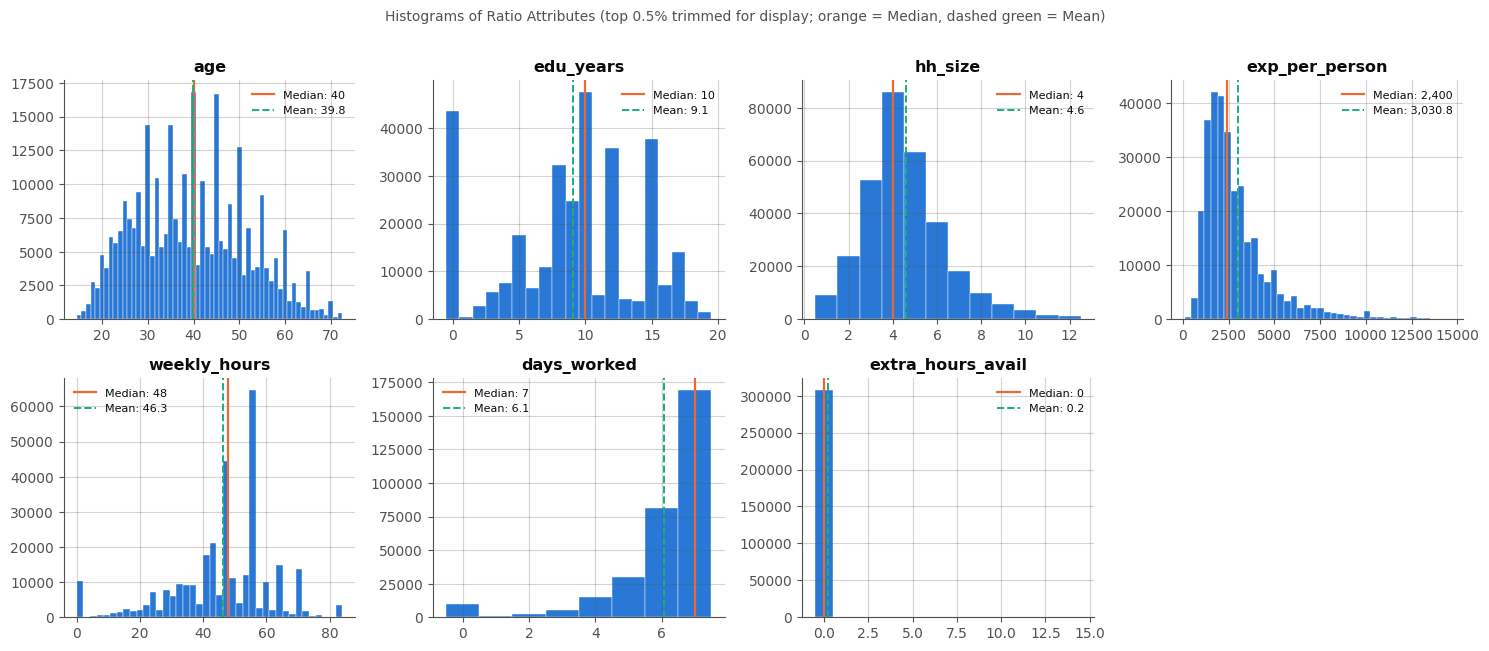

In [16]:
numv = ["age", "edu_years", "hh_size", "exp_per_person", "weekly_hours", "days_worked", "extra_hours_avail"]

stats_rows = []
for c in numv:
    x = d[c].dropna().astype(float)
    q01, q25, q50, q75, q99 = x.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    iqr = q75 - q25
    iqr_out = int(((x < q25 - 1.5 * iqr) | (x > q75 + 1.5 * iqr)).sum())
    stats_rows.append({
        "Attribute": c,
        "count (Dist.)": len(x),
        "mean (Alg.)": x.mean(),
        "trim_mean_5% (Hol.)": stats.trim_mean(x, 0.05),
        "median_Q2 (Hol.)": q50,
        "mode (Hol.)": x.mode().iloc[0],
        "std (Alg.)": x.std(),
        "var (Alg.)": x.var(),
        "min (Dist.)": x.min(),
        "Q1_25% (Hol.)": q25,
        "Q3_75% (Hol.)": q75,
        "99% (Hol.)": q99,
        "max (Dist.)": x.max(),
        "range (Alg.)": x.max() - x.min(),
        "IQR (Hol.)": iqr,
        "skew": x.skew(),
        "kurtosis": x.kurt(),
        "IQR_outliers_%": iqr_out / len(x) * 100
    })

desc = pd.DataFrame(stats_rows).set_index("Attribute")
display(desc)

# Also check Ordinal attributes' Median and Mode
print(
    "Ordinal `edu_grp` -> Median level:", EDU_ORDER[int(np.nanmedian(d["edu_grp"].cat.codes))],
    "| Mode level:", d["edu_grp"].mode().iloc[0]
)
print(
    "Ordinal `age_grp` -> Median bracket:", d["age_grp"].cat.categories[int(np.nanmedian(d["age_grp"].cat.codes))],
    "| Mode bracket:", d["age_grp"].mode().iloc[0]
)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
axes = axes.ravel()
for ax, c in zip(axes, numv):
    x = d[c].dropna()
    x_plot = x[x <= x.quantile(0.995)]
    bins = np.arange(x_plot.min() - 0.5, x_plot.max() + 1.5) if x_plot.nunique() <= 70 else 40
    ax.hist(x_plot, bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.3)
    ax.axvline(x.median(), color="#eb6834", lw=1.6, label=f"Median: {x.median():,.0f}")
    ax.axvline(x.mean(), color="#1baf7a", lw=1.4, ls="--", label=f"Mean: {x.mean():,.1f}")
    ax.set_title(f"{c}")
    ax.legend(fontsize=8)
axes[-1].axis("off")
plt.suptitle("Histograms of Ratio Attributes (top 0.5% trimmed for display; orange = Median, dashed green = Mean)", y=1.01, color=MUTED, fontsize=10)
plt.tight_layout()
plt.show()

### Step 16: Univariate analysis: categorical variables (Bar Charts & Modes)
**Histograms** display numeric frequency distributions whereas **Bar Charts** display categorical proportions. Below are the bar charts and modal states for all 12 categorical (Nominal, Binary, and Ordinal) features.

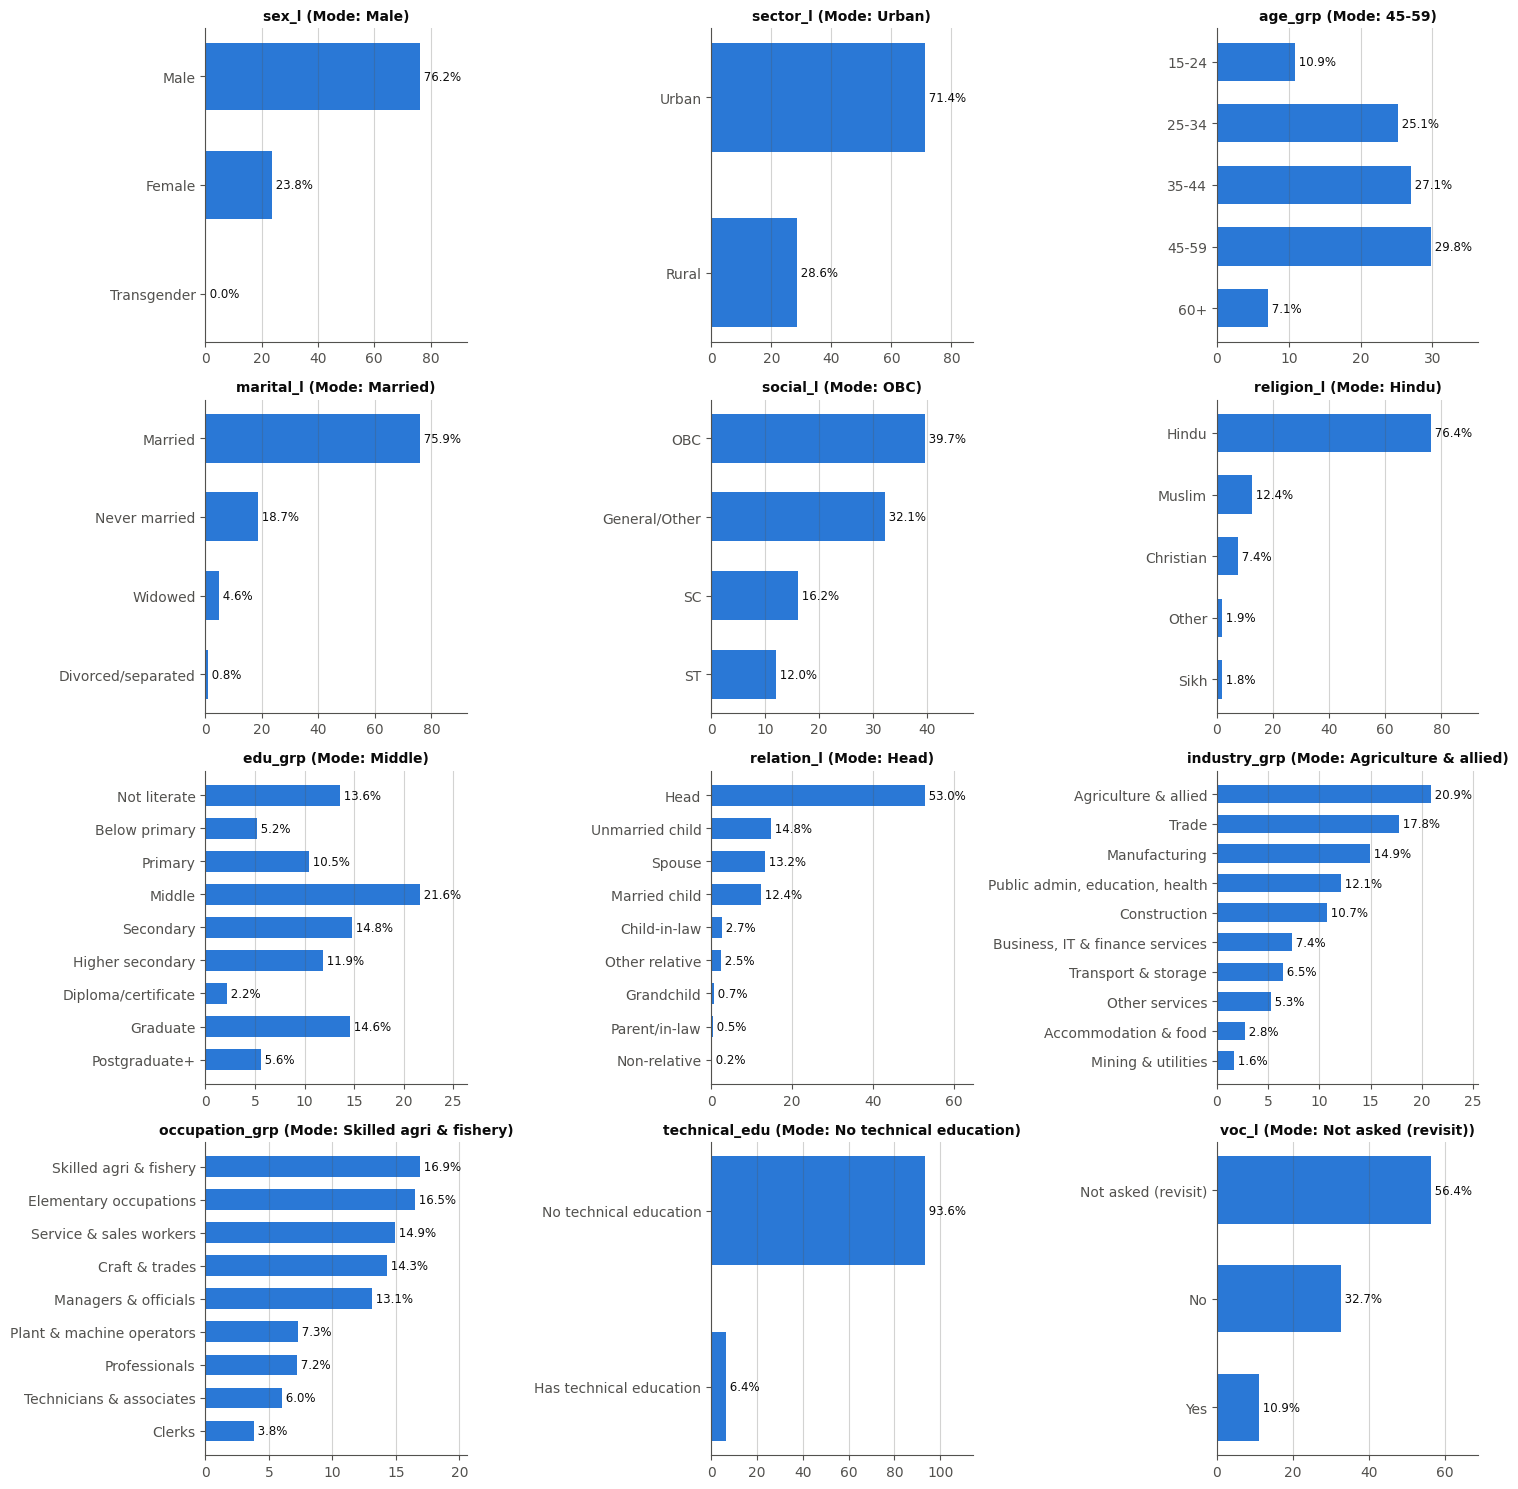

States covered: 36 | districts: 71


In [17]:
catv = [
    "sex_l", "sector_l", "age_grp", "marital_l", "social_l", "religion_l",
    "edu_grp", "relation_l", "industry_grp", "occupation_grp", "technical_edu", "voc_l"
]

fig, axes = plt.subplots(4, 3, figsize=(15, 15))
axes = axes.ravel()
for ax, c in zip(axes, catv):
    vc = d[c].value_counts(normalize=True).mul(100)
    vc = (
        vc.reindex(EDU_ORDER[::-1]) if c == "edu_grp"
        else (vc.sort_index(ascending=False) if c == "age_grp" else vc.sort_values())
    )
    ax.barh(vc.index.astype(str), vc.values, color="#2a78d6", height=0.62)
    for y_pos, v in enumerate(vc.values):
        ax.text(v, y_pos, f" {v:.1f}%", va="center", fontsize=8.5)
    ax.set_title(f"{c} (Mode: {d[c].mode().iloc[0]})", fontsize=10)
    ax.set_xlim(0, vc.max() * 1.22)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print("States covered:", d.state_l.nunique(), "| districts:", d.dist.nunique())

### Step 17: Bivariate analysis: employment type by personal and household characteristics
For each personal and household characteristic, plot the 100% stacked bar chart showing the conditional distribution of employment types.

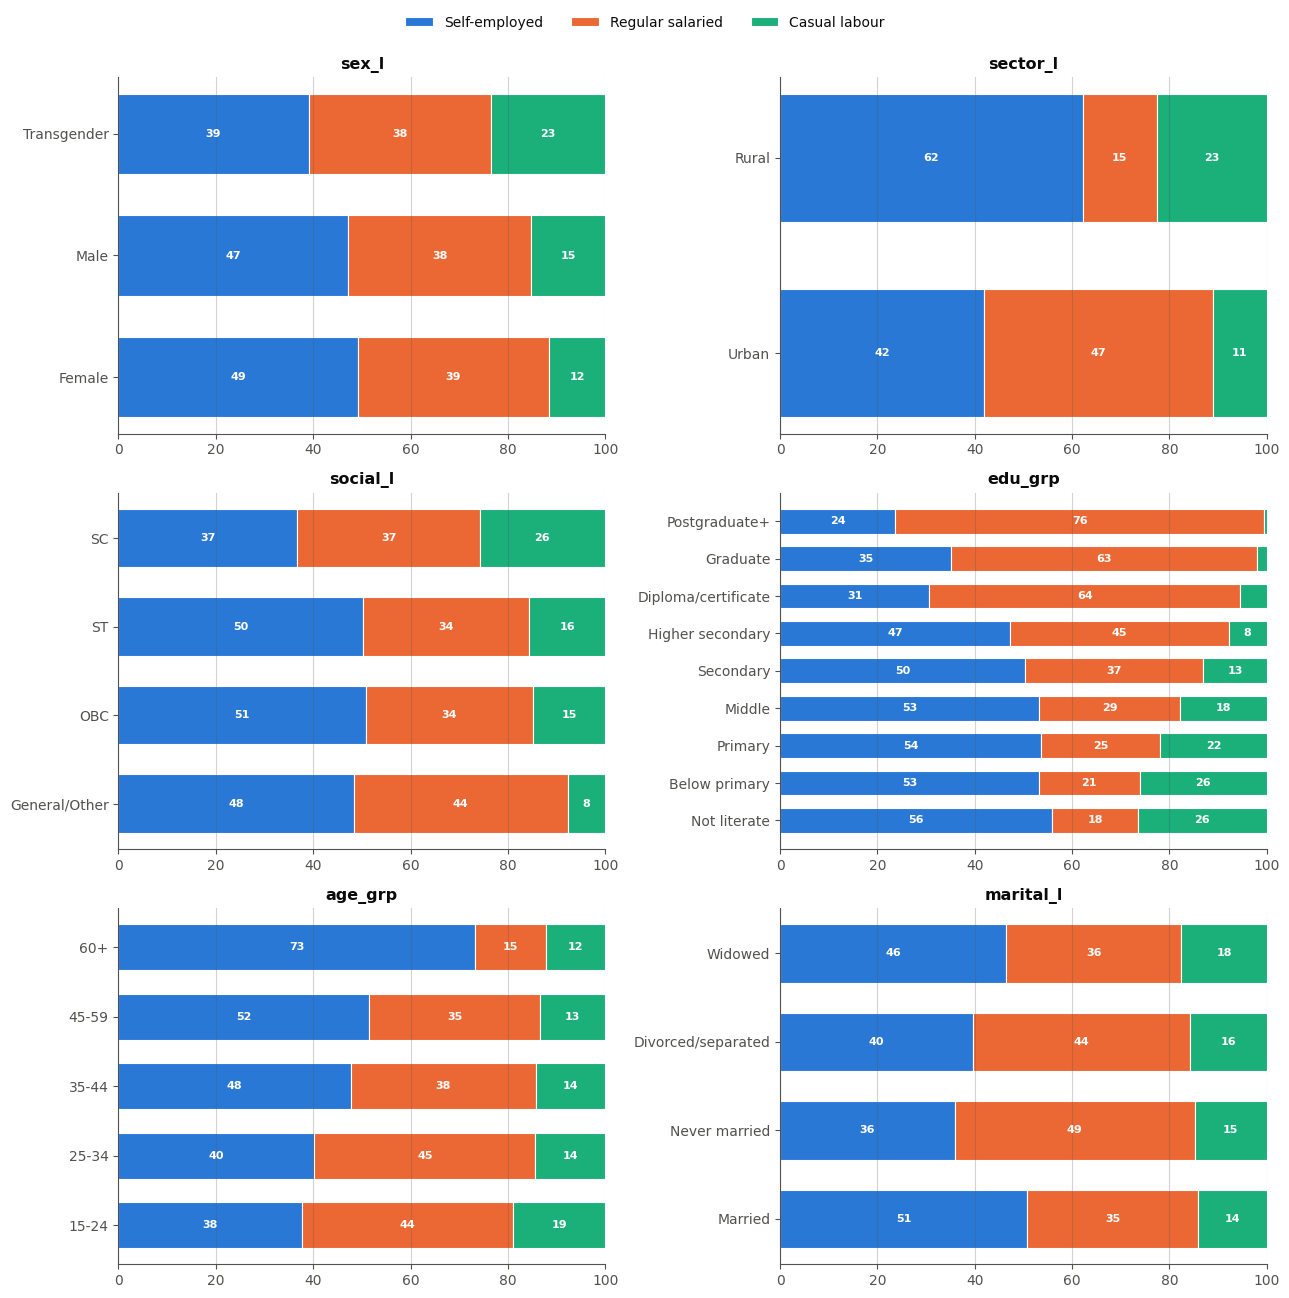


Row % — sex_l


target,Self-employed,Regular salaried,Casual labour
sex_l,,,
Female,49.30,39.10,11.60
Male,47.20,37.60,15.30
Transgender,39.10,37.50,23.40



Row % — sector_l


target,Self-employed,Regular salaried,Casual labour
sector_l,,,
Rural,62.20,15.10,22.60
Urban,41.80,47.10,11.10


In [18]:
def stacked(ax, col, title=None, order=None):
    ct = pd.crosstab(d[col], d.target, normalize="index")[CLASSES] * 100
    if order is not None:
        ct = ct.reindex(order)
    else:
        ct = ct.sort_values("Casual labour")
    left = np.zeros(len(ct))
    for c in CLASSES:
        v = ct[c].values
        ax.barh(ct.index.astype(str), v, left=left, color=CLS_COL[c], height=0.66, edgecolor="white", linewidth=0.8, label=c)
        for y_pos, (l, w) in enumerate(zip(left, v)):
            if w >= 7:
                ax.text(l + w / 2, y_pos, f"{w:.0f}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        left += v
    ax.set_xlim(0, 100)
    ax.set_title(title or col)
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
pairs = [
    ("sex_l", None), ("sector_l", None), ("social_l", None),
    ("edu_grp", EDU_ORDER), ("age_grp", ["15-24", "25-34", "35-44", "45-59", "60+"]), ("marital_l", None)
]
for ax, (c, o) in zip(axes.ravel(), pairs):
    stacked(ax, c, order=o)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0), fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

for c in ["sex_l", "sector_l"]:
    print(f"\nRow % — {c}")
    display((pd.crosstab(d[c], d.target, normalize="index")[CLASSES] * 100).round(1))

### Step 18A: Bivariate numeric analysis, 4-Step Boxplot Analysis vs. Violin Plots
Compare `age`, `edu_years`, `weekly_hours`, and `log_exp_pp` across the three employment types using both **Boxplots** (Five-number summary + $1.5\times\text{IQR}$ outliers) and **Violin Plots** (which combine a boxplot with a Kernel Density Estimate to expose multimodal peaks):
1. **Step 1 (Compare Medians):** In `edu_years`, the median of **Regular salaried (12.0 yrs)** lies completely outside the box of **Casual labour ($Q_1=0, Q_3=10$, median $=7.0$)**, and in `log_exp_pp` the median of Regular salaried ($8.00$) lies above the entire box of Casual labour ($Q_3=7.82$), proving a substantial difference between groups.
2. **Step 2 (Compare IQRs & Whiskers — Dispersion):** Casual labour has the tallest box in `edu_years` ($\text{IQR}=10$ yrs), reflecting wide educational spread from 0 to 10 years, whereas Regular salaried has the most compact box in `weekly_hours` ($\text{IQR}=14$ hrs, from 42 to 56).
3. **Step 3 (Potential Outliers):** Plotting fliers reveals low-hour outliers (`0` hrs) among temporarily absent workers and high-spending outliers above the upper whisker in `log_exp_pp`.
4. **Step 4 (Signs of Skewness & Multimodality via Violin Plots):** While the boxplot of `weekly_hours` makes Self-employed and Regular salaried look nearly identical at the median (48 hrs), the **Violin Plot** reveals sharp bimodal peaks at **48 and 56 hours** for Regular salaried and **three distinct schooling peaks (10, 12, and 15 years)** in `edu_years`.

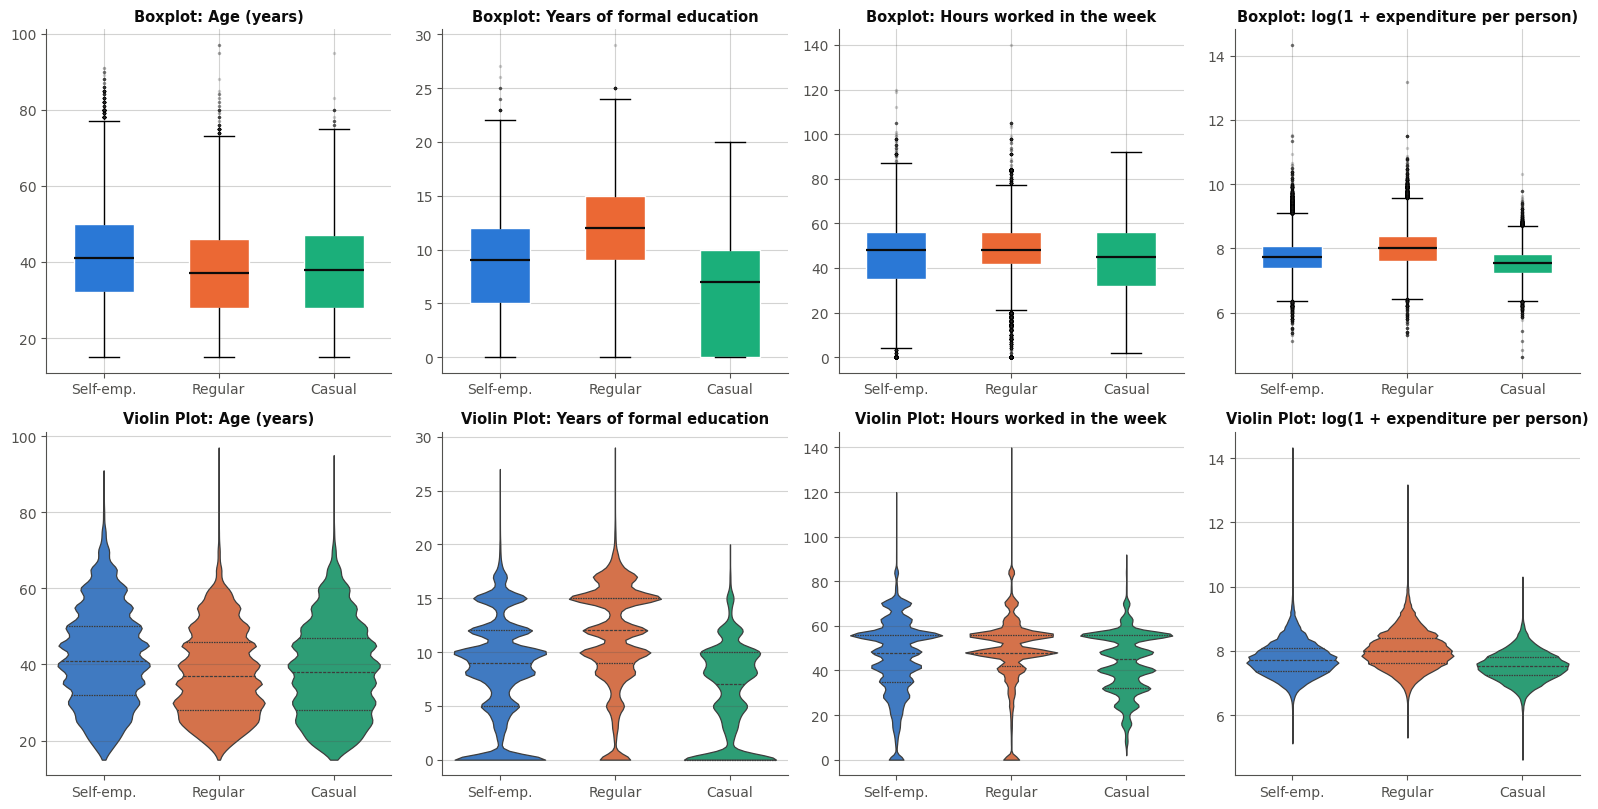

age              edu_years              weekly_hours              days_worked             exp_per_person                   hh_size            
                  mean median   IQR      mean median   IQR         mean median   IQR        mean median  IQR           mean   median      IQR    mean median  IQR
target                                                                                                                                                           
Self-employed    42.00  41.00 18.00      8.20   9.00  7.00        45.60  48.00 21.00        6.30   7.00 1.00       2,773.80 2,250.00 1,591.80    4.80   4.00 2.00
Regular salaried 37.70  37.00 18.00     11.30  12.00  6.00        48.30  48.00 14.00        6.00   6.00 1.00       3,710.70 2,975.00 2,420.80    4.30   4.00 2.00
Casual labour    38.50  38.00 19.00      6.10   7.00 10.00        43.30  45.00 24.00        5.50   6.00 3.00       2,090.00 1,863.40 1,111.60    4.60   4.00 2.00

In [19]:
plot_vars = [
    ("age", "Age (years)"),
    ("edu_years", "Years of formal education"),
    ("weekly_hours", "Hours worked in the week"),
    ("log_exp_pp", "log(1 + expenditure per person)")
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8.2))
for j, (c, title) in enumerate(plot_vars):
    data_c = [d.loc[d.target == k, c].dropna() for k in CLASSES]

    # Row 0: Boxplot with Outliers
    bp = axes[0, j].boxplot(
        data_c, tick_labels=["Self-emp.", "Regular", "Casual"],
        patch_artist=True, showfliers=True, widths=0.52,
        medianprops=dict(color=INK, lw=1.6),
        flierprops=dict(marker="o", markersize=1.5, alpha=0.15, markerfacecolor=MUTED)
    )
    for patch, k in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(CLS_COL[k])
        patch.set_edgecolor("white")
    axes[0, j].set_title(f"Boxplot: {title}", fontsize=10.5)

    # Row 1: Violin Plot showing Multimodal KDE Density
    sns.violinplot(
        data=d, x="target", y=c, order=CLASSES, palette=CLS_COL,
        inner="quartile", cut=0, linewidth=0.9, ax=axes[1, j]
    )
    axes[1, j].set_xticks([0, 1, 2])
    axes[1, j].set_xticklabels(["Self-emp.", "Regular", "Casual"])
    axes[1, j].set_xlabel("")
    axes[1, j].set_ylabel("")
    axes[1, j].set_title(f"Violin Plot: {title}", fontsize=10.5)

plt.tight_layout()
plt.show()

agg = d.groupby("target", observed=True)[["age", "edu_years", "weekly_hours", "days_worked", "exp_per_person", "hh_size"]].agg(
    ["mean", "median", lambda x: x.quantile(0.75) - x.quantile(0.25)]
).rename(columns={"<lambda_0>": "IQR"}).round(1)
display(agg)

### Step 18B: Quantile Plots, Normal Q-Q Plots, and Two-Sample Q-Q Plots
Implement the three quantile-based visual diagnostics:
1. **Quantile Plot:** Plots ordered sample values $y_{(i)}$ against cumulative plotting positions $p_i = \frac{i - 0.5}{n}$.
2. **Normal Q-Q Plot:** Plots sample quantiles against theoretical Standard Normal quantiles $z_i = \Phi^{-1}(p_i)$. Raw `exp_per_person` bends sharply upward, whereas `log_exp_pp` aligns closely with the $45^\circ$ straight normal reference line.
3. **Two-Sample Q-Q Plot:** Compares interpolated quantiles across unequal-sized employment classes. **Self-employed vs. Casual labour** aligns parallel to the $45^\circ$ line above it (pure **location shift**), while **Regular salaried vs. Casual labour** sits higher and diverges upward at the top quantiles (both a **location shift and wider upper-tail scale**).

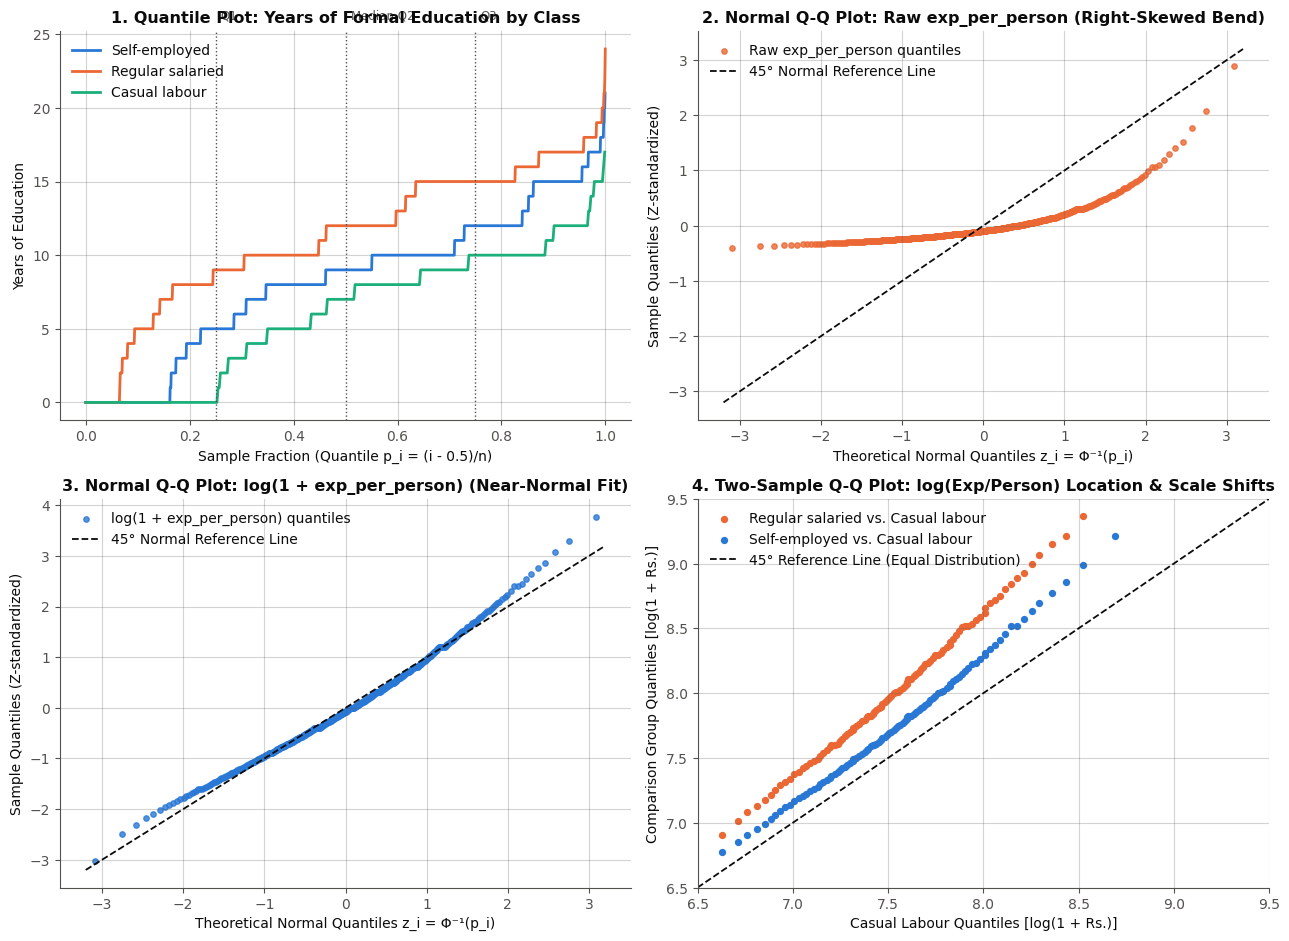

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

# 1. Quantile Plot of Years of Formal Education by Class
for cls in CLASSES:
    sub = np.sort(d.loc[d.target == cls, "edu_years"].dropna().to_numpy())
    p_i = (np.arange(1, len(sub) + 1) - 0.5) / len(sub)
    # Plot every 100th point for crisp rendering
    axes[0, 0].plot(p_i[::100], sub[::100], label=cls, color=CLS_COL[cls], lw=2.0)
for q_mark, q_lbl in [(0.25, "Q1"), (0.50, "Median Q2"), (0.75, "Q3")]:
    axes[0, 0].axvline(q_mark, color=MUTED, ls=":", lw=1.0)
    axes[0, 0].text(q_mark + 0.01, 26, q_lbl, fontsize=8.5, color=MUTED)
axes[0, 0].set_title("1. Quantile Plot: Years of Formal Education by Class")
axes[0, 0].set_xlabel("Sample Fraction (Quantile p_i = (i - 0.5)/n)")
axes[0, 0].set_ylabel("Years of Education")
axes[0, 0].legend(loc="upper left")

# 2. Normal Q-Q Plot: Raw Expenditure per Person vs. Standard Normal
q_grid = np.linspace(0.001, 0.999, 500)
z_theo = stats.norm.ppf(q_grid)
raw_q = np.quantile(d["exp_per_person"].dropna(), q_grid)
raw_z = (raw_q - d["exp_per_person"].mean()) / d["exp_per_person"].std()
axes[0, 1].scatter(z_theo, raw_z, s=15, color="#eb6834", alpha=0.8, label="Raw exp_per_person quantiles")
axes[0, 1].plot([-3.2, 3.2], [-3.2, 3.2], color=INK, ls="--", lw=1.3, label="45° Normal Reference Line")
axes[0, 1].set_title("2. Normal Q-Q Plot: Raw exp_per_person (Right-Skewed Bend)")
axes[0, 1].set_xlabel("Theoretical Normal Quantiles z_i = Φ⁻¹(p_i)")
axes[0, 1].set_ylabel("Sample Quantiles (Z-standardized)")
axes[0, 1].legend(loc="upper left")

# 3. Normal Q-Q Plot: Log-Transformed Expenditure per Person vs. Standard Normal
log_q = np.quantile(d["log_exp_pp"].dropna(), q_grid)
log_z = (log_q - d["log_exp_pp"].mean()) / d["log_exp_pp"].std()
axes[1, 0].scatter(z_theo, log_z, s=15, color="#2a78d6", alpha=0.8, label="log(1 + exp_per_person) quantiles")
axes[1, 0].plot([-3.2, 3.2], [-3.2, 3.2], color=INK, ls="--", lw=1.3, label="45° Normal Reference Line")
axes[1, 0].set_title("3. Normal Q-Q Plot: log(1 + exp_per_person) (Near-Normal Fit)")
axes[1, 0].set_xlabel("Theoretical Normal Quantiles z_i = Φ⁻¹(p_i)")
axes[1, 0].set_ylabel("Sample Quantiles (Z-standardized)")
axes[1, 0].legend(loc="upper left")

# 4. Two-Sample Q-Q Plot: Comparing Unequal-Sized Classes via Quantile Interpolation
p_interp = np.linspace(0.01, 0.99, 99)
q_casual = np.quantile(d.loc[d.target == "Casual labour", "log_exp_pp"].dropna(), p_interp)
q_regular = np.quantile(d.loc[d.target == "Regular salaried", "log_exp_pp"].dropna(), p_interp)
q_selfemp = np.quantile(d.loc[d.target == "Self-employed", "log_exp_pp"].dropna(), p_interp)

axes[1, 1].scatter(q_casual, q_regular, s=18, color=CLS_COL["Regular salaried"], label="Regular salaried vs. Casual labour")
axes[1, 1].scatter(q_casual, q_selfemp, s=18, color=CLS_COL["Self-employed"], label="Self-employed vs. Casual labour")
axes[1, 1].plot([6.5, 9.5], [6.5, 9.5], color=INK, ls="--", lw=1.3, label="45° Reference Line (Equal Distribution)")
axes[1, 1].set_xlim(6.5, 9.5)
axes[1, 1].set_ylim(6.5, 9.5)
axes[1, 1].set_title("4. Two-Sample Q-Q Plot: log(Exp/Person) Location & Scale Shifts")
axes[1, 1].set_xlabel("Casual Labour Quantiles [log(1 + Rs.)]")
axes[1, 1].set_ylabel("Comparison Group Quantiles [log(1 + Rs.)]")
axes[1, 1].legend(loc="upper left")

plt.tight_layout()
plt.show()

### Step 19: Industry and occupation versus employment type
Show which industries (`industry_grp`) and occupations (`occupation_grp`) are dominated by each employment type.

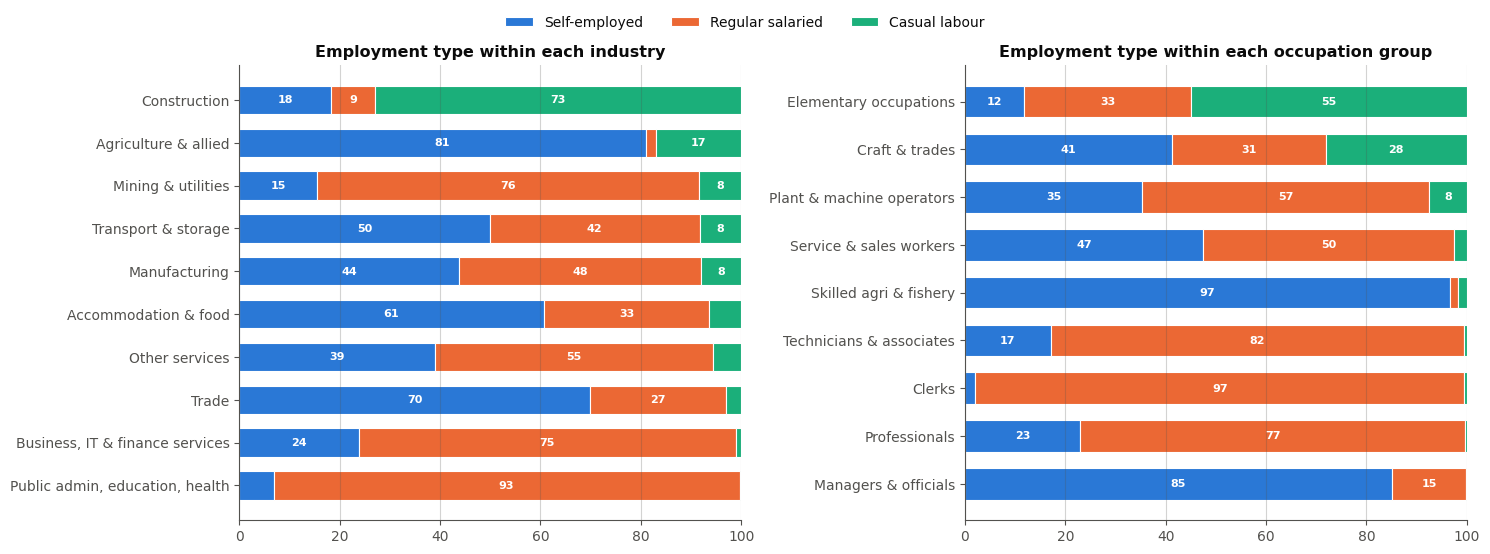

target,Self-employed,Regular salaried,Casual labour,persons
industry_grp,,,,
Agriculture & allied,81.00,2.00,17.00,65660
Trade,69.90,27.10,2.90,55790
Manufacturing,43.80,48.10,8.10,46747
"Public admin, education, health",6.80,92.90,0.30,37967
Construction,18.20,8.80,73.00,33687
"Business, IT & finance services",23.80,75.10,1.10,23136
Transport & storage,49.90,41.70,8.30,20239
Other services,39.10,55.20,5.70,16709
Accommodation & food,60.60,33.00,6.40,8721


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
stacked(axes[0], "industry_grp", "Employment type within each industry")
stacked(axes[1], "occupation_grp", "Employment type within each occupation group")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

display(
    (pd.crosstab(d.industry_grp, d.target, normalize="index")[CLASSES] * 100)
    .round(1)
    .assign(persons=d.industry_grp.value_counts())
    .sort_values("persons", ascending=False)
)

### Step 20: State-wise composition of employment types
Compare the employment mix across states and union territories (with at least 300 employed persons in the sample), ordered by the share of casual labour.

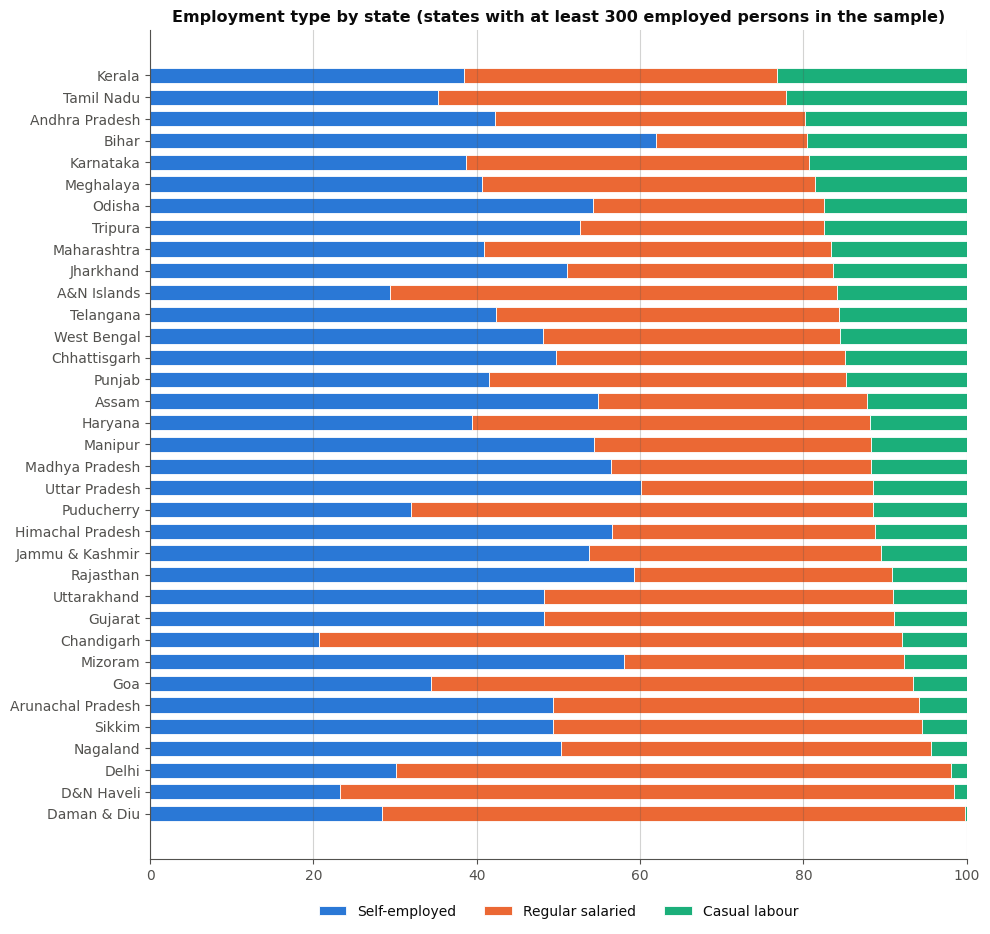

Top 5 states by Casual labour share:


target,Self-employed,Regular salaried,Casual labour,n
state_l,,,,
Kerala,38.50,38.30,23.20,12801
Tamil Nadu,35.30,42.70,22.10,22233
Andhra Pradesh,42.20,38.00,19.80,12320
Bihar,61.90,18.50,19.60,9871
Karnataka,38.70,42.00,19.30,15127


Lowest 5 states/UTs by Casual labour share:


target,Self-employed,Regular salaried,Casual labour,n
state_l,,,,
Daman & Diu,28.40,71.40,0.20,447
D&N Haveli,23.20,75.20,1.60,750
Delhi,30.20,67.90,1.90,4016
Nagaland,50.30,45.30,4.40,3117
Sikkim,49.30,45.30,5.40,2772


In [22]:
st = pd.crosstab(d.state_l, d.target, normalize="index")[CLASSES] * 100
st["n"] = d.state_l.value_counts()
st = st[st.n >= 300].sort_values("Casual labour")

fig, ax = plt.subplots(figsize=(10, 9.4))
left = np.zeros(len(st))
for c in CLASSES:
    ax.barh(st.index, st[c].values, left=left, color=CLS_COL[c], height=0.7, edgecolor="white", linewidth=0.6, label=c)
    left += st[c].values
ax.set_xlim(0, 100)
ax.set_title("Employment type by state (states with at least 300 employed persons in the sample)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

print("Top 5 states by Casual labour share:")
display(st.sort_values("Casual labour", ascending=False).head(5).round(1))
print("Lowest 5 states/UTs by Casual labour share:")
display(st.sort_values("Casual labour").head(5).round(1))

### Step 21: Earnings by employment type (context only, not a feature)
Compare reported earnings across employment types to understand economic stratification and confirm why earnings must be excluded from the feature matrix as target leakage.

,Persons,% with salary recorded,% with self-emp. earnings recorded,Median salary (Rs.),Median self-emp. earnings (Rs.)
Employment type,,,,,
Self-employed,"149,584",0.000000,78.440876,nan,10000.000000
Regular salaried,"119,019",98.755661,0.000000,13000.000000,nan
Casual labour,"45,156",0.000000,0.000000,nan,nan


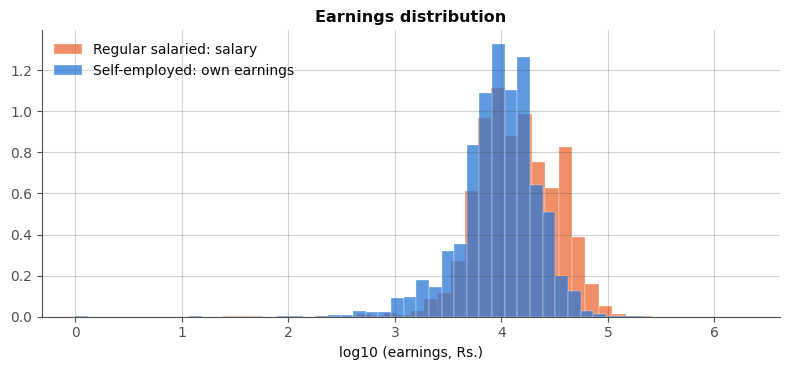

In [23]:
rows = []
for k in CLASSES:
    s = d[d.target == k]
    rows.append({
        "Employment type": k,
        "Persons": len(s),
        "% with salary recorded": (s.earn_sal > 0).mean() * 100,
        "% with self-emp. earnings recorded": (s.earn_self > 0).mean() * 100,
        "Median salary (Rs.)": s.loc[s.earn_sal > 0, "earn_sal"].median(),
        "Median self-emp. earnings (Rs.)": s.loc[s.earn_self > 0, "earn_self"].median()
    })
display(pd.DataFrame(rows).set_index("Employment type").style.format("{:,.1f}", na_rep="-").format({"Persons": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 3.8))
for lab, col, color in [
    ("Regular salaried: salary", "earn_sal", CLS_COL["Regular salaried"]),
    ("Self-employed: own earnings", "earn_self", CLS_COL["Self-employed"])
]:
    grp = "Regular salaried" if col == "earn_sal" else "Self-employed"
    x = np.log10(d.loc[(d.target == grp) & (d[col] > 0), col])
    ax.hist(x, bins=50, alpha=0.75, color=color, label=lab, density=True, edgecolor="white", linewidth=0.3)
ax.set_xlabel("log10 (earnings, Rs.)")
ax.set_title("Earnings distribution")
ax.legend()
plt.tight_layout()
plt.show()

### Step 22A: Strength of association with the target & Correlation Heatmap
Rank candidate features by their association with employment type using **Cramér's V** (for categorical features) and **$\eta^2$ (eta-squared)** (for numeric features), then inspect the **Spearman Rank Correlation Heatmap** across numeric features (including the normalized ordinal rank `edu_rank_norm`).

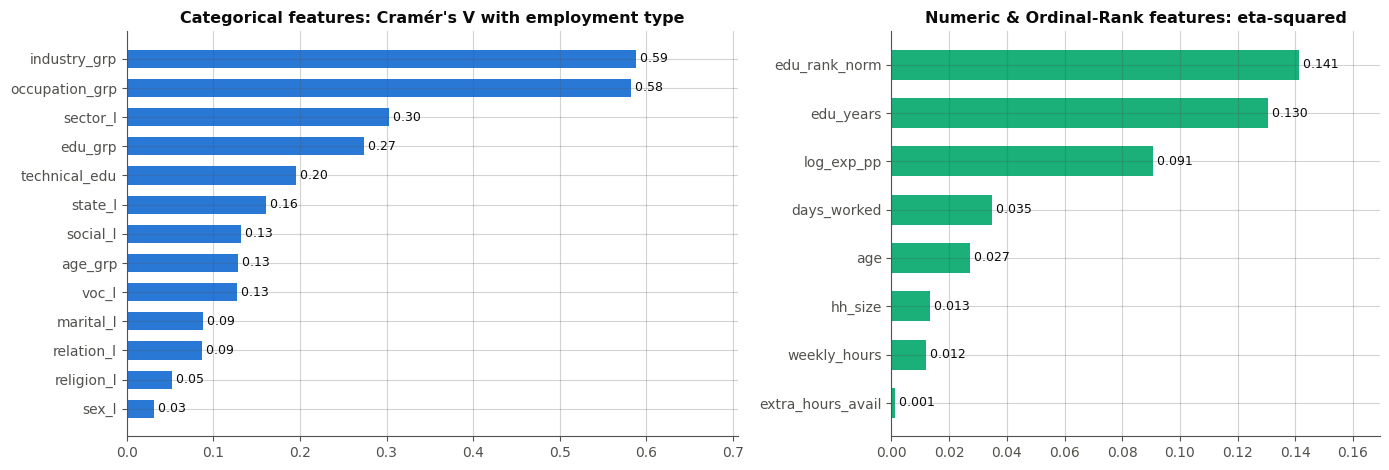

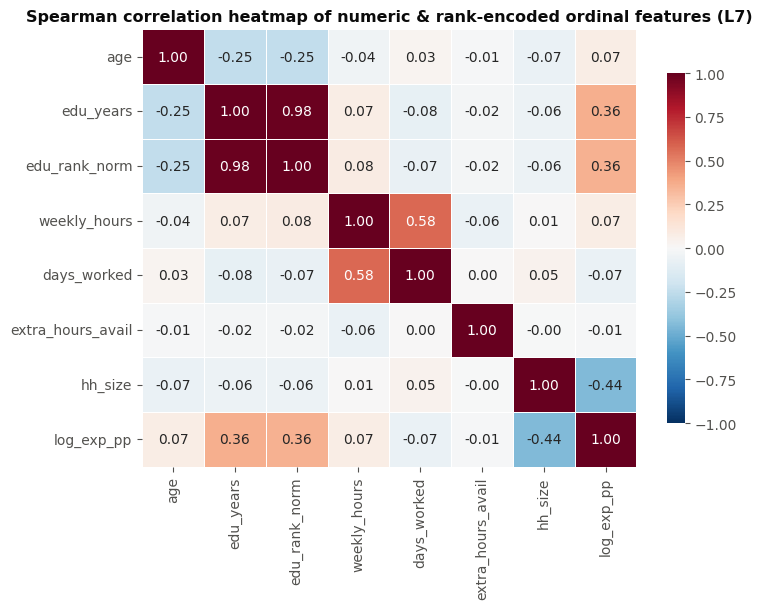

In [24]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1)))

def eta_sq(x, y):
    x = x.astype(float)
    m = x.mean()
    ss_t = ((x - m) ** 2).sum()
    ss_b = sum(len(g) * (g.mean() - m) ** 2 for _, g in x.groupby(y, observed=True))
    return ss_b / ss_t

cat_feats = [
    "sex_l", "sector_l", "state_l", "age_grp", "marital_l", "relation_l",
    "edu_grp", "technical_edu", "voc_l", "religion_l", "social_l", "industry_grp", "occupation_grp"
]
cv = {c: cramers_v(d[c].astype(object).fillna("Missing").astype(str), d.target) for c in cat_feats}
ev = {
    c: eta_sq(d[c].fillna(d[c].median()), d.target)
    for c in ["age", "edu_years", "edu_rank_norm", "weekly_hours", "days_worked", "extra_hours_avail", "hh_size", "log_exp_pp"]
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
s1 = pd.Series(cv).sort_values()
axes[0].barh(s1.index, s1.values, color="#2a78d6", height=0.62)
for y_pos, v in enumerate(s1.values):
    axes[0].text(v, y_pos, f" {v:.2f}", va="center", fontsize=9)
axes[0].set_title("Categorical features: Cramér's V with employment type")
axes[0].set_xlim(0, s1.max() * 1.2)

s2 = pd.Series(ev).sort_values()
axes[1].barh(s2.index, s2.values, color="#1baf7a", height=0.62)
for y_pos, v in enumerate(s2.values):
    axes[1].text(v, y_pos, f" {v:.3f}", va="center", fontsize=9)
axes[1].set_title("Numeric & Ordinal-Rank features: eta-squared")
axes[1].set_xlim(0, s2.max() * 1.2)
plt.tight_layout()
plt.show()

numv2 = ["age", "edu_years", "edu_rank_norm", "weekly_hours", "days_worked", "extra_hours_avail", "hh_size", "log_exp_pp"]
fig, ax = plt.subplots(figsize=(7.8, 6.2))
sns.heatmap(
    d[numv2].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8}
)
ax.set_title("Spearman correlation heatmap of numeric & rank-encoded ordinal features (L7)")
ax.grid(False)
plt.tight_layout()
plt.show()

### Step 22B: Pair Plot (Scatterplot Matrix) & Multi-Encoded Scatter Plot
Implement the two multivariate visual analytics techniques:
1. **Pair Plot (Scatterplot Matrix):** Plots univariate KDE densities on the diagonal and pairwise 2D scatter plots off the diagonal, colour-coded by `target` class (`hue="target"`), on a stratified random sample of $n = 3,000$ workers (1,000 per class).
2. **Scatter Plot with Colour Groupings and Size Encoding:** Encodes 4 variables simultaneously across the 10 industry sectors:
   * **1st Variable (X-axis):** Mean years of formal education (`edu_years`)
   * **2nd Variable (Y-axis):** Median monthly expenditure per person (`exp_per_person`)
   * **3rd Variable (Bubble Size):** Total employed workforce in that industry ($n$)
   * **4th Variable (Colour Grouping):** Dominant employment class in that industry

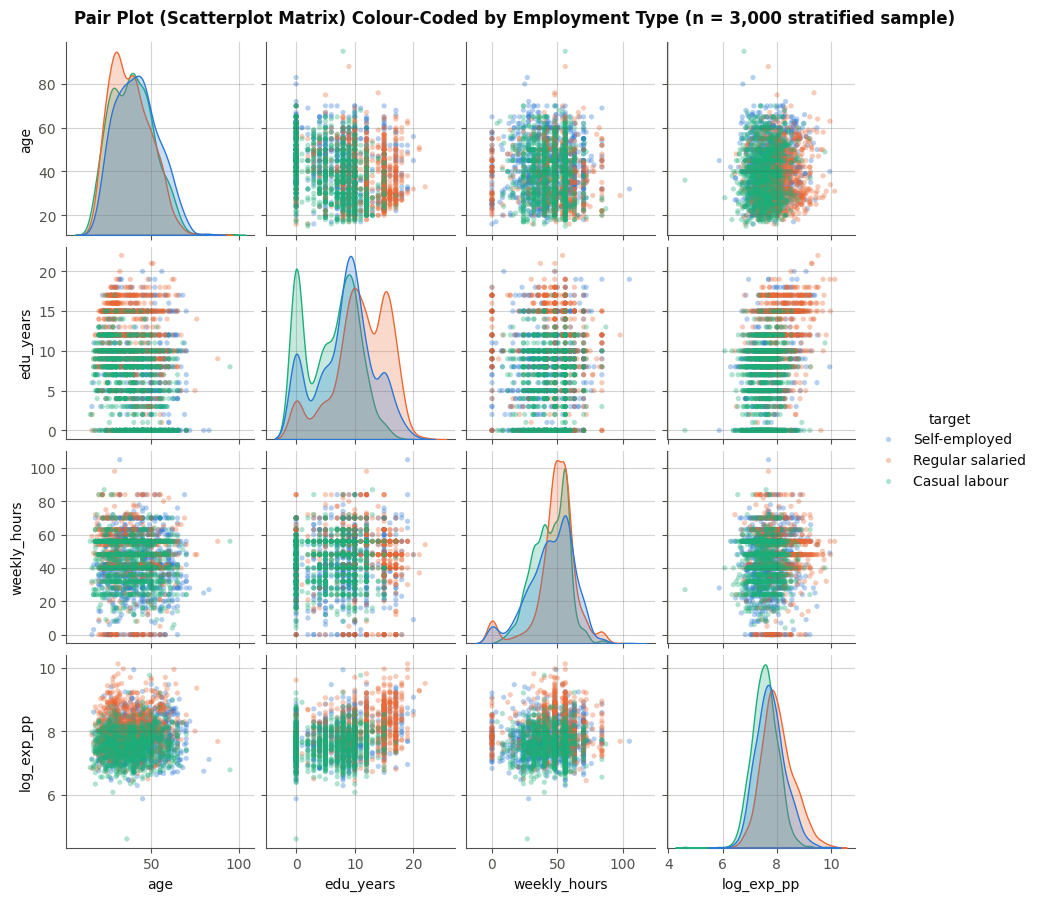

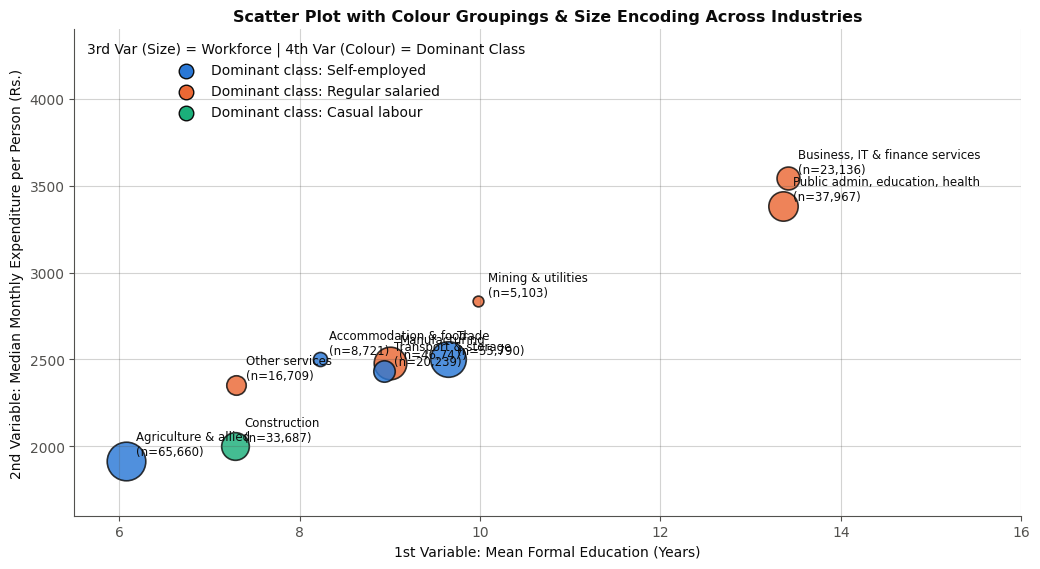

In [25]:
# 1. Pair Plot (Scatterplot Matrix) colour-coded by employment type
sample_pair = (
    d.groupby("target", observed=True, group_keys=False)
    .apply(lambda grp: grp.sample(1000, random_state=42))
)
pair_cols = ["age", "edu_years", "weekly_hours", "log_exp_pp", "target"]

g_pair = sns.pairplot(
    sample_pair[pair_cols], hue="target", hue_order=CLASSES, palette=CLS_COL,
    diag_kind="kde", plot_kws=dict(alpha=0.35, s=14, edgecolor="none"), height=2.2
)
g_pair.fig.suptitle("Pair Plot (Scatterplot Matrix) Colour-Coded by Employment Type (n = 3,000 stratified sample)", fontweight="bold", y=1.02)
plt.show()

# 2. Multi-Variable Scatter Plot with Colour Groupings and Size Encoding
ind_summary = d.groupby("industry_grp", observed=True).agg(
    mean_edu=("edu_years", "mean"),
    median_exp=("exp_per_person", "median"),
    workers=("target", "size"),
    dominant_class=("target", lambda s: s.value_counts().index[0])
).reset_index()

fig, ax = plt.subplots(figsize=(10.5, 5.8))
for _, row in ind_summary.iterrows():
    cls = row["dominant_class"]
    ax.scatter(
        row["mean_edu"], row["median_exp"],
        s=row["workers"] / 85, color=CLS_COL[cls], alpha=0.82, edgecolors=INK, linewidth=1.2
    )
    ax.annotate(
        f"{row['industry_grp']}\n(n={row['workers']:,})",
        (row["mean_edu"], row["median_exp"]),
        xytext=(7, 4), textcoords="offset points", fontsize=8.5
    )

for cls in CLASSES:
    ax.scatter([], [], s=110, color=CLS_COL[cls], edgecolors=INK, label=f"Dominant class: {cls}")

ax.set_title("Scatter Plot with Colour Groupings & Size Encoding Across Industries")
ax.set_xlabel("1st Variable: Mean Formal Education (Years)")
ax.set_ylabel("2nd Variable: Median Monthly Expenditure per Person (Rs.)")
ax.set_xlim(5.5, 16.0)
ax.set_ylim(1600, 4400)
ax.legend(title="3rd Var (Size) = Workforce | 4th Var (Colour) = Dominant Class", loc="upper left")
plt.tight_layout()
plt.show()

### Step 23: Measuring Data Similarity and Dissimilarity
Demonstrate the full suite of proximity measures on 5 real worker records selected from our modelling table (`d`) spanning all three employment classes:
1. **Data Matrix ($n \times p$) vs. Dissimilarity Matrix ($n \times n$):** Inspect the 5-object profile table and compute symmetric $5 \times 5$ pairwise distance matrices satisfying Positive Definiteness ($d(i,i)=0$), Symmetry ($d(i,j)=d(j,i)$), and Triangle Inequality.
2. **Proximity for Nominal Attributes:** $d_{\text{nom}}(i, j) = \frac{p - m}{p}$.
3. **Proximity for Asymmetric Binary Attributes:** Applied to `technical_edu` (`1` = Has technical education, `0` = No) and `voc_training` (`1` = Yes, `0` = No), where negative matches (`0–0`) are ignored:
   $$\text{sim}_{\text{Jaccard}}(i, j) = \frac{q}{q + r + s}, \qquad d_{\text{Jaccard}}(i, j) = \frac{r + s}{q + r + s}$$
4. **Minkowski Distance Family for Numeric Attributes:** Computed on range-normalized numeric attributes:
   * $h = 1$: **Manhattan ($L_1$) Distance**
   * $h = 2$: **Euclidean ($L_2$) Distance**
   * $h \to \infty$: **Chebyshev ($L_\infty$, Supremum) Distance** $\max_f |x_{if} - x_{jf}|$
5. **Proximity for Ordinal Attributes:** Map `edu_grp` ($M_f = 9$) to normalized ranks $z_{if} = \frac{r_{if}-1}{9-1} \in [0, 1]$.
6. **Dissimilarity for Mixed Attributes:**
   $$d(i, j) = \frac{\sum_{f=1}^{p} \delta_{ij}^{(f)} d_{ij}^{(f)}}{\sum_{f=1}^{p} \delta_{ij}^{(f)}}$$
   where $\delta_{ij}^{(f)} = 0$ if $x_{if}$ or $x_{jf}$ is missing (e.g., `voc_training` in revisit records) or if $f$ is asymmetric binary and $x_{if} = x_{jf} = 0$.
7. **Cosine Similarity on One-Hot Encoded Vectors:** $\cos(\mathbf{d}_1, \mathbf{d}_2) = \frac{\mathbf{d}_1 \cdot \mathbf{d}_2}{\|\mathbf{d}_1\|\|\mathbf{d}_2\|}$, which ignores `0–0` matches in sparse dummy matrices.

1. Data Matrix (5 Worker Objects x Mixed Attributes):


,Class (Target),sector_l (Sym. Bin),industry_grp (Nominal),occupation_grp (Nominal),tech_edu (Asym. Bin),voc_train (Asym. Bin),edu_grp (Ordinal),"edu_rank z_if [0,1]",age (Ratio),weekly_hours (Ratio),log_exp_pp (Ratio)
W1 (Self-Emp Agri),Self-employed,Rural,Agriculture & allied,Elementary occupations,0,0.00,Middle,0.38,54.00,70,8.19
W2 (Self-Emp Trade),Self-employed,Rural,Trade,Managers & officials,0,NaN,Not literate,0.00,60.00,49,6.80
W3 (Reg Salaried IT),Regular salaried,Urban,"Business, IT & finance services",Professionals,1,1.00,Graduate,0.88,28.00,40,8.42
W4 (Reg Salaried Edu),Regular salaried,Urban,"Public admin, education, health",Technicians & associates,1,1.00,Graduate,0.88,34.00,30,8.22
W5 (Casual Constr.),Casual labour,Rural,Construction,Craft & trades,0,0.00,Not literate,0.00,40.00,56,7.31


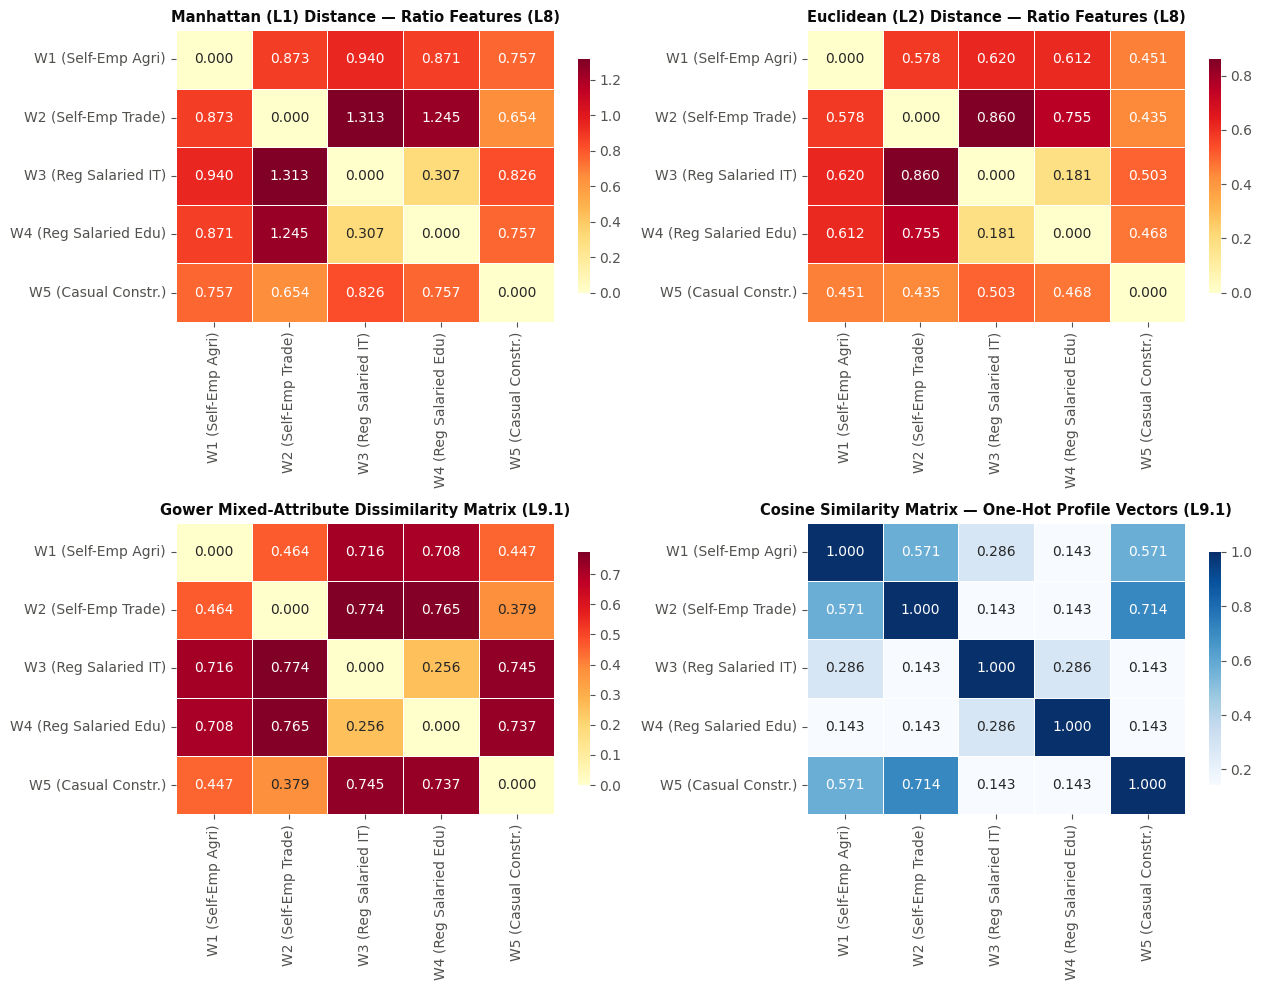

Chebyshev (L_infinity / Supremum) Distance Matrix on Range-Normalized Ratio Features:


,W1 (Self-Emp Agri),W2 (Self-Emp Trade),W3 (Reg Salaried IT),W4 (Reg Salaried Edu),W5 (Casual Constr.)
W1 (Self-Emp Agri),0.00,0.51,0.50,0.48,0.32
W2 (Self-Emp Trade),0.51,0.00,0.61,0.52,0.39
W3 (Reg Salaried IT),0.50,0.61,0.00,0.12,0.41
W4 (Reg Salaried Edu),0.48,0.52,0.12,0.00,0.33
W5 (Casual Constr.),0.32,0.39,0.41,0.33,0.00


In [26]:
# Select 5 real archetypal worker rows from our modelling table `d`:
w1 = d[(d.target == "Self-employed") & (d.sector_l == "Rural") & (d.industry_grp == "Agriculture & allied") & (d.voc_l == "No")].iloc[0]
w2 = d[(d.target == "Self-employed") & (d.sector_l == "Rural") & (d.industry_grp == "Trade") & (d.voc_l == "Not asked (revisit)" if (d.voc_l == "Not asked (revisit)").any() else True)].iloc[0]
w3 = d[(d.target == "Regular salaried") & (d.sector_l == "Urban") & (d.industry_grp == "Business, IT & finance services") & (d.technical_edu == "Has technical education")].iloc[0]
w4 = d[(d.target == "Regular salaried") & (d.sector_l == "Urban") & (d.industry_grp == "Public admin, education, health") & (d.technical_edu == "Has technical education")].iloc[0]
w5 = d[(d.target == "Casual labour") & (d.sector_l == "Rural") & (d.industry_grp == "Construction") & (d.edu_grp == "Not literate")].iloc[0]

labels_w = [
    "W1 (Self-Emp Agri)",
    "W2 (Self-Emp Trade)",
    "W3 (Reg Salaried IT)",
    "W4 (Reg Salaried Edu)",
    "W5 (Casual Constr.)"
]
sub_w = pd.DataFrame([w1, w2, w3, w4, w5], index=labels_w)

# Create clean Data Matrix view showing each DMS672 attribute type
data_matrix_view = pd.DataFrame({
    "Class (Target)": sub_w["target"],
    "sector_l (Sym. Bin)": sub_w["sector_l"],
    "industry_grp (Nominal)": sub_w["industry_grp"],
    "occupation_grp (Nominal)": sub_w["occupation_grp"],
    "tech_edu (Asym. Bin)": (sub_w["technical_edu"] == "Has technical education").astype(int),
    "voc_train (Asym. Bin)": sub_w["voc_l"].map({"Yes": 1.0, "No": 0.0, "Not asked (revisit)": np.nan}),
    "edu_grp (Ordinal)": sub_w["edu_grp"],
    "edu_rank z_if [0,1]": sub_w["edu_rank_norm"].round(3),
    "age (Ratio)": sub_w["age"],
    "weekly_hours (Ratio)": sub_w["weekly_hours"],
    "log_exp_pp (Ratio)": sub_w["log_exp_pp"].round(2)
})
print("1. Data Matrix (5 Worker Objects x Mixed Attributes):")
display(data_matrix_view)

# 2. Minkowski Distances (L1 Manhattan, L2 Euclidean, L_inf Chebyshev) on Range-Normalized Ratio Attributes
ratio_cols = ["age", "weekly_hours", "log_exp_pp"]
# Use 1st-to-99th percentile range of d for normalization (Lecture 9.1)
ranges = (d[ratio_cols].quantile(0.99) - d[ratio_cols].quantile(0.01)).to_numpy()
X_ratio_norm = sub_w[ratio_cols].to_numpy(dtype=float) / ranges

L1_df = pd.DataFrame(squareform(pdist(X_ratio_norm, metric="cityblock")), index=labels_w, columns=labels_w)
L2_df = pd.DataFrame(squareform(pdist(X_ratio_norm, metric="euclidean")), index=labels_w, columns=labels_w)
Linf_df = pd.DataFrame(squareform(pdist(X_ratio_norm, metric="chebyshev")), index=labels_w, columns=labels_w)

# 3. Mixed-Attribute Dissimilarity Matrix (Gower's Unified Formula, Lecture 9.1)
n_obj = len(sub_w)
gower_mat = np.zeros((n_obj, n_obj))
for i in range(n_obj):
    for j in range(n_obj):
        num_s, den_s = 0.0, 0.0
        # (a) Symmetric Binary: sector_l
        d_sec = 0.0 if sub_w.iloc[i]["sector_l"] == sub_w.iloc[j]["sector_l"] else 1.0
        num_s += d_sec; den_s += 1.0
        # (b) Nominal: industry_grp, occupation_grp (Simple Matching)
        for nc in ["industry_grp", "occupation_grp"]:
            d_nom = 0.0 if sub_w.iloc[i][nc] == sub_w.iloc[j][nc] else 1.0
            num_s += d_nom; den_s += 1.0
        # (c) Asymmetric Binary: tech_edu, voc_train (delta_ij = 0 if missing or 0-0 negative match)
        for ac in ["tech_edu (Asym. Bin)", "voc_train (Asym. Bin)"]:
            vi, vj = data_matrix_view.iloc[i][ac], data_matrix_view.iloc[j][ac]
            if pd.isna(vi) or pd.isna(vj) or (vi == 0 and vj == 0):
                delta, d_ab = 0.0, 0.0
            else:
                delta = 1.0
                d_ab = 0.0 if vi == vj else 1.0
            num_s += delta * d_ab; den_s += delta
        # (d) Ordinal: edu_rank_norm z_if in [0, 1]
        d_ord = abs(sub_w.iloc[i]["edu_rank_norm"] - sub_w.iloc[j]["edu_rank_norm"])
        num_s += d_ord; den_s += 1.0
        # (e) Ratio Numeric: range-normalized
        for k_idx, rc_col in enumerate(ratio_cols):
            d_rat = min(1.0, abs(sub_w.iloc[i][rc_col] - sub_w.iloc[j][rc_col]) / ranges[k_idx])
            num_s += d_rat; den_s += 1.0
        gower_mat[i, j] = num_s / den_s

gower_df = pd.DataFrame(gower_mat, index=labels_w, columns=labels_w)

# 4. Cosine Similarity on One-Hot Encoded Nominal/Binary Features (Lecture 9.1)
ohe_sub = pd.get_dummies(sub_w[["sector_l", "sex_l", "marital_l", "social_l", "industry_grp", "occupation_grp", "technical_edu"]], dtype=float)
cos_sim_df = pd.DataFrame(cosine_similarity(ohe_sub), index=labels_w, columns=labels_w)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, mat, title, cmap in [
    (axes[0, 0], L1_df, "Manhattan (L1) Distance — Ratio Features (L8)", "YlOrRd"),
    (axes[0, 1], L2_df, "Euclidean (L2) Distance — Ratio Features (L8)", "YlOrRd"),
    (axes[1, 0], gower_df, "Gower Mixed-Attribute Dissimilarity Matrix (L9.1)", "YlOrRd"),
    (axes[1, 1], cos_sim_df, "Cosine Similarity Matrix — One-Hot Profile Vectors (L9.1)", "Blues")
]:
    sns.heatmap(mat, annot=True, fmt=".3f", cmap=cmap, linewidths=0.6, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(title, fontsize=10.5)
    ax.grid(False)

plt.tight_layout()
plt.show()

print("Chebyshev (L_infinity / Supremum) Distance Matrix on Range-Normalized Ratio Features:")
display(Linf_df.round(3))

# Part 2: Data Preprocessing

The EDA has established the modelling population, target classes, candidate predictors, and variables that must not enter the feature matrix. The following steps turn the engineered table d into train/validation data and prepare several representations for downstream modelling.

The main preprocessing decisions are:
- keep the three employment classes as the target;
- keep household identifiers only for grouped splitting, never as predictors;
- exclude earnings, household type, daily status codes, usual-status fields, survey design identifiers, and other variables already marked as leakage or unsuitable;
- retain voc_l = "Not asked (revisit)" as a meaningful survey state rather than treating it as an ordinary missing value;
- use training data only when learning imputation values, scaling parameters, bin edges, or principal components.

### Step 24:
Define the modelling features and create a household-level split
Use the predictors already identified in the EDA. age_grp is not included because age is retained; edu_grp is represented by its normalized ordinal rank, edu_rank_norm; and exp_per_person is represented by its log-transformed version, log_exp_pp.

Because some households appear in both first-visit and revisit records, split by hh_id. This keeps all records from a household in either the training set or the validation set. Stratification attempts to preserve the three target-class proportions.

In [27]:
from sklearn.model_selection import StratifiedGroupKFold

numeric_features = [
    "age",
    "edu_years",
    "edu_rank_norm",
    "hh_size",
    "weekly_hours",
    "days_worked",
    "extra_hours_avail",
    "log_exp_pp"
]

categorical_features = [
    "sex_l",
    "sector_l",
    "state_l",
    "marital_l",
    "relation_l",
    "religion_l",
    "social_l",
    "technical_edu",
    "voc_l",
    "industry_grp",
    "occupation_grp"
]

feature_columns = numeric_features + categorical_features

forbidden_features = {
    "target", "cws", "earn_sal", "earn_self", "hh_type", "hh_id",
    "source", "visit", "weight", "mult", "nss", "nsc"
}
assert forbidden_features.isdisjoint(feature_columns), "A leakage/design column entered the feature list."

# Keep only records with a defined target and the columns required below.
model_df = d.loc[d["target"].notna(), feature_columns + ["target", "hh_id"]].copy()
model_df = model_df.reset_index(drop=True)

X = model_df[feature_columns].copy()
y = model_df["target"].astype(str).copy()
groups = model_df["hh_id"].astype(str).copy()

# Keep categorical values as objects so the missing-value placeholder is consistent.
for col in categorical_features:
    X[col] = X[col].astype("object")

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, valid_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_valid = X.iloc[valid_idx].copy()
y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_valid = groups.iloc[valid_idx].copy()

assert set(groups_train).isdisjoint(set(groups_valid)), "A household appears in both splits."

split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True).reindex(CLASSES) * 100,
    "Validation": y_valid.value_counts(normalize=True).reindex(CLASSES) * 100
})
display(split_summary.round(2))
print(f"Training records: {len(X_train):,} | Validation records: {len(X_valid):,}")
print(f"Training households: {groups_train.nunique():,} | Validation households: {groups_valid.nunique():,}")
print("Household overlap:", len(set(groups_train) & set(groups_valid)))

,Training,Validation
target,,
Self-employed,47.78,47.24
Regular salaried,37.83,38.35
Casual labour,14.39,14.40


Training records: 250,148 | Validation records: 63,611
Training households: 76,203 | Validation households: 19,421
Household overlap: 0


###Step 25: Review missing values and choose imputation methods
First inspect missingness in the selected predictors. Numeric variables are imputed with the training-set median. Nominal variables use a separate "Missing" category, so a missing category is not silently replaced by the most common state.

The "Not asked (revisit)" value in voc_l is already an explicit survey state and remains separate from "Missing". Imputation is fitted only on the training set. Compare distributions before and after imputation to identify potentially important shifts.

In [28]:
missing_profile = pd.DataFrame({
    "Missing count": X_train.isna().sum(),
    "Missing (%)": X_train.isna().mean() * 100
}).sort_values("Missing (%)", ascending=False)

display(missing_profile.round(3))

# Compare numeric distributions before and after median imputation.
from sklearn.impute import SimpleImputer

numeric_imputer_check = SimpleImputer(strategy="median")
numeric_train_imputed_check = pd.DataFrame(
    numeric_imputer_check.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

distribution_before = X_train[numeric_features].describe().T[
    ["mean", "50%", "std", "min", "max"]
].add_suffix(" (before)")
distribution_after = numeric_train_imputed_check.describe().T[
    ["mean", "50%", "std", "min", "max"]
].add_suffix(" (after)")

imputation_comparison = distribution_before.join(distribution_after)
display(imputation_comparison.round(3))

print(
    'Revisit "Not asked" records in voc_l:',
    int(X_train["voc_l"].eq("Not asked (revisit)").sum())
)
print(
    'Actual missing records in voc_l:',
    int(X_train["voc_l"].isna().sum())
)

,Missing count,Missing (%)
occupation_grp,777,0.31
edu_rank_norm,78,0.03
marital_l,23,0.01
relation_l,2,0.00
age,0,0.00
edu_years,0,0.00
hh_size,0,0.00
log_exp_pp,0,0.00
weekly_hours,0,0.00
days_worked,0,0.00


,mean (before),50% (before),std (before),min (before),max (before),mean (after),50% (after),std (after),min (after),max (after)
age,39.85,40.00,12.36,15.00,97.00,39.85,40.00,12.36,15.00,97.00
edu_years,9.07,10.00,5.13,0.00,29.00,9.07,10.00,5.13,0.00,29.00
edu_rank_norm,0.46,0.38,0.30,0.00,1.00,0.46,0.38,0.30,0.00,1.00
hh_size,4.60,4.00,1.99,1.00,24.00,4.60,4.00,1.99,1.00,24.00
weekly_hours,46.28,48.00,15.91,0.00,140.00,46.28,48.00,15.91,0.00,140.00
days_worked,6.06,7.00,1.52,0.00,7.00,6.06,7.00,1.52,0.00,7.00
extra_hours_avail,0.21,0.00,2.02,0.00,70.00,0.21,0.00,2.02,0.00,70.00
log_exp_pp,7.83,7.78,0.57,4.62,14.33,7.83,7.78,0.57,4.62,14.33


Revisit "Not asked" records in voc_l: 141009
Actual missing records in voc_l: 0


###Step 26: Check invalid values, noise, and potential outliers
A statistical outlier is not automatically an error. A rare observation may be a genuine worker profile, so the code below flags observations for inspection rather than deleting them automatically.

The interquartile-range rule is applied to the training data. Domain checks are reported separately. The expenditure feature is already log-transformed because its raw per-person distribution is strongly right-skewed; the raw value is not added alongside the log value.

The final cell also demonstrates equal-frequency bin smoothing by replacing values within each bin with that bin's median. The smoothed series is diagnostic only and does not overwrite the original feature.

,Records flagged
Age below 15 or above 110,0
Education years below 0 or above 50,0
Household size below 1,0
Weekly hours outside 0-168,0
Days worked outside 0-7,0
Extra hours outside 0-168,0


,Q1,Q3,IQR,Lower fence,Upper fence,Flagged records,Flagged (%)
Feature,,,,,,,
age,30.00,49.00,19.00,1.50,77.50,309,0.12
edu_years,6.00,12.00,6.00,-3.00,21.00,181,0.07
edu_rank_norm,0.25,0.62,0.38,-0.31,1.19,0,0.00
hh_size,3.00,6.00,3.00,-1.50,10.50,3267,1.31
weekly_hours,39.00,56.00,17.00,13.50,81.50,13450,5.38
days_worked,6.00,7.00,1.00,4.50,8.50,26847,10.73
extra_hours_avail,0.00,0.00,0.00,0.00,0.00,4615,1.84
log_exp_pp,7.43,8.17,0.74,6.32,9.28,3823,1.53


,Original,After bin-median smoothing
count,"250,148.00","250,148.00"
mean,7.83,7.83
std,0.57,0.53
min,4.62,6.97
25%,7.43,7.43
50%,7.78,7.72
75%,8.17,8.17
max,14.33,8.85


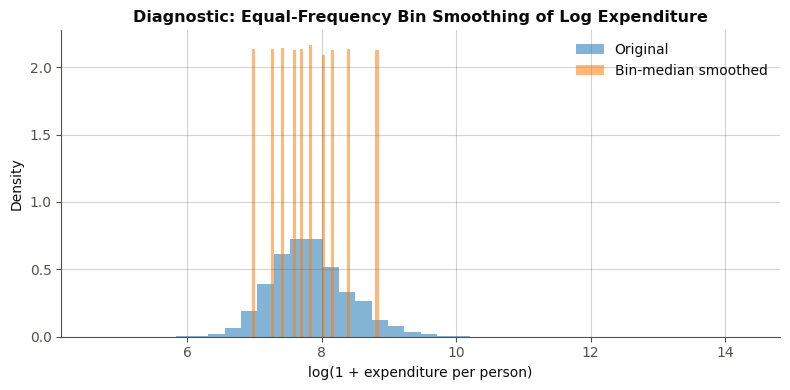

In [29]:
# Plausibility checks: report counts, but do not automatically discard observations.
domain_checks = pd.Series({
    "Age below 15 or above 110": ((X_train["age"] < 15) | (X_train["age"] > 110)).sum(),
    "Education years below 0 or above 50": ((X_train["edu_years"] < 0) | (X_train["edu_years"] > 50)).sum(),
    "Household size below 1": (X_train["hh_size"] < 1).sum(),
    "Weekly hours outside 0-168": ((X_train["weekly_hours"] < 0) | (X_train["weekly_hours"] > 168)).sum(),
    "Days worked outside 0-7": ((X_train["days_worked"] < 0) | (X_train["days_worked"] > 7)).sum(),
    "Extra hours outside 0-168": ((X_train["extra_hours_avail"] < 0) | (X_train["extra_hours_avail"] > 168)).sum()
}, name="Records flagged")

display(domain_checks.to_frame())

# IQR-based outlier flags on the training partition.
iqr_rows = []
for col in numeric_features:
    s = pd.to_numeric(X_train[col], errors="coerce").dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = ((s < lower) | (s > upper)).sum()
    iqr_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower fence": lower,
        "Upper fence": upper,
        "Flagged records": int(flagged),
        "Flagged (%)": flagged / len(s) * 100
    })

iqr_report = pd.DataFrame(iqr_rows).set_index("Feature")
display(iqr_report.round(3))

# Equal-frequency bin smoothing by bin medians (diagnostic only).
def smooth_by_bin_median(series, n_bins=10):
    series = pd.to_numeric(series, errors="coerce")
    valid = series.dropna()
    bins = pd.qcut(valid, q=n_bins, duplicates="drop")
    smoothed = valid.groupby(bins, observed=True).transform("median")
    result = pd.Series(index=series.index, dtype=float)
    result.loc[valid.index] = smoothed
    return result

raw_log_exp = X_train["log_exp_pp"].astype(float)
smoothed_log_exp = smooth_by_bin_median(raw_log_exp, n_bins=10)

smoothing_comparison = pd.DataFrame({
    "Original": raw_log_exp.describe(),
    "After bin-median smoothing": smoothed_log_exp.describe()
})
display(smoothing_comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(raw_log_exp.dropna(), bins=40, alpha=0.55, density=True, label="Original")
ax.hist(smoothed_log_exp.dropna(), bins=40, alpha=0.55, density=True, label="Bin-median smoothed")
ax.set_title("Diagnostic: Equal-Frequency Bin Smoothing of Log Expenditure")
ax.set_xlabel("log(1 + expenditure per person)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

###Step 27: Detect redundant attributes and rank candidate predictors
Use Spearman correlation to detect strongly related numeric attributes. For categorical attributes, use a chi-square test of independence and the bias-corrected Cramér's V effect size. Large Cramér's V values can indicate that two attributes carry overlapping information.

Also measure each feature's association with the target using Cramér's V for categorical predictors and eta-squared for numeric predictors. These results are calculated on the training data only. They are diagnostic rankings, not proof of causation, and no feature is removed automatically based on a p-value alone.

In [30]:
from itertools import combinations

# Numeric redundancy: Spearman rank correlation.
numeric_corr = X_train[numeric_features].corr(method="spearman")
display(numeric_corr.round(3))

numeric_pairs = []
for c1, c2 in combinations(numeric_features, 2):
    value = numeric_corr.loc[c1, c2]
    if pd.notna(value) and abs(value) >= 0.85:
        numeric_pairs.append({
            "Feature 1": c1,
            "Feature 2": c2,
            "Spearman correlation": value
        })

print("Numeric pairs with |Spearman correlation| >= 0.85:")
display(pd.DataFrame(numeric_pairs).round(3))

def corrected_cramers_v_from_table(ct):
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]
    if min(ct.shape) < 2:
        return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    if n <= 1:
        return np.nan
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan

# Categorical-categorical redundancy using chi-square and Cramér's V.
categorical_pairs = []
for c1, c2 in combinations(categorical_features, 2):
    a = X_train[c1].fillna("Missing").astype(str)
    b = X_train[c2].fillna("Missing").astype(str)
    ct = pd.crosstab(a, b)
    if min(ct.shape) >= 2:
        chi2, p_value, dof, expected = stats.chi2_contingency(ct, correction=False)
        categorical_pairs.append({
            "Feature 1": c1,
            "Feature 2": c2,
            "Chi-square p-value": p_value,
            "Cramér's V": corrected_cramers_v_from_table(ct),
            "Minimum expected frequency": expected.min()
        })

categorical_pair_report = pd.DataFrame(categorical_pairs).sort_values(
    "Cramér's V", ascending=False
)
display(categorical_pair_report.head(20).round(4))

# Feature-target association, computed on the training partition only.
association_rows = []

for col in categorical_features:
    ct = pd.crosstab(X_train[col].fillna("Missing").astype(str), y_train)
    if min(ct.shape) >= 2:
        chi2, p_value, dof, expected = stats.chi2_contingency(ct, correction=False)
        association_rows.append({
            "Feature": col,
            "Type": "Categorical",
            "Association": corrected_cramers_v_from_table(ct),
            "Chi-square p-value": p_value
        })

for col in numeric_features:
    temp = pd.DataFrame({
        "value": pd.to_numeric(X_train[col], errors="coerce"),
        "target": y_train
    }).dropna()
    grand_mean = temp["value"].mean()
    ss_total = ((temp["value"] - grand_mean) ** 2).sum()
    ss_between = sum(
        len(group) * (group.mean() - grand_mean) ** 2
        for _, group in temp.groupby("target", observed=True)["value"]
    )
    eta2 = ss_between / ss_total if ss_total > 0 else np.nan
    association_rows.append({
        "Feature": col,
        "Type": "Numeric / ordinal rank",
        "Association": eta2,
        "Chi-square p-value": np.nan
    })

association_report = pd.DataFrame(association_rows).sort_values(
    "Association", ascending=False
)
display(association_report.round(4))

,age,edu_years,edu_rank_norm,hh_size,weekly_hours,days_worked,extra_hours_avail,log_exp_pp
age,1.00,-0.25,-0.25,-0.07,-0.04,0.03,-0.01,0.07
edu_years,-0.25,1.00,0.98,-0.06,0.07,-0.08,-0.02,0.36
edu_rank_norm,-0.25,0.98,1.00,-0.06,0.08,-0.08,-0.02,0.36
hh_size,-0.07,-0.06,-0.06,1.00,0.01,0.05,-0.00,-0.45
weekly_hours,-0.04,0.07,0.08,0.01,1.00,0.58,-0.06,0.07
days_worked,0.03,-0.08,-0.08,0.05,0.58,1.00,0.00,-0.07
extra_hours_avail,-0.01,-0.02,-0.02,-0.00,-0.06,0.00,1.00,-0.01
log_exp_pp,0.07,0.36,0.36,-0.45,0.07,-0.07,-0.01,1.00


Numeric pairs with |Spearman correlation| >= 0.85:


,Feature 1,Feature 2,Spearman correlation
0,edu_years,edu_rank_norm,0.98


,Feature 1,Feature 2,Chi-square p-value,Cramér's V,Minimum expected frequency
16,sector_l,voc_l,0.00,0.60,"7,840.82"
17,sector_l,industry_grp,0.00,0.57,"1,164.78"
3,sex_l,relation_l,0.00,0.54,0.00
21,state_l,religion_l,0.00,0.52,1.65
18,sector_l,occupation_grp,0.00,0.51,222.26
27,marital_l,relation_l,0.00,0.47,0.00
54,industry_grp,occupation_grp,0.00,0.47,12.65
22,state_l,social_l,0.00,0.45,10.95
40,religion_l,social_l,0.00,0.34,544.81
51,technical_edu,occupation_grp,0.00,0.33,49.83


,Feature,Type,Association,Chi-square p-value
9,industry_grp,Categorical,0.59,0.00
10,occupation_grp,Categorical,0.58,0.00
1,sector_l,Categorical,0.30,0.00
7,technical_edu,Categorical,0.20,0.00
2,state_l,Categorical,0.16,0.00
13,edu_rank_norm,Numeric / ordinal rank,0.14,NaN
12,edu_years,Numeric / ordinal rank,0.13,NaN
6,social_l,Categorical,0.13,0.00
8,voc_l,Categorical,0.13,0.00
18,log_exp_pp,Numeric / ordinal rank,0.09,NaN


###Step 28: Impute, encode, and normalize the modelling features
The main preprocessing pipeline uses:
- median imputation for numeric features;
- robust standardization using the median and interquartile range;
- a "Missing" category for missing nominal values;
- one-hot encoding for nominal and binary categories.

RobustScaler is used because several variables are skewed or contain extreme observations. The fitted pipeline learns all imputation and scaling parameters from X_train and applies the same transformations to X_valid. The household identifier and target are not included in either feature matrix.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from scipy import sparse

def make_one_hot_encoder():
    # Support both newer and older scikit-learn parameter names.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", make_one_hot_encoder())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit only on training data; validation data uses the already-fitted transformations.
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

processed_feature_names = preprocessor.get_feature_names_out()

def matrix_summary(matrix, name):
    if sparse.issparse(matrix):
        nnz = matrix.nnz
        density = nnz / (matrix.shape[0] * matrix.shape[1])
    else:
        nnz = np.count_nonzero(matrix)
        density = nnz / matrix.size
    return {
        "Dataset": name,
        "Rows": matrix.shape[0],
        "Encoded features": matrix.shape[1],
        "Non-zero entries": int(nnz),
        "Density (%)": density * 100,
        "Sparse matrix": sparse.issparse(matrix)
    }

display(pd.DataFrame([
    matrix_summary(X_train_processed, "Training"),
    matrix_summary(X_valid_processed, "Validation")
]).set_index("Dataset").round(3))

print("First 20 encoded feature names:")
print(processed_feature_names[:20].tolist())

# Optional: persist the fitted transformation for consistent future use.
# import joblib
# joblib.dump(preprocessor, "plfs_preprocessor.joblib")

,Rows,Encoded features,Non-zero entries,Density (%),Sparse matrix
Dataset,,,,,
Training,250148,99,4163200,16.81,True
Validation,63611,99,1058145,16.80,True


First 20 encoded feature names:
['numeric__age', 'numeric__edu_years', 'numeric__edu_rank_norm', 'numeric__hh_size', 'numeric__weekly_hours', 'numeric__days_worked', 'numeric__extra_hours_avail', 'numeric__log_exp_pp', 'numeric__missingindicator_edu_rank_norm', 'categorical__sex_l_Female', 'categorical__sex_l_Male', 'categorical__sex_l_Transgender', 'categorical__sector_l_Rural', 'categorical__sector_l_Urban', 'categorical__state_l_A&N Islands', 'categorical__state_l_Andhra Pradesh', 'categorical__state_l_Arunachal Pradesh', 'categorical__state_l_Assam', 'categorical__state_l_Bihar', 'categorical__state_l_Chandigarh']


###Step 29: Discretize continuous attributes
Discretization converts continuous attributes into intervals. The code below creates two alternatives on selected numeric features:
- Equal-frequency bins: approximately the same number of training observations in each bin. This is useful for skewed distributions.
- Equal-width bins: intervals have the same numerical width, although their observation counts can differ.

Bin edges are learned from the training set and then reused for validation data. The discretized representation is kept separate from the main continuous feature matrix; do not include both versions of the same variable without a modelling reason.

In [32]:
from sklearn.preprocessing import KBinsDiscretizer

discretize_features = ["age", "weekly_hours", "log_exp_pp"]

# Bin edges are learned from the training set after median imputation.
bin_imputer = SimpleImputer(strategy="median")
X_train_bins_input = bin_imputer.fit_transform(X_train[discretize_features])
X_valid_bins_input = bin_imputer.transform(X_valid[discretize_features])

quantile_discretizer = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    random_state=42
)
uniform_discretizer = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="uniform",
    random_state=42
)

X_train_quantile_bins = pd.DataFrame(
    quantile_discretizer.fit_transform(X_train_bins_input),
    columns=[f"{c}_quantile_bin" for c in discretize_features],
    index=X_train.index
)
X_valid_quantile_bins = pd.DataFrame(
    quantile_discretizer.transform(X_valid_bins_input),
    columns=[f"{c}_quantile_bin" for c in discretize_features],
    index=X_valid.index
)

X_train_uniform_bins = pd.DataFrame(
    uniform_discretizer.fit_transform(X_train_bins_input),
    columns=[f"{c}_equal_width_bin" for c in discretize_features],
    index=X_train.index
)
X_valid_uniform_bins = pd.DataFrame(
    uniform_discretizer.transform(X_valid_bins_input),
    columns=[f"{c}_equal_width_bin" for c in discretize_features],
    index=X_valid.index
)

bin_summary = pd.DataFrame({
    "Feature": discretize_features,
    "Actual quantile bins": quantile_discretizer.n_bins_,
    "Actual equal-width bins": uniform_discretizer.n_bins_
})
display(bin_summary)

print("Equal-frequency bin counts in the training set:")
for col in X_train_quantile_bins.columns:
    print(f"\n{col}")
    display(X_train_quantile_bins[col].value_counts().sort_index().rename("Records").to_frame())

,Feature,Actual quantile bins,Actual equal-width bins
0,age,5,5
1,weekly_hours,5,5
2,log_exp_pp,5,5


Equal-frequency bin counts in the training set:

age_quantile_bin


,Records
age_quantile_bin,
0.00,45554
1.00,44655
2.00,59516
3.00,40480
4.00,59943



weekly_hours_quantile_bin


,Records
weekly_hours_quantile_bin,
0.00,46764
1.00,52704
2.00,48844
3.00,9058
4.00,92778



log_exp_pp_quantile_bin


,Records
log_exp_pp_quantile_bin,
0.00,49907
1.00,50069
2.00,49709
3.00,50285
4.00,50178


###Step 30: Apply PCA to the numeric attributes
Principal Component Analysis (PCA) creates orthogonal components that retain as much variation as possible in the input attributes. It is unsupervised: the target is not used to calculate the components.

Here PCA is applied to the numeric and normalized ordinal-rank block only. Nominal variables remain in the one-hot encoded representation. The number of components is selected to retain at least 95% of the variance in the training data. This is an optional reduced representation; compare it with the original features before choosing it for a model.

,Principal Component,Explained variance ratio,Cumulative explained variance
0,PC1,0.41,0.41
1,PC2,0.28,0.69
2,PC3,0.15,0.84
3,PC4,0.07,0.91
4,PC5,0.04,0.94
5,PC6,0.03,0.97


Numeric block before PCA: (250148, 8)
Numeric block after PCA: (250148, 6)


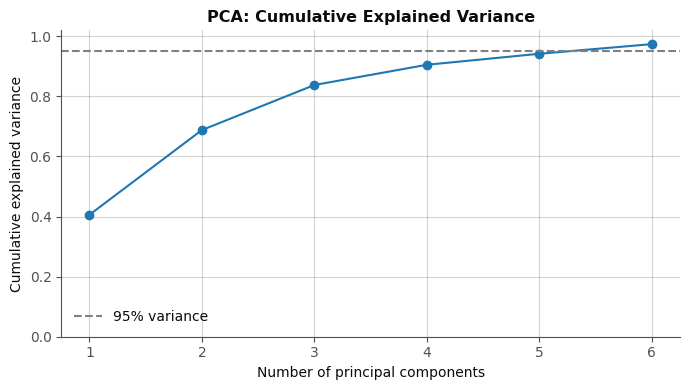

In [33]:
from sklearn.decomposition import PCA

pca_numeric_imputer = SimpleImputer(strategy="median")
pca_numeric_scaler = RobustScaler()

X_num_train_imputed = pca_numeric_imputer.fit_transform(X_train[numeric_features])
X_num_valid_imputed = pca_numeric_imputer.transform(X_valid[numeric_features])

X_num_train_scaled = pca_numeric_scaler.fit_transform(X_num_train_imputed)
X_num_valid_scaled = pca_numeric_scaler.transform(X_num_valid_imputed)

pca_numeric = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca_numeric.fit_transform(X_num_train_scaled)
X_valid_pca = pca_numeric.transform(X_num_valid_scaled)

pca_report = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(pca_numeric.explained_variance_ratio_))],
    "Explained variance ratio": pca_numeric.explained_variance_ratio_,
    "Cumulative explained variance": np.cumsum(pca_numeric.explained_variance_ratio_)
})
display(pca_report.round(4))

print("Numeric block before PCA:", X_num_train_scaled.shape)
print("Numeric block after PCA:", X_train_pca.shape)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    range(1, len(pca_report) + 1),
    pca_report["Cumulative explained variance"],
    marker="o"
)
ax.axhline(0.95, linestyle="--", color="grey", label="95% variance")
ax.set_xticks(range(1, len(pca_report) + 1))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA: Cumulative Explained Variance")
ax.legend()
plt.tight_layout()
plt.show()

###Step 31: Create a stratified sample for faster experimentation
Sampling reduces the number of records used in computationally expensive experiments. The sample below is drawn without replacement from the training partition and stratified by employment type, so each class is represented in approximately the same proportion as in the training data.

Use this sample for quick diagnostic plots or initial experiments. The full training set remains available for final model fitting.

In [34]:
train_for_sampling = X_train.copy()
train_for_sampling["target"] = y_train

sample_fraction = 0.10
stratified_sample = (
    train_for_sampling
    .groupby("target", group_keys=False, observed=True)
    .sample(frac=sample_fraction, random_state=42)
)

sample_summary = pd.DataFrame({
    "Full training set": y_train.value_counts(normalize=True).reindex(CLASSES) * 100,
    "Stratified sample": (
        stratified_sample["target"].value_counts(normalize=True).reindex(CLASSES) * 100
    )
})
display(sample_summary.round(2))

print(f"Full training set: {len(train_for_sampling):,} records")
print(f"Stratified sample: {len(stratified_sample):,} records")
print("Sampling is without replacement:", len(stratified_sample) == stratified_sample.index.nunique())

,Full training set,Stratified sample
target,,
Self-employed,47.78,47.79
Regular salaried,37.83,37.83
Casual labour,14.39,14.39


Full training set: 250,148 records
Stratified sample: 25,014 records
Sampling is without replacement: True


###Step 32: Final preprocessing outputs
The following objects are now available for downstream modelling:
- X_train_processed, X_valid_processed: imputed, robust-scaled, and one-hot encoded matrices;
- y_train, y_valid: target labels;
- preprocessor: fitted transformation pipeline to apply consistently to new data;
- X_train_quantile_bins, X_valid_quantile_bins: equal-frequency discretized representation;
- X_train_uniform_bins, X_valid_uniform_bins: equal-width discretized representation;
- X_train_pca, X_valid_pca: PCA representation of the numeric block;
- stratified_sample: reduced training sample for quick experimentation.

The main processed matrices are the default starting point. The discretized and PCA representations are alternatives to evaluate, not transformations that must be combined with the main matrix.

## Part 3: Classification Modelling, Evaluation, and Improvement

### Step 33: Set up target encoding, balanced class weights, and evaluation helpers
Prepare the integer-encoded target arrays (`0 = Self-employed`, `1 = Regular salaried`, `2 = Casual labour`), compute inverse-frequency class weights to address the $3.31 : 1$ class imbalance, and define a standardized evaluation function that reports **Accuracy**, **Error Rate**, **Macro/Weighted Precision, Recall (Sensitivity), $F_1$**, **Recall-weighted $F_2$** ($\beta = 2$), **Specificity ($\text{TN}/\text{N}$)**, **Casual labour Recall**, and **Multiclass One-vs-Rest ROC-AUC**.

In [35]:
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, confusion_matrix, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

# Map string target labels to integer codes 0, 1, 2 matching CLASSES order
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
y_train_idx = y_train.map(CLASS_TO_IDX).to_numpy()
y_valid_idx = y_valid.map(CLASS_TO_IDX).to_numpy()
y_valid_bin = label_binarize(y_valid_idx, classes=[0, 1, 2])

# Balanced class weights from training labels
cw_vals = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train_idx)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw_vals)}
sample_weight_train = np.array([CLASS_WEIGHTS[i] for i in y_train_idx], dtype=np.float32)

print("Target class mapping:", CLASS_TO_IDX)
print("Balanced class weights:", {CLASSES[i]: round(w, 3) for i, w in CLASS_WEIGHTS.items()})

# Store model predictions, probabilities, and summary metrics for final comparison
MODEL_RESULTS = []
MODEL_PREDS = {}
MODEL_PROBAS = {}

def evaluate_classifier(name, y_true, y_pred, y_proba=None, train_time=None):
    acc = accuracy_score(y_true, y_pred) * 100
    err = 100.0 - acc
    prec_m = precision_score(y_true, y_pred, average="macro", zero_division=0) * 100
    rec_m = recall_score(y_true, y_pred, average="macro", zero_division=0) * 100
    f1_m = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100
    f1_w = f1_score(y_true, y_pred, average="weighted", zero_division=0) * 100
    f2_m = fbeta_score(y_true, y_pred, beta=2.0, average="macro", zero_division=0) * 100

    # Per-class recall and One-vs-All Specificity (TN / (TN + FP))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    rec_per_cls = recall_score(y_true, y_pred, average=None, zero_division=0) * 100
    specs = []
    for k in range(3):
        tp = cm[k, k]
        fn = cm[k, :].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specs.append(tn / (tn + fp) * 100)
    spec_m = float(np.mean(specs))

    auc_m = (
        roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro") * 100
        if y_proba is not None else np.nan
    )
    row = {
        "Model": name,
        "Accuracy (%)": acc,
        "Error Rate (%)": err,
        "Macro Precision (%)": prec_m,
        "Macro Recall / Sensitivity (%)": rec_m,
        "Macro Specificity (%)": spec_m,
        "Macro F1 (%)": f1_m,
        "Macro F2 (%)": f2_m,
        "Weighted F1 (%)": f1_w,
        "Casual Labour Recall (%)": rec_per_cls[2],
        "Macro ROC-AUC (%)": auc_m,
        "Train Time (s)": train_time if train_time is not None else np.nan
    }
    MODEL_RESULTS.append(row)
    MODEL_PREDS[name] = y_pred
    if y_proba is not None:
        MODEL_PROBAS[name] = y_proba
    return row

Target class mapping: {'Self-employed': 0, 'Regular salaried': 1, 'Casual labour': 2}
Balanced class weights: {'Self-employed': 0.698, 'Regular salaried': 0.881, 'Casual labour': 2.317}


### Step 34: Decision Tree Induction — Gini Index vs. Information Gain (Entropy) and Pre-Pruning
Evaluate recursive partitioning Decision Trees under two impurity measures:
1. **Gini Index (CART):** $\text{Gini}(D) = 1 - \sum_{i=1}^{m} p_i^2$.
2. **Information Gain / Entropy (ID3 / C4.5):** $\text{Info}(D) = -\sum_{i=1}^{m} p_i \log_2(p_i)$.

Compare unconstrained (unpruned) trees against pre-pruned trees (`max_depth=12`, `min_samples_leaf=50`) to observe how unconstrained growth memorizes training noise (high variance / overfitting) while early stopping controls complexity.

In [36]:
from sklearn.tree import DecisionTreeClassifier, export_text

dt_experiments = [
    ("DT (Unpruned, Gini)", DecisionTreeClassifier(criterion="gini", random_state=42)),
    ("DT (Unpruned, Entropy / Info Gain)", DecisionTreeClassifier(criterion="entropy", random_state=42)),
    ("DT (Pre-pruned d=12, Gini, Balanced)", DecisionTreeClassifier(criterion="gini", max_depth=12, min_samples_leaf=50, class_weight=CLASS_WEIGHTS, random_state=42)),
    ("DT (Pre-pruned d=12, Entropy, Balanced)", DecisionTreeClassifier(criterion="entropy", max_depth=12, min_samples_leaf=50, class_weight=CLASS_WEIGHTS, random_state=42))
]

dt_table = []
for label, clf in dt_experiments:
    t0 = time.time()
    clf.fit(X_train_processed, y_train_idx)
    elapsed = time.time() - t0

    pred_tr = clf.predict(X_train_processed)
    pred_va = clf.predict(X_valid_processed)
    proba_va = clf.predict_proba(X_valid_processed)

    dt_table.append({
        "Configuration": label,
        "Criterion": clf.criterion,
        "Tree Depth": clf.get_depth(),
        "Leaves |T|": clf.get_n_leaves(),
        "Train Accuracy (%)": accuracy_score(y_train_idx, pred_tr) * 100,
        "Valid Accuracy (%)": accuracy_score(y_valid_idx, pred_va) * 100,
        "Train Macro-F1 (%)": f1_score(y_train_idx, pred_tr, average="macro") * 100,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, pred_va, average="macro") * 100,
        "Fit Time (s)": elapsed
    })
    if "Unpruned, Gini" in label or "Pre-pruned d=12, Gini" in label:
        evaluate_classifier(label, y_valid_idx, pred_va, proba_va, elapsed)

display(pd.DataFrame(dt_table).set_index("Configuration").round(2))

# Extract interpretable top-3 levels of IF-THEN decision rules
shallow_dt = DecisionTreeClassifier(criterion="gini", max_depth=3, class_weight=CLASS_WEIGHTS, random_state=42)
shallow_dt.fit(X_train_processed, y_train_idx)
print("Top 3 Levels of IF-THEN Decision Rules:")
print(export_text(shallow_dt, feature_names=list(processed_feature_names), class_names=CLASSES, max_depth=2))

,Criterion,Tree Depth,Leaves |T|,Train Accuracy (%),Valid Accuracy (%),Train Macro-F1 (%),Valid Macro-F1 (%),Fit Time (s)
Configuration,,,,,,,,
"DT (Unpruned, Gini)",gini,52,26899,99.95,79.52,99.94,78.70,52.48
"DT (Unpruned, Entropy / Info Gain)",entropy,52,25717,99.95,79.88,99.94,79.05,37.46
"DT (Pre-pruned d=12, Gini, Balanced)",gini,12,483,81.46,81.03,81.09,80.61,4.83
"DT (Pre-pruned d=12, Entropy, Balanced)",entropy,12,756,81.95,81.58,81.67,81.23,7.39


Top 3 Levels of IF-THEN Decision Rules:
|--- categorical__industry_grp_Construction <= 0.50
|   |--- categorical__occupation_grp_Skilled agri & fishery <= 0.50
|   |   |--- categorical__industry_grp_Agriculture & allied <= 0.50
|   |   |   |--- class: Regular salaried
|   |   |--- categorical__industry_grp_Agriculture & allied >  0.50
|   |   |   |--- class: Casual labour
|   |--- categorical__occupation_grp_Skilled agri & fishery >  0.50
|   |   |--- categorical__industry_grp_Agriculture & allied <= 0.50
|   |   |   |--- class: Regular salaried
|   |   |--- categorical__industry_grp_Agriculture & allied >  0.50
|   |   |   |--- class: Self-employed
|--- categorical__industry_grp_Construction >  0.50
|   |--- categorical__occupation_grp_Managers & officials <= 0.50
|   |   |--- categorical__occupation_grp_Professionals <= 0.50
|   |   |   |--- class: Casual labour
|   |   |--- categorical__occupation_grp_Professionals >  0.50
|   |   |   |--- class: Regular salaried
|   |--- categorica

### Step 35: Decision Tree Post-Pruning — Cost-Complexity Pruning ($C_\alpha(T) = R(T) + \alpha |T|$)
Grow a deep tree and apply weakest-link **Cost-Complexity Post-Pruning** across a grid of penalty values $\alpha$. Small $\alpha$ retains a large, high-variance tree; large $\alpha$ heavily penalizes leaf count $|T|$ and underfits; the optimal $\alpha^*$ maximizes validation Macro-$F_1$.

,alpha,Leaves |T|,Depth,Train Accuracy (%),Valid Accuracy (%),Train Macro-F1 (%),Valid Macro-F1 (%)
0,0.00,6950,28,87.08,81.28,86.35,80.36
1,0.00,4067,28,87.02,81.33,86.29,80.39
2,0.00,2760,28,86.67,81.63,85.98,80.64
3,0.00,995,27,84.79,82.50,84.17,81.63
4,0.00,384,21,83.45,82.36,82.83,81.61
5,0.00,182,18,82.64,82.23,82.21,81.71
6,0.00,89,15,81.41,81.33,81.12,80.97
7,0.00,46,12,79.89,79.84,79.50,79.43
8,0.00,29,11,78.86,78.88,78.93,78.90
9,0.00,16,10,76.86,76.91,75.91,75.90


Selected optimal α* = 0.0001 | Leaves |T| = 182 | Depth = 18 | Valid Macro-F1 = 81.71%


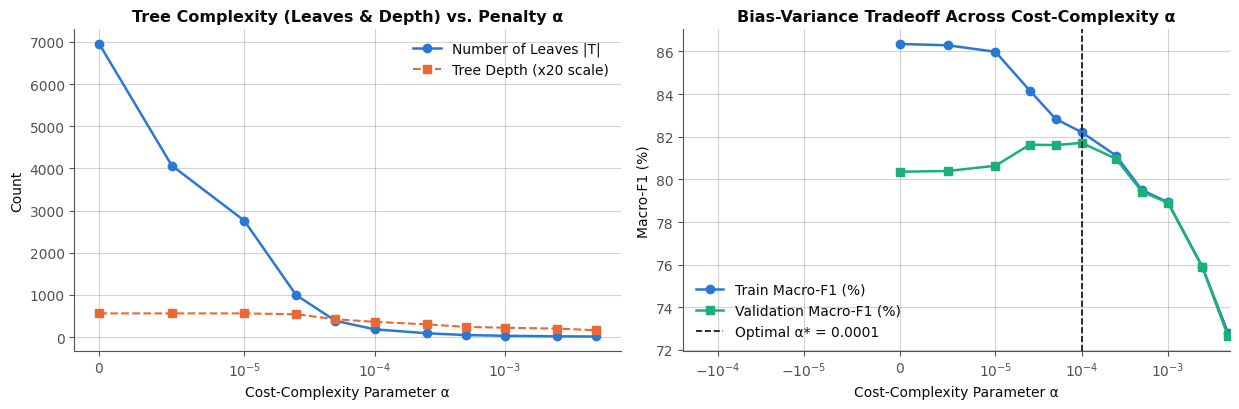

In [37]:
alpha_grid = [0.0, 5e-6, 1e-5, 2.5e-5, 5e-5, 1e-4, 2.5e-4, 5e-4, 1e-3, 2.5e-3, 5e-3]
ccp_records = []
ccp_models = {}

for a in alpha_grid:
    t0 = time.time()
    dt_ccp = DecisionTreeClassifier(
        criterion="gini", ccp_alpha=a, max_depth=28, min_samples_leaf=15,
        class_weight=CLASS_WEIGHTS, random_state=42
    )
    dt_ccp.fit(X_train_processed, y_train_idx)
    elapsed = time.time() - t0
    ccp_models[a] = (dt_ccp, elapsed)

    tr_pred = dt_ccp.predict(X_train_processed)
    va_pred = dt_ccp.predict(X_valid_processed)
    ccp_records.append({
        "alpha": a,
        "Leaves |T|": dt_ccp.get_n_leaves(),
        "Depth": dt_ccp.get_depth(),
        "Train Accuracy (%)": accuracy_score(y_train_idx, tr_pred) * 100,
        "Valid Accuracy (%)": accuracy_score(y_valid_idx, va_pred) * 100,
        "Train Macro-F1 (%)": f1_score(y_train_idx, tr_pred, average="macro") * 100,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, va_pred, average="macro") * 100
    })

ccp_df = pd.DataFrame(ccp_records)
display(ccp_df.round(3))

best_ccp_row = ccp_df.loc[ccp_df["Valid Macro-F1 (%)"].idxmax()]
BEST_ALPHA = float(best_ccp_row["alpha"])
best_dt_model, best_dt_time = ccp_models[BEST_ALPHA]

evaluate_classifier(
    f"Post-Pruned Decision Tree (α={BEST_ALPHA})",
    y_valid_idx,
    best_dt_model.predict(X_valid_processed),
    best_dt_model.predict_proba(X_valid_processed),
    best_dt_time
)

print(
    f"Selected optimal α* = {BEST_ALPHA} | Leaves |T| = {int(best_ccp_row['Leaves |T|'])} | "
    f"Depth = {int(best_ccp_row['Depth'])} | Valid Macro-F1 = {best_ccp_row['Valid Macro-F1 (%)']:.2f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].plot(ccp_df["alpha"], ccp_df["Leaves |T|"], marker="o", color="#2a78d6", lw=1.8, label="Number of Leaves |T|")
axes[0].plot(ccp_df["alpha"], ccp_df["Depth"] * 20, marker="s", color="#eb6834", lw=1.5, ls="--", label="Tree Depth (x20 scale)")
axes[0].set_xscale("symlog", linthresh=1e-5)
axes[0].set_title("Tree Complexity (Leaves & Depth) vs. Penalty α")
axes[0].set_xlabel("Cost-Complexity Parameter α")
axes[0].set_ylabel("Count")
axes[0].legend()

axes[1].plot(ccp_df["alpha"], ccp_df["Train Macro-F1 (%)"], marker="o", color="#2a78d6", lw=1.8, label="Train Macro-F1 (%)")
axes[1].plot(ccp_df["alpha"], ccp_df["Valid Macro-F1 (%)"], marker="s", color="#1baf7a", lw=1.8, label="Validation Macro-F1 (%)")
axes[1].axvline(BEST_ALPHA, color=INK, ls="--", lw=1.2, label=f"Optimal α* = {BEST_ALPHA}")
axes[1].set_xscale("symlog", linthresh=1e-5)
axes[1].set_title("Bias-Variance Tradeoff Across Cost-Complexity α")
axes[1].set_xlabel("Cost-Complexity Parameter α")
axes[1].set_ylabel("Macro-F1 (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Step 36: Naive Bayes Classifiers and Laplace Smoothing
Evaluate three Naive Bayes formulations that leverage the different representations built in Part 2:
1. **Gaussian Naive Bayes (`GaussianNB`):** Models the continuous numeric features using class-conditional Gaussian densities $g(x, \mu_{C_i}, \sigma_{C_i})$.
2. **Bernoulli Naive Bayes (`BernoulliNB`):** Operates on the binary one-hot encoded categorical block with **Laplace Smoothing ($\alpha = 1.0$, adding $+1$ virtual count)** to prevent unseen feature combinations from producing a zero posterior probability.
3. **Categorical Naive Bayes (`CategoricalNB`):** Combines the equal-frequency discretized numeric bins (`X_train_quantile_bins` from Step 29) with ordinal-encoded categorical features under Laplace correction ($\alpha = 1.0$).

In [38]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

# Identify numeric vs one-hot categorical column slices in X_train_processed
n_num_cols = len([c for c in processed_feature_names if c.startswith("numeric__")])
X_tr_num_dense = X_train_processed[:, :n_num_cols].toarray()
X_va_num_dense = X_valid_processed[:, :n_num_cols].toarray()
X_tr_cat_sparse = X_train_processed[:, n_num_cols:]
X_va_cat_sparse = X_valid_processed[:, n_num_cols:]

# 1. Gaussian Naive Bayes on continuous features
t0 = time.time()
gnb = GaussianNB(var_smoothing=1e-2)
gnb.fit(X_tr_num_dense, y_train_idx)
gnb_time = time.time() - t0
evaluate_classifier(
    "Gaussian Naive Bayes (Numeric Block)",
    y_valid_idx, gnb.predict(X_va_num_dense), gnb.predict_proba(X_va_num_dense), gnb_time
)

# 2. Bernoulli Naive Bayes on One-Hot features: compare near-zero smoothing vs Laplace (alpha=1.0)
for alpha_val, name_bnb in [(1e-10, "Bernoulli NB (Unregularized α≈0)"), (1.0, "Bernoulli NB (Laplace α=1.0)")]:
    t0 = time.time()
    bnb = BernoulliNB(alpha=alpha_val)
    bnb.fit(X_tr_cat_sparse, y_train_idx)
    bnb_time = time.time() - t0
    if alpha_val == 1.0:
        evaluate_classifier(
            name_bnb, y_valid_idx, bnb.predict(X_va_cat_sparse), bnb.predict_proba(X_va_cat_sparse), bnb_time
        )

# 3. Categorical Naive Bayes combining Step 29 Quantile Bins + Nominal Categories (Laplace alpha=1.0)
ord_enc_nb = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_tr_cat_ord = ord_enc_nb.fit_transform(X_train[categorical_features].fillna("Missing").astype(str))
X_va_cat_ord = ord_enc_nb.transform(X_valid[categorical_features].fillna("Missing").astype(str))
# Map unknown (-1) to a valid extra category index for CategoricalNB
for j in range(X_va_cat_ord.shape[1]):
    max_cat = int(X_tr_cat_ord[:, j].max()) + 1
    X_tr_cat_ord[:, j] = np.where(X_tr_cat_ord[:, j] < 0, max_cat, X_tr_cat_ord[:, j])
    X_va_cat_ord[:, j] = np.where(X_va_cat_ord[:, j] < 0, max_cat, X_va_cat_ord[:, j])

X_tr_catnb = np.hstack([X_train_quantile_bins.to_numpy(dtype=int), X_tr_cat_ord.astype(int)])
X_va_catnb = np.hstack([X_valid_quantile_bins.to_numpy(dtype=int), X_va_cat_ord.astype(int)])

t0 = time.time()
cat_nb = CategoricalNB(alpha=1.0)
cat_nb.fit(X_tr_catnb, y_train_idx)
catnb_time = time.time() - t0
evaluate_classifier(
    "Categorical NB (Discretized + Nominal, Laplace α=1.0)",
    y_valid_idx, cat_nb.predict(X_va_catnb), cat_nb.predict_proba(X_va_catnb), catnb_time
)

nb_summary = [r for r in MODEL_RESULTS if "NB" in r["Model"] or "Naive Bayes" in r["Model"]]
display(pd.DataFrame(nb_summary).set_index("Model").round(2))

,Accuracy (%),Error Rate (%),Macro Precision (%),Macro Recall / Sensitivity (%),Macro Specificity (%),Macro F1 (%),Macro F2 (%),Weighted F1 (%),Casual Labour Recall (%),Macro ROC-AUC (%),Train Time (s)
Model,,,,,,,,,,,
Gaussian Naive Bayes (Numeric Block),53.38,46.62,51.23,54.68,75.87,51.46,53.00,53.30,55.52,72.81,0.08
Bernoulli NB (Laplace α=1.0),76.33,23.67,76.83,77.45,87.22,76.64,77.01,76.38,79.24,90.43,0.10
"Categorical NB (Discretized + Nominal, Laplace α=1.0)",78.31,21.69,77.87,78.92,88.22,78.21,78.59,78.36,79.98,91.52,0.19


### Step 37: Support Vector Machines — Linear Margin Classifier, Kernel Trick (Polynomial vs. RBF) & Support Vector Bound
1. **Linear SVM vs. Logistic Regression:** Train a full-sample Linear SVM ($\min \frac{1}{2}\|\mathbf{w}\|^2 + C\sum \xi_i$, Hinge loss) across regularization parameter $C \in \{0.1, 1.0, 10.0\}$ and compare it with Multinomial Logistic Regression (Log loss).
2. **Nonlinear Kernel SVMs (Polynomial vs. RBF) & Support Vector Bound:** Use the stratified training sample from Step 31 ($N = 25,014$) to compare a **Polynomial Kernel ($d=2$)** and **RBF Kernel ($K(\mathbf{x}, \mathbf{p}) = e^{-\gamma \|\mathbf{x}-\mathbf{p}\|^2}$)** across $\gamma$, and compute the **Support Vector Ratio ($\# \text{SV} / N$)** that bounds the leave-one-out expected error.

In [39]:
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

# 1. Full-dataset Linear SVM (Hinge Loss) across C parameter & Logistic Regression (Log Loss)
c_rows = []
for c_val in [0.1, 1.0, 10.0]:
    t0 = time.time()
    lsvc = LinearSVC(C=c_val, class_weight=CLASS_WEIGHTS, max_iter=1500, random_state=42)
    lsvc.fit(X_train_processed, y_train_idx)
    pred_l = lsvc.predict(X_valid_processed)
    c_rows.append({
        "Linear SVM C": c_val,
        "Valid Accuracy (%)": accuracy_score(y_valid_idx, pred_l) * 100,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, pred_l, average="macro") * 100,
        "Casual Recall (%)": recall_score(y_valid_idx, pred_l, average=None)[2] * 100,
        "Fit Time (s)": time.time() - t0
    })
display(pd.DataFrame(c_rows).set_index("Linear SVM C").round(2))

# Fit calibrated Linear SVM (C=1.0) and Multinomial Logistic Regression on full training set
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(LinearSVC(C=1.0, class_weight=CLASS_WEIGHTS, random_state=42), cv=3)
cal_lsvc.fit(X_train_processed, y_train_idx)
lsvc_time = time.time() - t0
evaluate_classifier(
    "Linear SVM (Hinge Loss, C=1.0)",
    y_valid_idx, cal_lsvc.predict(X_valid_processed), cal_lsvc.predict_proba(X_valid_processed), lsvc_time
)

t0 = time.time()
logreg = LogisticRegression(C=1.0, class_weight=CLASS_WEIGHTS, max_iter=400, n_jobs=-1, random_state=42)
logreg.fit(X_train_processed, y_train_idx)
lr_time = time.time() - t0
evaluate_classifier(
    "Logistic Regression (Log Loss, C=1.0)",
    y_valid_idx, logreg.predict(X_valid_processed), logreg.predict_proba(X_valid_processed), lr_time
)

# 2. Nonlinear Kernel SVMs (Polynomial d=2 vs RBF Kernel) on Step 31 Stratified Sample (N=25,014)
X_samp_proc = preprocessor.transform(stratified_sample[feature_columns])
y_samp_idx = stratified_sample["target"].map(CLASS_TO_IDX).to_numpy()
N_samp = len(y_samp_idx)

kernel_configs = [
    ("Polynomial Kernel (degree=2, C=1.0)", SVC(kernel="poly", degree=2, C=1.0, class_weight=CLASS_WEIGHTS, probability=True, random_state=42)),
    ("RBF Kernel (gamma='scale', C=1.0)", SVC(kernel="rbf", gamma="scale", C=1.0, class_weight=CLASS_WEIGHTS, probability=True, random_state=42)),
    ("RBF Kernel (gamma=0.5, High γ)", SVC(kernel="rbf", gamma=0.5, C=1.0, class_weight=CLASS_WEIGHTS, probability=False, random_state=42))
]

sv_rows = []
for k_name, svm_clf in kernel_configs:
    t0 = time.time()
    svm_clf.fit(X_samp_proc, y_samp_idx)
    k_time = time.time() - t0
    va_pred = svm_clf.predict(X_valid_processed)
    n_sv = int(svm_clf.n_support_.sum())
    sv_ratio = n_sv / N_samp * 100
    va_err = (1.0 - accuracy_score(y_valid_idx, va_pred)) * 100
    sv_rows.append({
        "Kernel Configuration (N=25,014)": k_name,
        "Total Support Vectors": n_sv,
        "SV Ratio (#SV / N %)": sv_ratio,
        "Observed Valid Error (%)": va_err,
        "Valid Accuracy (%)": 100.0 - va_err,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, va_pred, average="macro") * 100,
        "Fit Time (s)": k_time
    })
    if "gamma='scale'" in k_name:
        evaluate_classifier(
            "RBF Kernel SVM (C=1.0, γ=scale)",
            y_valid_idx, va_pred, svm_clf.predict_proba(X_valid_processed), k_time
        )

display(pd.DataFrame(sv_rows).set_index("Kernel Configuration (N=25,014)").round(2))

,Valid Accuracy (%),Valid Macro-F1 (%),Casual Recall (%),Fit Time (s)
Linear SVM C,,,,
0.10,80.51,80.02,81.00,15.12
1.00,80.51,80.02,81.00,15.64
10.00,80.51,80.02,81.00,15.95


,Total Support Vectors,SV Ratio (#SV / N %),Observed Valid Error (%),Valid Accuracy (%),Valid Macro-F1 (%),Fit Time (s)
"Kernel Configuration (N=25,014)",,,,,,
"Polynomial Kernel (degree=2, C=1.0)",10704,42.79,17.30,82.70,82.04,208.22
"RBF Kernel (gamma='scale', C=1.0)",10730,42.90,16.84,83.16,82.62,213.47
"RBF Kernel (gamma=0.5, High γ)",20476,81.86,18.53,81.47,80.21,232.85


### Step 38: Multilayer Perceptron (MLP Neural Network) & Feature Representation Comparison
1. **Multilayer Perceptron Architecture:** Train a 3-layer Feedforward Neural Network (`128 -> 64 -> 3`) using **ReLU** hidden activations (preventing the vanishing gradient saturation of Sigmoid/Tanh), a **Softmax** 3-class output layer, $L_2$ weight regularization ($\alpha = 10^{-4}$), and mini-batch Adam backpropagation with validation early stopping.
2. **Comparing Alternative Representations from Steps 28–30:** Compare model accuracy when trained on the **Main Full Matrix (99 features)** vs. the **PCA-Reduced Numeric + Categorical Matrix (97 features)**.

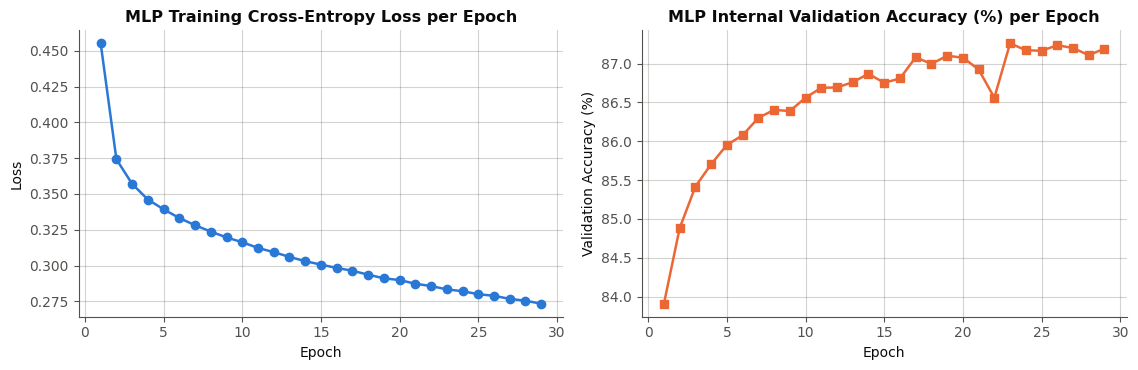

,Total Columns,Valid Accuracy (%),Valid Macro-F1 (%)
Feature Representation,,,
Main Matrix (8 Robust-Scaled Numeric + One-Hot),99,80.01,79.27
PCA-Reduced Matrix (6 Numeric PCs >=95% Var + One-Hot),96,79.97,79.30


In [40]:
from sklearn.neural_network import MLPClassifier

# 1. Train Multilayer Perceptron (ReLU hidden layers + Softmax output + L2 weight penalty)
t0 = time.time()
mlp_clf = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=35,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42
)
mlp_clf.fit(X_train_processed, y_train_idx)
mlp_time = time.time() - t0

evaluate_classifier(
    "Neural Network (MLP 128-64, ReLU+Softmax)",
    y_valid_idx,
    mlp_clf.predict(X_valid_processed),
    mlp_clf.predict_proba(X_valid_processed),
    mlp_time
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(range(1, len(mlp_clf.loss_curve_) + 1), mlp_clf.loss_curve_, marker="o", color="#2a78d6", lw=1.8)
axes[0].set_title("MLP Training Cross-Entropy Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(range(1, len(mlp_clf.validation_scores_) + 1), np.array(mlp_clf.validation_scores_) * 100, marker="s", color="#eb6834", lw=1.8)
axes[1].set_title("MLP Internal Validation Accuracy (%) per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy (%)")
plt.tight_layout()
plt.show()

# 2. Compare Step 28 Main Representation vs Step 30 PCA Representation on Logistic Regression
X_tr_pca_full = sparse.hstack([sparse.csr_matrix(X_train_pca), X_tr_cat_sparse]).tocsr()
X_va_pca_full = sparse.hstack([sparse.csr_matrix(X_valid_pca), X_va_cat_sparse]).tocsr()

lr_pca = LogisticRegression(C=1.0, class_weight=CLASS_WEIGHTS, max_iter=400, n_jobs=-1, random_state=42)
lr_pca.fit(X_tr_pca_full, y_train_idx)
pred_pca = lr_pca.predict(X_va_pca_full)

rep_comp = pd.DataFrame([
    {
        "Feature Representation": "Main Matrix (8 Robust-Scaled Numeric + One-Hot)",
        "Total Columns": X_train_processed.shape[1],
        "Valid Accuracy (%)": accuracy_score(y_valid_idx, MODEL_PREDS["Logistic Regression (Log Loss, C=1.0)"]) * 100,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, MODEL_PREDS["Logistic Regression (Log Loss, C=1.0)"], average="macro") * 100
    },
    {
        "Feature Representation": "PCA-Reduced Matrix (6 Numeric PCs >=95% Var + One-Hot)",
        "Total Columns": X_tr_pca_full.shape[1],
        "Valid Accuracy (%)": accuracy_score(y_valid_idx, pred_pca) * 100,
        "Valid Macro-F1 (%)": f1_score(y_valid_idx, pred_pca, average="macro") * 100
    }
]).set_index("Feature Representation")
display(rep_comp.round(2))

### Step 39: Ensemble Methods — Bagging (Random Forest), Boosting (HistGBM), and Soft Voting Ensemble
Construct composite ensemble classifiers to reduce variance and bias simultaneously:
1. **Random Forest (`RandomForestClassifier`):** Parallel bootstrap aggregation (bagging) of 150 independent trees with random feature subsampling to decorrelate base-tree errors.
2. **Histogram Gradient Boosting (`HistGradientBoostingClassifier`):** Sequential additive trees trained with sample weights to correct predecessor errors.
3. **Soft Voting Ensemble:** Averages calibrated class probability distributions across three diverse paradigms (**Random Forest + Gradient Boosting + MLP Neural Network**).

In [42]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Convert sparse matrices to compact float32 dense arrays for HistGradientBoostingClassifier
X_train_dense = X_train_processed.toarray().astype(np.float32)
X_valid_dense = X_valid_processed.toarray().astype(np.float32)

# 1. Random Forest (Bagging 150 independent decision trees)
t0 = time.time()
rf_clf = RandomForestClassifier(
    n_estimators=150, max_depth=20, min_samples_leaf=10,
    class_weight=CLASS_WEIGHTS, n_jobs=-1, random_state=42
)
rf_clf.fit(X_train_processed, y_train_idx)
rf_time = time.time() - t0
rf_proba = rf_clf.predict_proba(X_valid_processed)
evaluate_classifier(
    "Random Forest (150 Trees, Bagging)",
    y_valid_idx, rf_clf.predict(X_valid_processed), rf_proba, rf_time
)

# 2. Histogram Gradient Boosting (Sequential Boosting with balanced sample weights)
t0 = time.time()
hgb_clf = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.08, max_leaf_nodes=63,
    min_samples_leaf=30, random_state=42
)
hgb_clf.fit(X_train_dense, y_train_idx, sample_weight=sample_weight_train)
hgb_time = time.time() - t0
hgb_proba = hgb_clf.predict_proba(X_valid_dense)
evaluate_classifier(
    "Gradient Boosting (HistGBM, Balanced)",
    y_valid_idx, hgb_clf.predict(X_valid_dense), hgb_proba, hgb_time
)

# 3. Soft Voting Ensemble combining Random Forest + HistGBM + MLP Neural Network probabilities
ens_proba = (rf_proba + hgb_proba + MODEL_PROBAS["Neural Network (MLP 128-64, ReLU+Softmax)"]) / 3.0
ens_pred = np.argmax(ens_proba, axis=1)
evaluate_classifier(
    "Soft Voting Ensemble (RF + HistGBM + MLP)",
    y_valid_idx, ens_pred, ens_proba, rf_time + hgb_time + mlp_time
)

# Display master leaderboard sorted by Validation Macro-F1
leaderboard_df = pd.DataFrame(MODEL_RESULTS).drop_duplicates(subset=["Model"], keep="last").set_index("Model")
leaderboard_df = leaderboard_df.sort_values("Macro F1 (%)", ascending=False)
display(leaderboard_df.round(2))

,Accuracy (%),Error Rate (%),Macro Precision (%),Macro Recall / Sensitivity (%),Macro Specificity (%),Macro F1 (%),Macro F2 (%),Weighted F1 (%),Casual Labour Recall (%),Macro ROC-AUC (%),Train Time (s)
Model,,,,,,,,,,,
Soft Voting Ensemble (RF + HistGBM + MLP),86.12,13.88,85.43,85.88,92.39,85.64,85.78,86.13,85.04,96.27,455.42
"Neural Network (MLP 128-64, ReLU+Softmax)",85.35,14.65,85.82,84.12,91.70,84.92,84.43,85.33,80.44,95.91,81.61
"Gradient Boosting (HistGBM, Balanced)",85.51,14.49,83.95,86.00,92.26,84.87,85.52,85.55,87.62,96.21,91.34
"Random Forest (150 Trees, Bagging)",83.69,16.31,82.32,84.32,91.33,83.13,83.80,83.75,85.61,95.34,282.47
"RBF Kernel SVM (C=1.0, γ=scale)",83.16,16.84,81.74,83.82,91.01,82.62,83.30,83.22,85.47,94.77,213.47
Post-Pruned Decision Tree (α=0.0001),82.23,17.77,80.88,82.86,90.48,81.71,82.36,82.29,84.48,94.02,22.59
"DT (Pre-pruned d=12, Gini, Balanced)",81.03,18.97,80.03,82.10,90.00,80.61,81.40,81.09,84.06,93.79,4.83
"Linear SVM (Hinge Loss, C=1.0)",80.66,19.34,80.86,80.05,89.28,80.38,80.16,80.70,77.59,93.23,31.62
"Logistic Regression (Log Loss, C=1.0)",80.01,19.99,77.95,81.19,89.43,79.27,80.34,80.10,85.20,93.35,9.80


### Step 40: Detailed Confusion Matrix, One-vs-All Specificity, $F_\beta$ Scores, and Multiclass ROC/AUC Analysis
Analyze the top-performing classifier using:
* **One-vs-All Confusion Matrix Decomposition:** True Positives ($\text{TP}$), False Negatives ($\text{FN}$), False Positives ($\text{FP}$), True Negatives ($\text{TN}$), **Precision**, **Sensitivity (Recall)**, **Specificity ($\text{TN}/\text{N}$)**, **$F_{0.5}$** (precision-weighted), **$F_1$**, and **$F_2$** (recall-weighted).
* **Multiclass ROC Curves:** Decompose the 3-class problem via the **One-vs-Rest (OvR)** scheme, plotting $\text{TPR}$ vs. $\text{FPR}$ across thresholds $t \in [0, 1]$ alongside Macro-Average and Micro-Average ROC curves.

One-vs-All Confusion Metrics for Soft Voting Ensemble (RF + HistGBM + MLP):


,TP,FN,FP,TN,Precision (%),Sensitivity / Recall (%),Specificity TN/N (%),F0.5 (%),F1 (%),F2 (%)
Class,,,,,,,,,,
Self-employed,25936,4117,3233,30325,88.92,86.30,90.37,88.38,87.59,86.81
Regular salaried,21051,3344,4065,35151,83.82,86.29,89.63,84.30,85.04,85.79
Casual labour,7792,1371,1534,52914,83.55,85.04,97.18,83.84,84.29,84.74


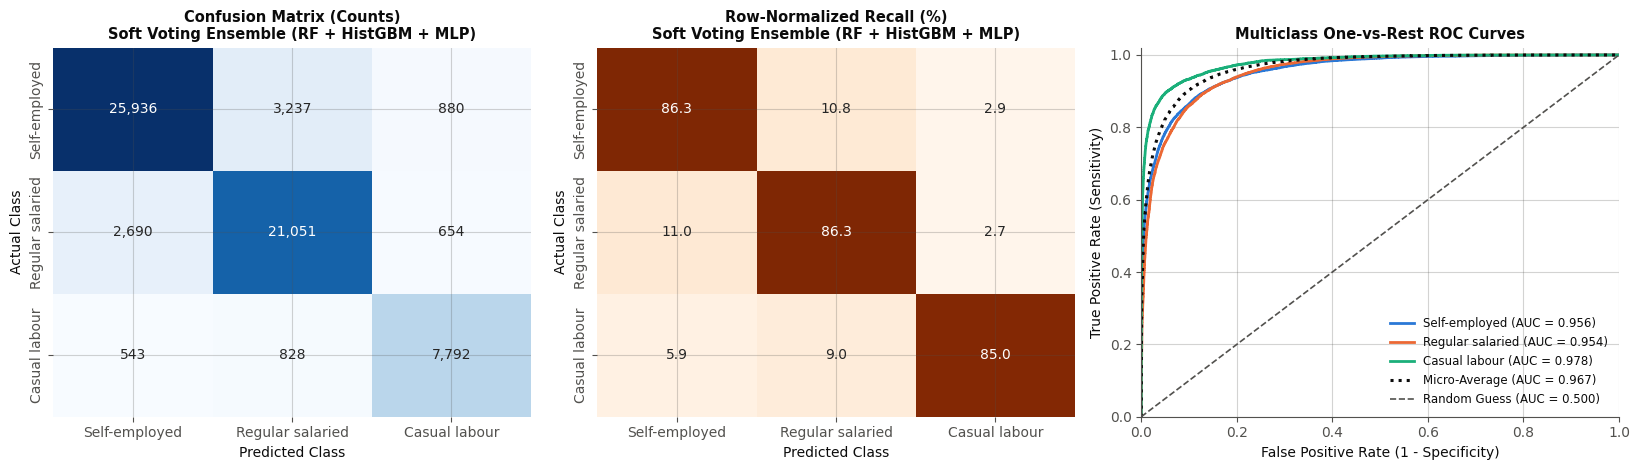

In [43]:
best_model_name = leaderboard_df.index[0]
best_pred = MODEL_PREDS[best_model_name]
best_proba = MODEL_PROBAS[best_model_name]
cm_best = confusion_matrix(y_valid_idx, best_pred, labels=[0, 1, 2])

# 1. Per-class One-vs-All Confusion Matrix table
ova_rows = []
for idx, cls_name in enumerate(CLASSES):
    tp = int(cm_best[idx, idx])
    fn = int(cm_best[idx, :].sum() - tp)
    fp = int(cm_best[:, idx].sum() - tp)
    tn = int(cm_best.sum() - (tp + fn + fp))
    prec = tp / (tp + fp) * 100
    sens = tp / (tp + fn) * 100
    spec = tn / (tn + fp) * 100
    f05 = (1 + 0.5**2) * prec * sens / ((0.5**2) * prec + sens)
    f1 = 2 * prec * sens / (prec + sens)
    f2 = (1 + 2.0**2) * prec * sens / ((2.0**2) * prec + sens)
    ova_rows.append({
        "Class": cls_name,
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "Precision (%)": prec,
        "Sensitivity / Recall (%)": sens,
        "Specificity TN/N (%)": spec,
        "F0.5 (%)": f05,
        "F1 (%)": f1,
        "F2 (%)": f2
    })

print(f"One-vs-All Confusion Metrics for {best_model_name}:")
display(pd.DataFrame(ova_rows).set_index("Class").round(2))

# 2. Plot Confusion Matrix (Counts & Row-Normalized %) and Multiclass OvR ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

sns.heatmap(
    cm_best, annot=True, fmt=",d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False
)
axes[0].set_title(f"Confusion Matrix (Counts)\n{best_model_name}", fontsize=10.5)
axes[0].set_xlabel("Predicted Class"); axes[0].set_ylabel("Actual Class")

cm_norm = cm_best / cm_best.sum(axis=1, keepdims=True) * 100
sns.heatmap(
    cm_norm, annot=True, fmt=".1f", cmap="Oranges",
    xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False
)
axes[1].set_title(f"Row-Normalized Recall (%)\n{best_model_name}", fontsize=10.5)
axes[1].set_xlabel("Predicted Class"); axes[1].set_ylabel("Actual Class")

for i, cls_name in enumerate(CLASSES):
    fpr_i, tpr_i, _ = roc_curve(y_valid_bin[:, i], best_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    axes[2].plot(fpr_i, tpr_i, color=CLS_COL[cls_name], lw=2.0, label=f"{cls_name} (AUC = {auc_i:.3f})")

fpr_mic, tpr_mic, _ = roc_curve(y_valid_bin.ravel(), best_proba.ravel())
axes[2].plot(fpr_mic, tpr_mic, color=INK, ls=":", lw=2.2, label=f"Micro-Average (AUC = {auc(fpr_mic, tpr_mic):.3f})")
axes[2].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1.2, label="Random Guess (AUC = 0.500)")
axes[2].set_xlim(0.0, 1.0); axes[2].set_ylim(0.0, 1.02)
axes[2].set_title("Multiclass One-vs-Rest ROC Curves", fontsize=10.5)
axes[2].set_xlabel("False Positive Rate (1 - Specificity)")
axes[2].set_ylabel("True Positive Rate (Sensitivity)")
axes[2].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

### Step 41: 5-Fold Stratified Group Cross-Validation and Pairwise $t$-Tests of Statistical Significance
To confirm that differences in error rates between models are not due to random split variance, evaluate four representative classifiers across the exact same $k = 5$ household-grouped stratified folds (`StratifiedGroupKFold(n_splits=5)`) and compute the paired Student's $t$-statistic with $k - 1 = 4$ degrees of freedom:
$$t = \frac{\overline{\text{err}}(M_1) - \overline{\text{err}}(M_2)}{\sqrt{\text{var}(M_1 - M_2) / k}}$$

In [44]:
# Use a 15,000-household subset of the training partition for 5-fold CV comparison
cv_rng = np.random.default_rng(42)
sampled_hh = cv_rng.choice(groups_train.unique(), size=15000, replace=False)
cv_mask = groups_train.isin(sampled_hh).to_numpy()

X_cv_mat = X_train_processed[cv_mask]
X_cv_dense = X_cv_mat.toarray().astype(np.float32)
y_cv_vec = y_train_idx[cv_mask]
g_cv_vec = groups_train.to_numpy()[cv_mask]
w_cv_vec = sample_weight_train[cv_mask]

sgkf_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_Models = {
    "M1: Gradient Boosting (HistGBM)": lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=63, random_state=42),
    "M2: Random Forest (100 Trees)": lambda: RandomForestClassifier(n_estimators=100, max_depth=18, min_samples_leaf=10, class_weight=CLASS_WEIGHTS, n_jobs=-1, random_state=42),
    "M3: Post-Pruned Decision Tree": lambda: DecisionTreeClassifier(criterion="gini", ccp_alpha=BEST_ALPHA, max_depth=25, min_samples_leaf=15, class_weight=CLASS_WEIGHTS, random_state=42),
    "M4: Linear SVM (C=1.0)": lambda: LinearSVC(C=1.0, class_weight=CLASS_WEIGHTS, max_iter=1000, random_state=42)
}

fold_err_records = {m: [] for m in cv_Models}
for fold_i, (f_tr, f_va) in enumerate(sgkf_cv.split(X_cv_mat, y_cv_vec, groups=g_cv_vec), start=1):
    for m_name, m_builder in cv_Models.items():
        clf_f = m_builder()
        if "HistGBM" in m_name:
            clf_f.fit(X_cv_dense[f_tr], y_cv_vec[f_tr], sample_weight=w_cv_vec[f_tr])
            preds_f = clf_f.predict(X_cv_dense[f_va])
        else:
            clf_f.fit(X_cv_mat[f_tr], y_cv_vec[f_tr])
            preds_f = clf_f.predict(X_cv_mat[f_va])
        err_rate = (1.0 - accuracy_score(y_cv_vec[f_va], preds_f)) * 100
        fold_err_records[m_name].append(err_rate)

cv_err_df = pd.DataFrame(fold_err_records, index=[f"Fold {i}" for i in range(1, 6)])
cv_err_df.loc["Mean Error (%)"] = cv_err_df.mean()
cv_err_df.loc["Std Dev (%)"] = cv_err_df.iloc[:5].std()
print(f"5-Fold Stratified Group Cross-Validation Error Rates (N = {len(y_cv_vec):,} records):")
display(cv_err_df.round(3))

# Paired Student's t-test against M1 (HistGBM)
k_f = 5
err_m1 = np.array(fold_err_records["M1: Gradient Boosting (HistGBM)"])
ttest_list = []
for other_name in ["M2: Random Forest (100 Trees)", "M3: Post-Pruned Decision Tree", "M4: Linear SVM (C=1.0)"]:
    err_m2 = np.array(fold_err_records[other_name])
    diff = err_m2 - err_m1
    mean_d = diff.mean()
    var_d = diff.var(ddof=1)
    t_val = mean_d / np.sqrt(var_d / k_f)
    p_two_sided = stats.t.sf(np.abs(t_val), df=k_f - 1) * 2
    ttest_list.append({
        "Comparator Model (M2)": other_name,
        "Mean Error Diff (M2 - M1 %)": mean_d,
        "t-Statistic (df=4)": t_val,
        "p-Value": p_two_sided,
        "Reject H0 at α=0.05": p_two_sided < 0.05
    })

display(pd.DataFrame(ttest_list).set_index("Comparator Model (M2)").round(5))

5-Fold Stratified Group Cross-Validation Error Rates (N = 48,999 records):


,M1: Gradient Boosting (HistGBM),M2: Random Forest (100 Trees),M3: Post-Pruned Decision Tree,M4: Linear SVM (C=1.0)
Fold 1,15.93,17.81,20.70,19.31
Fold 2,15.62,18.16,20.22,19.64
Fold 3,16.46,18.71,21.30,21.06
Fold 4,15.89,18.14,20.99,20.66
Fold 5,16.00,18.51,20.76,20.49
Mean Error (%),15.98,18.27,20.80,20.23
Std Dev (%),0.30,0.35,0.40,0.73


,Mean Error Diff (M2 - M1 %),t-Statistic (df=4),p-Value,Reject H0 at α=0.05
Comparator Model (M2),,,,
M2: Random Forest (100 Trees),2.29,19.57,0.00,True
M3: Post-Pruned Decision Tree,4.82,57.90,0.00,True
M4: Linear SVM (C=1.0),4.25,16.97,0.00,True


### Step 42: Feature Importance Ranking & Misclassification Error Analysis
Aggregate the impurity-based feature importances from the Random Forest model back to the 19 original predictors to identify which socio-economic dimensions drive the classification decisions, and inspect validation accuracy and error rates across the 10 broad industry groups.

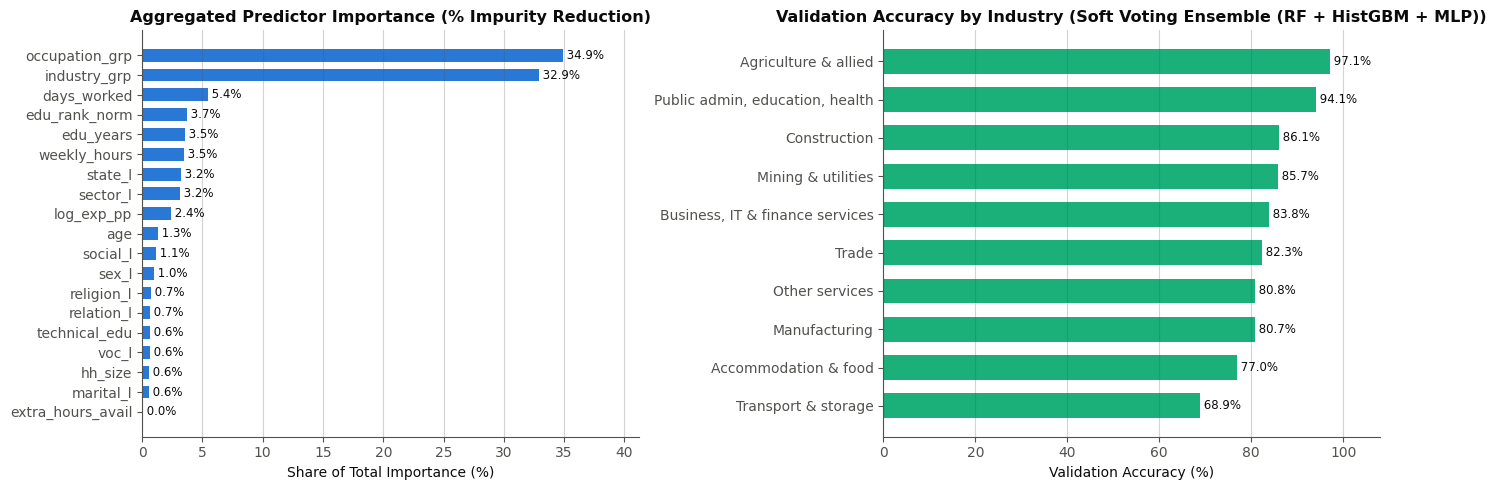

Aggregated Feature Importance Table:


,Importance (%)
occupation_grp,34.93
industry_grp,32.91
days_worked,5.44
edu_rank_norm,3.67
edu_years,3.52
weekly_hours,3.50
state_l,3.22
sector_l,3.16
log_exp_pp,2.39
age,1.29



Validation Accuracy & Error Rate by Industry Group:


,Validation_Records,Accuracy_Pct,Error_Rate_Pct
industry_grp,,,
Transport & storage,4144,68.94,31.06
Accommodation & food,1720,76.98,23.02
Manufacturing,9521,80.73,19.27
Other services,3379,80.79,19.21
Trade,11035,82.32,17.68
"Business, IT & finance services",4658,83.83,16.17
Mining & utilities,1031,85.74,14.26
Construction,6988,86.15,13.85
"Public admin, education, health",7853,94.09,5.91


In [45]:
# 1. Aggregate one-hot encoded feature importances back to their 19 parent predictors
raw_imp = rf_clf.feature_importances_
grouped_imp = {}

for fname, imp_val in zip(processed_feature_names, raw_imp):
    if fname.startswith("numeric__"):
        base_col = fname.replace("numeric__missingindicator_", "").replace("numeric__", "")
    elif fname.startswith("categorical__"):
        rest = fname.replace("categorical__", "")
        matched = [c for c in categorical_features if rest.startswith(c + "_")]
        base_col = matched[0] if matched else rest
    else:
        base_col = fname
    grouped_imp[base_col] = grouped_imp.get(base_col, 0.0) + float(imp_val)

imp_series = (pd.Series(grouped_imp) * 100).sort_values()

# 2. Validation Accuracy & Error Rate by Industry Sector for the Top Classifier
err_by_ind = pd.DataFrame({
    "industry_grp": X_valid["industry_grp"].fillna("Missing").values,
    "correct": (y_valid_idx == best_pred).astype(int)
}).groupby("industry_grp").agg(
    Validation_Records=("correct", "size"),
    Accuracy_Pct=("correct", lambda s: s.mean() * 100),
    Error_Rate_Pct=("correct", lambda s: (1.0 - s.mean()) * 100)
).sort_values("Accuracy_Pct")

# 3. Plot Side-by-Side Feature Importance and Industry-Wise Validation Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

axes[0].barh(imp_series.index, imp_series.values, color="#2a78d6", height=0.65)
for y_pos, val in enumerate(imp_series.values):
    axes[0].text(val, y_pos, f" {val:.1f}%", va="center", fontsize=8.5)
axes[0].set_xlim(0, imp_series.max() * 1.18)
axes[0].set_title("Aggregated Predictor Importance (% Impurity Reduction)")
axes[0].set_xlabel("Share of Total Importance (%)")
axes[0].grid(axis="y", visible=False)

axes[1].barh(err_by_ind.index, err_by_ind["Accuracy_Pct"], color="#1baf7a", height=0.65)
for y_pos, val in enumerate(err_by_ind["Accuracy_Pct"]):
    axes[1].text(val, y_pos, f" {val:.1f}%", va="center", fontsize=8.5)
axes[1].set_xlim(0, 108)
axes[1].set_title(f"Validation Accuracy by Industry ({best_model_name})")
axes[1].set_xlabel("Validation Accuracy (%)")
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

print("Aggregated Feature Importance Table:")
display(imp_series.sort_values(ascending=False).rename("Importance (%)").to_frame().round(2))

print("\nValidation Accuracy & Error Rate by Industry Group:")
display(err_by_ind.round(2))

### Step 43: Comparing Alternative Representations (Discretized & PCA vs. Main Matrix) and Master Visual Leaderboard
In Steps 28–30, three distinct feature representations were constructed:
1. **Main Continuous + One-Hot Matrix (`X_train_processed`, 99 features)**
2. **PCA-Reduced Numeric + One-Hot Matrix (`X_train_pca` + categorical block, 97 features)**
3. **Discretized Quantile-Binned Numeric + One-Hot Matrix (`X_train_quantile_bins` + categorical block)**

Compare these three representations using the same classifiers, then plot the master visual comparison of all trained classifiers across **Accuracy**, **Macro-$F_1$**, **Casual Labour Recall**, and **Macro ROC-AUC**.

Comparison of Alternative Feature Representations (Steps 28–30):


,Features,LogReg Accuracy (%),LogReg Macro-F1 (%),Pruned DT Accuracy (%),Pruned DT Macro-F1 (%)
Representation,,,,,
1. Main Matrix (Robust-Scaled Numeric + One-Hot),99,80.01,79.27,82.23,81.71
2. PCA Matrix (6 Numeric PCs >=95% Var + One-Hot),96,79.97,79.30,81.95,81.37
3. Discretized Matrix (Quantile-Binned + One-Hot),110,80.40,79.68,81.80,81.35


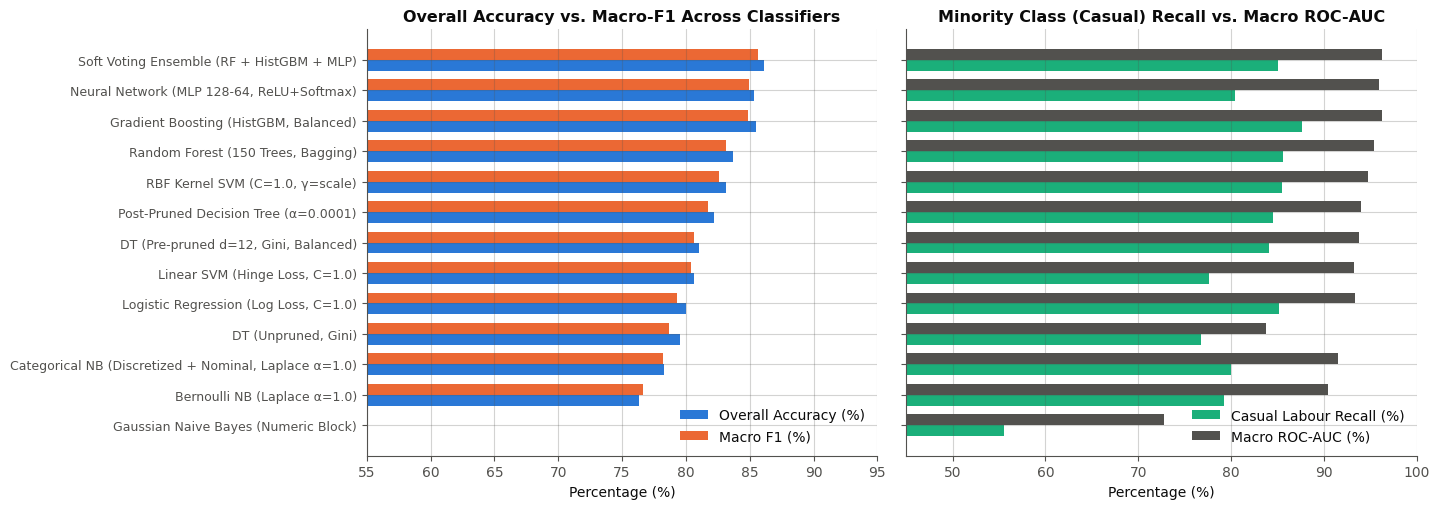

In [46]:
# 1. Compare the 3 preprocessing representations from Steps 28-30 using Logistic Regression & Decision Tree
ohe_bins = make_one_hot_encoder()
X_tr_qbins_ohe = ohe_bins.fit_transform(X_train_quantile_bins)
X_va_qbins_ohe = ohe_bins.transform(X_valid_quantile_bins)

# Keep remaining numeric features not in discretize_features alongside the discretized bins
rem_num_cols = [i for i, c in enumerate(numeric_features) if c not in discretize_features]
X_tr_rem_num = X_train_processed[:, rem_num_cols]
X_va_rem_num = X_valid_processed[:, rem_num_cols]

X_tr_disc_full = sparse.hstack([X_tr_rem_num, X_tr_qbins_ohe, X_tr_cat_sparse]).tocsr()
X_va_disc_full = sparse.hstack([X_va_rem_num, X_va_qbins_ohe, X_va_cat_sparse]).tocsr()

rep_experiments = [
    ("1. Main Matrix (Robust-Scaled Numeric + One-Hot)", X_train_processed, X_valid_processed),
    ("2. PCA Matrix (6 Numeric PCs >=95% Var + One-Hot)", X_tr_pca_full, X_va_pca_full),
    ("3. Discretized Matrix (Quantile-Binned + One-Hot)", X_tr_disc_full, X_va_disc_full)
]

rep_rows = []
for rep_name, X_tr_r, X_va_r in rep_experiments:
    lr_r = LogisticRegression(C=1.0, class_weight=CLASS_WEIGHTS, max_iter=400, n_jobs=-1, random_state=42)
    lr_r.fit(X_tr_r, y_train_idx)
    p_lr = lr_r.predict(X_va_r)

    dt_r = DecisionTreeClassifier(criterion="gini", ccp_alpha=BEST_ALPHA, max_depth=22, min_samples_leaf=15, class_weight=CLASS_WEIGHTS, random_state=42)
    dt_r.fit(X_tr_r, y_train_idx)
    p_dt = dt_r.predict(X_va_r)

    rep_rows.append({
        "Representation": rep_name,
        "Features": X_tr_r.shape[1],
        "LogReg Accuracy (%)": accuracy_score(y_valid_idx, p_lr) * 100,
        "LogReg Macro-F1 (%)": f1_score(y_valid_idx, p_lr, average="macro") * 100,
        "Pruned DT Accuracy (%)": accuracy_score(y_valid_idx, p_dt) * 100,
        "Pruned DT Macro-F1 (%)": f1_score(y_valid_idx, p_dt, average="macro") * 100
    })

print("Comparison of Alternative Feature Representations (Steps 28–30):")
display(pd.DataFrame(rep_rows).set_index("Representation").round(2))

# 2. Visual Leaderboard Across All Trained Classifiers
plot_lb = leaderboard_df.sort_values("Macro F1 (%)", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2), sharey=True)
y_idx = np.arange(len(plot_lb))
bar_h = 0.36

axes[0].barh(y_idx - bar_h/2, plot_lb["Accuracy (%)"], height=bar_h, color="#2a78d6", label="Overall Accuracy (%)")
axes[0].barh(y_idx + bar_h/2, plot_lb["Macro F1 (%)"], height=bar_h, color="#eb6834", label="Macro F1 (%)")
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(plot_lb.index, fontsize=9)
axes[0].set_xlim(55, 95)
axes[0].set_xlabel("Percentage (%)")
axes[0].set_title("Overall Accuracy vs. Macro-F1 Across Classifiers")
axes[0].legend(loc="lower right")

axes[1].barh(y_idx - bar_h/2, plot_lb["Casual Labour Recall (%)"], height=bar_h, color="#1baf7a", label="Casual Labour Recall (%)")
axes[1].barh(y_idx + bar_h/2, plot_lb["Macro ROC-AUC (%)"], height=bar_h, color="#52514e", label="Macro ROC-AUC (%)")
axes[1].set_xlim(45, 100)
axes[1].set_xlabel("Percentage (%)")
axes[1].set_title("Minority Class (Casual) Recall vs. Macro ROC-AUC")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Step 44: Save Validation Predictions and Final Project Summary
Export the validation predictions and class probabilities of the top-performing classifier, and print a single summary card of the complete pipeline (from the 923,985 raw survey records to the final model evaluation).

In [47]:
# Save validation predictions and probabilities for audit / reporting
valid_out = X_valid[["sector_l", "state_l", "sex_l", "age", "edu_years", "industry_grp", "occupation_grp"]].copy()
valid_out["actual_target"] = y_valid.values
valid_out["predicted_target"] = [CLASSES[i] for i in best_pred]
for i, cls_name in enumerate(CLASSES):
    valid_out[f"prob_{cls_name}"] = np.round(best_proba[:, i], 4)

valid_out.to_csv("plfs_validation_predictions.csv", index=False)

best_row = leaderboard_df.iloc[0]
summary_card = pd.DataFrame({
    "Pipeline Stage": [
        "1. Raw PLFS Person Records (First Visit + Revisit)",
        "2. Modelling Population (Employed, Aged 15+)",
        "3. Distinct Households (Grouped Split on hh_id)",
        "4. Training Partition / Validation Partition",
        "5. Household Overlap Between Train & Validation",
        "6. Encoded Feature Matrix Columns (RobustScaler + One-Hot)",
        "7. Optimal Decision Tree Pruning Parameter (α*)",
        "8. Top-Performing Classifier",
        "9. Top Model Validation Accuracy / Error Rate",
        "10. Top Model Validation Macro-F1 / Weighted-F1",
        "11. Top Model Casual Labour Recall / Macro Specificity",
        "12. Top Model Multiclass Macro ROC-AUC",
        "13. Saved Predictions File"
    ],
    "Result": [
        "923,985 person records (230,231 household records)",
        f"{len(model_df):,} employed persons",
        f"{model_df['hh_id'].nunique():,} households",
        f"{len(X_train):,} train rows / {len(X_valid):,} validation rows",
        "0 households (Zero panel leakage)",
        f"{X_train_processed.shape[1]} features (sparse CSR)",
        f"α* = {BEST_ALPHA} ({best_dt_model.get_n_leaves()} leaves, depth {best_dt_model.get_depth()})",
        best_model_name,
        f"{best_row['Accuracy (%)']:.2f}% / {best_row['Error Rate (%)']:.2f}%",
        f"{best_row['Macro F1 (%)']:.2f}% / {best_row['Weighted F1 (%)']:.2f}%",
        f"{best_row['Casual Labour Recall (%)']:.2f}% / {best_row['Macro Specificity (%)']:.2f}%",
        f"{best_row['Macro ROC-AUC (%)']:.2f}%",
        "plfs_validation_predictions.csv"
    ]
})

display(summary_card.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Pipeline Stage,Result
1. Raw PLFS Person Records (First Visit + Revisit),"923,985 person records (230,231 household records)"
"2. Modelling Population (Employed, Aged 15+)","313,759 employed persons"
3. Distinct Households (Grouped Split on hh_id),"95,624 households"
4. Training Partition / Validation Partition,"250,148 train rows / 63,611 validation rows"
5. Household Overlap Between Train & Validation,0 households (Zero panel leakage)
6. Encoded Feature Matrix Columns (RobustScaler + One-Hot),99 features (sparse CSR)
7. Optimal Decision Tree Pruning Parameter (α*),"α* = 0.0001 (182 leaves, depth 18)"
8. Top-Performing Classifier,Soft Voting Ensemble (RF + HistGBM + MLP)
9. Top Model Validation Accuracy / Error Rate,86.12% / 13.88%
10. Top Model Validation Macro-F1 / Weighted-F1,85.64% / 86.13%
